# Segmentasi Customer dan Prediksi Proksi CLV Batu Bara B2B — v3
Versi v3 untuk `Dataset_Skripsi_Multiyear.xlsx`. Data bersifat sintetis. Jalankan dari atas; panel dibuat dari transaksi, tanpa membaca sheet Panel.

**Perubahan v3 dibanding notebook lama dan v2**
1. Split temporal v2 dengan purge saja (tanpa membuang snapshot demi rasio): Train 8.097, Validation 1.573, Test 1.572.
2. Early stopping saat tuning memakai set terpisah dari fold yang dinilai, lalu model dilatih ulang pada seluruh data latih fold (bagian 4.2).
3. Objective Tweedie menjadi kandidat tambahan untuk XGBoost dan LightGBM (bagian 4.1).
4. Uji mundur kebaruan data di Validation, pelatihan ulang Train+Validation bila terbukti membantu, dan penguncian konfigurasi dengan hash sebelum Test (bagian 5.10–5.12).
5. Log eksperimen Validation (bagian 4.0); seluruh keputusan diambil tanpa Test.

Seed seluruh proses: 20261019. Test hanya dibaca satu kali di bagian 6.1 setelah hash konfigurasi dicocokkan.

## 1 Data Understanding
### 1.1 Library

In [1]:
import importlib.util, importlib.metadata, subprocess, sys, os
# Versi acuan penelitian. XGBoost, LightGBM, dan Optuna dipasang dengan versi tetap bila berbeda;
# pandas/numpy/scikit-learn hanya diperiksa karena mengganti versinya di Colab memerlukan restart runtime.
REFERENCE_VERSIONS = {'pandas':'2.2.3','numpy':'2.1.3','scikit-learn':'1.6.1','xgboost':'3.4.1','lightgbm':'4.6.0'}
PINNED_INSTALL = {'xgboost':'3.4.1','lightgbm':'4.6.0'}
def installed(dist):
    try: return importlib.metadata.version(dist)
    except importlib.metadata.PackageNotFoundError: return None
to_install = [f'{d}=={v}' for d,v in PINNED_INSTALL.items() if installed(d)!=v]
to_install += [p for p in ['openpyxl','scipy','joblib','matplotlib','threadpoolctl'] if installed(p) is None]
if to_install:
    subprocess.check_call([sys.executable,'-m','pip','install','-q',*to_install])
INSTALL_EXACT_CORE = False   # True: pasang pandas/numpy/scikit-learn versi acuan, lalu restart runtime satu kali.
mismatch = {d:(installed(d),v) for d,v in REFERENCE_VERSIONS.items() if installed(d)!=v}
if mismatch and INSTALL_EXACT_CORE:
    subprocess.check_call([sys.executable,'-m','pip','install','-q',*[f'{d}=={v}' for d,v in REFERENCE_VERSIONS.items()]])
    print('Versi inti dipasang. Restart runtime, lalu jalankan ulang dari atas.')
elif mismatch:
    print('Perhatian, versi berbeda dari acuan (terpasang, acuan):', mismatch)
    print('Angka dapat bergeser sedikit; set INSTALL_EXACT_CORE=True untuk menyamakan versi.')
else:
    print('Seluruh versi sesuai acuan:', REFERENCE_VERSIONS)

Seluruh versi sesuai acuan: {'pandas': '2.2.3', 'numpy': '2.1.3', 'scikit-learn': '1.6.1', 'xgboost': '3.4.1', 'lightgbm': '4.6.0'}


### 1.2 Konfigurasi dan file input
Riwayat 365 hari, target enam bulan kalender, dan split temporal v2 berbasis tanggal acuan dengan purge.

In [2]:
from pathlib import Path
import json, hashlib, time, copy, warnings, shutil, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from IPython.display import display
from threadpoolctl import threadpool_limits
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, RobustScaler, PowerTransformer
from sklearn.cluster import KMeans
from sklearn.metrics import (silhouette_score, davies_bouldin_score,
    calinski_harabasz_score, adjusted_rand_score, mean_absolute_error,
    mean_squared_error, r2_score)
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.linear_model import Ridge, ElasticNet
from scipy.optimize import minimize
from xgboost import XGBRegressor
import xgboost, lightgbm as lgb, sklearn

SEED = 20261019
N_JOBS = int(os.getenv('N_JOBS', min(4, max(1, os.cpu_count() or 1))))
MODE = 'standard'       # 'thorough': lebih banyak kandidat dan epoch; atur sebelum run.
START = pd.Timestamp('2021-10-01')
CUTOFF = pd.Timestamp('2026-09-30')
HISTORY_DAYS, HORIZON, DISCOUNT = 365, 6, .10
SPLITS = ['Train', 'Validation', 'Test']
import random
random.seed(SEED); np.random.seed(SEED); os.environ['PYTHONHASHSEED'] = str(SEED)
plt.rcParams.update({'figure.dpi':110, 'font.size':10, 'axes.spines.top':False,
                     'axes.spines.right':False, 'savefig.bbox':'tight'})
pd.set_option('display.max_columns', 18)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')

DATASET_PATH = os.getenv('DATASET_PATH', '')
if DATASET_PATH:
    DATASET_PATH = Path(DATASET_PATH)
else:
    DATASET_PATH = Path('Dataset_Skripsi_Multiyear.xlsx')
    if not DATASET_PATH.exists():
        try:
            from google.colab import files
        except ImportError:
            raise FileNotFoundError('Letakkan Dataset_Skripsi_Multiyear.xlsx di folder notebook, atau isi DATASET_PATH.')
        uploaded = files.upload()
        choices = [Path(n) for n in uploaded if n.lower().endswith('.xlsx')]
        if len(choices) != 1:
            raise ValueError('Unggah satu workbook dataset penelitian.')
        DATASET_PATH = choices[0]
DATASET_SHA256 = hashlib.sha256(DATASET_PATH.read_bytes()).hexdigest()
RUN_DIR = Path(os.getenv('THESIS_OUTPUT_ROOT', 'hasil_skripsi_v3')) / f'{DATASET_SHA256[:10]}_{MODE}_v3'
for sub in ['data_understanding','data_preparation','segmentation','models','stacking','evaluation','customer_profile','export']:
    (RUN_DIR/sub).mkdir(parents=True, exist_ok=True)
def save_table(df, name, folder='data_preparation'):
    df.to_csv(RUN_DIR/folder/f'{name}.csv', index=False)
def finish_plot(name, folder):
    plt.savefig(RUN_DIR/folder/f'{name}.png', dpi=160)
    plt.show(); plt.close()
def write_json(obj, path):
    Path(path).write_text(json.dumps(obj, indent=2, default=str), encoding='utf-8')
versions = {m.__name__:m.__version__ for m in [pd,np,sklearn,xgboost,lgb]}
print('File:', DATASET_PATH.name)
print('Mode:', MODE, '| Versi:', versions)

File: Dataset_Skripsi_Multiyear.xlsx
Mode: standard | Versi: {'pandas': '2.2.3', 'numpy': '2.1.3', 'sklearn': '1.6.1', 'xgboost': '3.4.1', 'lightgbm': '4.6.0'}


### 1.3 Baca data sumber
Ketentuan harga tahunan dipakai untuk memeriksa transaksi multiyear.

In [3]:
xls = pd.ExcelFile(DATASET_PATH)
raw = pd.read_excel(xls, 'Raw_Transactions')
master = pd.read_excel(xls, 'Customer_Master')
contracts = pd.read_excel(xls, 'Contracts')
pricing = pd.read_excel(xls, 'Contract_Pricing_Terms', usecols=range(9))
sources = {'Raw_Transactions':raw, 'Customer_Master':master,
           'Contracts':contracts, 'Contract_Pricing_Terms':pricing}
source_summary = pd.DataFrame([{'Sheet':n,'Rows':len(d),'Columns':len(d.columns)} for n,d in sources.items()])
display(source_summary)
display(raw.head())
save_table(source_summary, '01_source_summary', 'data_understanding')

,Sheet,Rows,Columns
0,Raw_Transactions,25000,36
1,Customer_Master,400,6
2,Contracts,8495,14
3,Contract_Pricing_Terms,105,9


,Transaction_ID,Customer_ID,Customer_Name,Country,Industry,Contract_ID,Contract_Type,Transaction_Date,Shipment_Date,...,Contribution_USD,Incoterm,Loading_Port,Destination_Region,Vessel_Type,Price_Type,Payment_Term_Days,Payment_Delay_Days,Quality_Compliant
0,TX-00001,CUST-0037,Customer 0037,China,Industrial Manufacturing,CTR-00001,Term,2021-10-01,2021-10-03,...,187220,FOB,Taboneo Anchorage,East Asia,Geared and Grab-fitted Vessel,Indexed,30,3.0000,True
1,TX-00002,CUST-0073,Customer 0073,Indonesia,Cement,CTR-00002,Spot,2021-10-01,2021-10-07,...,185280,FOB,Taboneo Anchorage,Domestic Indonesia,Geared and Grab-fitted Vessel,Fixed,30,14.0000,True
2,TX-00003,CUST-0078,Customer 0078,Vietnam,Power Generation,CTR-00003,Term,2021-10-01,2021-10-03,...,333720,FOB,Taboneo Anchorage,Southeast Asia,Geared and Grab-fitted Vessel,Fixed,45,0.0000,True
3,TX-00004,CUST-0121,Customer 0121,Singapore,Commodity Trading,CTR-00004,Term,2021-10-01,2021-10-06,...,365540,FOB,Kelanis,Southeast Asia,Geared Vessel,Fixed,60,14.0000,True
4,TX-00006,CUST-0130,Customer 0130,Indonesia,Power Generation,CTR-00005,Spot,2021-10-01,2021-10-02,...,135270,FOB,IBT,Domestic Indonesia,Geared Vessel with grab provided by Seller,Fixed,45,3.0000,True


### 1.4 Periode dan identitas data

In [4]:
period_summary = pd.DataFrame([{
    'First_Transaction': raw.Transaction_Date.min(),
    'Last_Transaction': raw.Transaction_Date.max(),
    'Observation_Cutoff': CUTOFF,
    'Unique_Customers': raw.Customer_ID.nunique(),
    'Unique_Contracts': raw.Contract_ID.nunique()
}])
country_summary = master.Country.value_counts().rename_axis('Country').reset_index(name='Customers')
display(period_summary)
display(country_summary.head(10))
display(raw.groupby(['Product_Code','CV_Basis','Typical_CV_kcal_kg']).size().reset_index(name='Transactions'))
save_table(period_summary, '06_observation_period', 'data_understanding')
save_table(country_summary, '07_customer_countries', 'data_understanding')

,First_Transaction,Last_Transaction,Observation_Cutoff,Unique_Customers,Unique_Contracts
0,2021-10-01,2026-09-24,2026-09-30,400,8495


,Country,Customers
0,Indonesia,185
1,China,51
2,Singapore,35
3,Hong Kong,26
4,Japan,17
5,South Korea,11
6,Taiwan,11
7,Philippines,11
8,India,10
9,Italy,6


,Product_Code,CV_Basis,Typical_CV_kcal_kg,Transactions
0,E4000,GAR,4000,3526
1,E4000MSW,GAR,4000,329
2,E4200,GAR,4200,3360
3,E4200AT,GAR,4200,484
4,E4200TPI,GAR,4200,951
5,E4200WB,GAR,4200,1322
6,E4200WB IBT,GAR,4200,973
7,E4500,GAR,4500,3084
8,E4700,GAR,4700,3145
9,E4700 IBT,GAR,4700,974


### 1.5 Struktur atribut

In [5]:
schema=pd.concat([pd.DataFrame({'Sheet':name,'Column':df.columns,
    'Dtype':df.dtypes.astype(str).values,'Unique_Values':df.nunique(dropna=True).values})
    for name,df in sources.items()],ignore_index=True)
display(schema)
save_table(schema,'08_source_schema','data_understanding')
print('Sheet dalam workbook:',xls.sheet_names)
print('Sheet Panel dan hasil pengolahan lama tidak dibaca sebagai input.')
if 'Data_Dictionary' in xls.sheet_names:
    dictionary=pd.read_excel(xls,'Data_Dictionary')
    display(dictionary.head(15))
    save_table(dictionary,'09_source_dictionary','data_understanding')

,Sheet,Column,Dtype,Unique_Values
0,Raw_Transactions,Transaction_ID,object,25000
1,Raw_Transactions,Customer_ID,object,400
2,Raw_Transactions,Customer_Name,object,400
3,Raw_Transactions,Country,object,25
4,Raw_Transactions,Industry,object,5
...,...,...,...,...
60,Contract_Pricing_Terms,Effective_From,datetime64[ns],5
61,Contract_Pricing_Terms,Effective_To,datetime64[ns],5
62,Contract_Pricing_Terms,Price_Type,object,2
63,Contract_Pricing_Terms,Fixed_Base_Price_USD_ton,float64,54


Sheet dalam workbook: ['README', 'Raw_Transactions', 'Panel', 'Customer_Master', 'Contracts', 'Data_Dictionary', 'Validation', 'Panel_Rules', 'Snapshot_Candidates', 'Snapshot_Summary', 'Split_Candidates', 'Split_Allocation', 'Change_Log', 'Contract_Pricing_Terms']
Sheet Panel dan hasil pengolahan lama tidak dibaca sebagai input.


,Sheet,Column,Role,Definisi
0,Raw_Transactions,Transaction_ID,"Kunci, bukan fitur",ID unik satu shipment/transaksi sintetis yang ...
1,Raw_Transactions,Customer_ID,"Kunci, bukan fitur",Kunci customer tetap untuk join antarsheet; ja...
2,Raw_Transactions,Customer_Name,Atribut,Nama referensi diberi awalan SIM; relasi dagan...
3,Raw_Transactions,Country,Atribut,"Negara dari daftar perusahaan terlampir, diber..."
4,Raw_Transactions,Industry,Atribut,Kategori industri sintetis yang diperkirakan d...
5,Raw_Transactions,Contract_ID,"Kunci, bukan fitur",Kunci kontrak; term dapat mengikat banyak tran...
6,Raw_Transactions,Contract_Type,Atribut,Spot atau Term; berbeda dari Vessel_Type.
7,Raw_Transactions,Transaction_Date,Waktu/cutoff,Tanggal pemesanan yang menjadi dasar urutan wa...
8,Raw_Transactions,Shipment_Date,Waktu/cutoff,"Tanggal pengiriman, setelah atau pada tanggal ..."
9,Raw_Transactions,Invoice_Date,Waktu/cutoff,Tanggal faktur simulasi.


### 1.6 Nilai kosong
Nilai kosong pada harga Fixed atau pembayaran diperiksa sesuai arti kolomnya.

In [6]:
missing_summary = pd.concat([pd.DataFrame({'Sheet':n,'Column':d.columns,
    'Missing':d.isna().sum().values,'Missing_pct':100*d.isna().mean().values,
    'Dtype':d.dtypes.astype(str).values}) for n,d in sources.items()],ignore_index=True)
display(missing_summary.loc[missing_summary.Missing.gt(0)])

,Sheet,Column,Missing,Missing_pct,Dtype
10,Raw_Transactions,Payment_Date,588,2.3520,datetime64[ns]
34,Raw_Transactions,Payment_Delay_Days,588,2.3520,float64
54,Contracts,Fixed_Base_Price_USD_ton,840,9.8882,float64
63,Contract_Pricing_Terms,Fixed_Base_Price_USD_ton,51,48.5714,float64


### 1.7 Duplikasi
ID ganda dihentikan pada tahap persiapan; transaksi tidak dihapus sembarangan.

In [7]:
key_columns = {'Raw_Transactions':'Transaction_ID','Customer_Master':'Customer_ID',
               'Contracts':'Contract_ID','Contract_Pricing_Terms':'Pricing_Term_ID'}
duplicate_summary = pd.DataFrame([{'Sheet':n,'Duplicated_ID':d[key_columns[n]].duplicated().sum(),
    'Duplicated_full_row':d.duplicated().sum()} for n,d in sources.items()])
display(duplicate_summary)
save_table(missing_summary,'02_missing_values','data_understanding')
save_table(duplicate_summary,'03_duplicates','data_understanding')

,Sheet,Duplicated_ID,Duplicated_full_row
0,Raw_Transactions,0,0
1,Customer_Master,0,0
2,Contracts,0,0
3,Contract_Pricing_Terms,0,0


### 1.8 Grafik nilai kosong

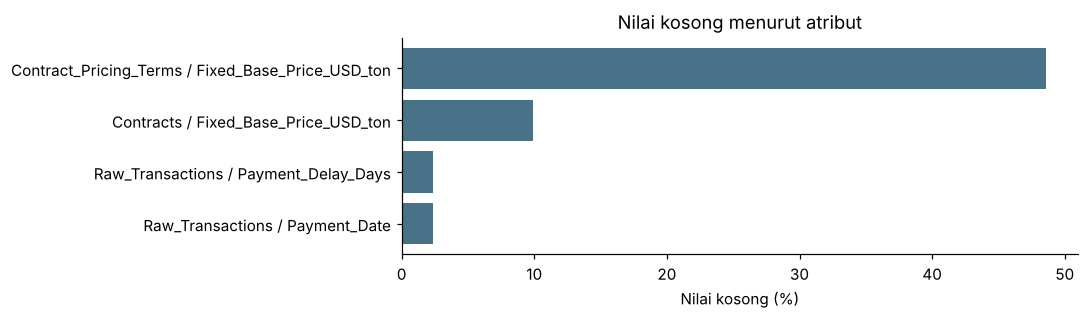

In [8]:
shown=missing_summary.loc[missing_summary.Missing.gt(0)].copy()
shown['Label']=shown.Sheet+' / '+shown.Column
fig,ax=plt.subplots(figsize=(10,max(3,.35*len(shown))))
ax.barh(shown.Label,shown.Missing_pct,color='#477287')
ax.set(xlabel='Nilai kosong (%)',title='Nilai kosong menurut atribut')
plt.tight_layout();finish_plot('10_missing_values','data_understanding')

### 1.9 Statistik numerik

In [9]:
raw.info()
numeric_summary=raw.select_dtypes(include=np.number).describe(percentiles=[.01,.25,.5,.75,.99]).T.reset_index(names='Column')
display(numeric_summary)
save_table(numeric_summary,'11_numeric_summary','data_understanding')

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25000 entries, 0 to 24999
Data columns (total 36 columns):
 #   Column                       Non-Null Count  Dtype         
---  ------                       --------------  -----         
 0   Transaction_ID               25000 non-null  object        
 1   Customer_ID                  25000 non-null  object        
 2   Customer_Name                25000 non-null  object        
 3   Country                      25000 non-null  object        
 4   Industry                     25000 non-null  object        
 5   Contract_ID                  25000 non-null  object        
 6   Contract_Type                25000 non-null  object        
 7   Transaction_Date             25000 non-null  datetime64[ns]
 8   Shipment_Date                25000 non-null  datetime64[ns]
 9   Invoice_Date                 25000 non-null  datetime64[ns]
 10  Payment_Date                 24412 non-null  datetime64[ns]
 11  Payment_Status               25000 non-nu

,Column,count,mean,std,min,1%,25%,50%,75%,99%,max
0,Typical_CV_kcal_kg,"25,000.0000","4,487.5320",350.3773,"4,000.0000","4,000.0000","4,200.0000","4,500.0000","4,700.0000","5,000.0000","5,000.0000"
1,Actual_CV_kcal_kg,"25,000.0000","4,487.3196",362.3603,"3,700.0000","3,856.0000","4,167.0000","4,496.0000","4,804.0000","5,132.0000","5,300.0000"
2,Total_Moisture_pct,"25,000.0000",30.3630,3.7984,19.9100,23.0200,27.2600,30.2500,33.4600,37.9701,42.1500
3,Ash_pct,"25,000.0000",2.3967,0.6950,0.7000,0.7600,1.9300,2.4000,2.8700,4.0400,5.2300
4,Sulphur_pct,"25,000.0000",0.1841,0.0938,0.0400,0.0400,0.1120,0.1800,0.2500,0.4120,0.6400
5,Quantity_Tonnes,"25,000.0000","32,586.2000","20,267.4922","5,000.0000","5,000.0000","13,000.0000","33,000.0000","49,000.0000","78,000.0000","80,000.0000"
6,Market_Index_USD_ton,"25,000.0000",77.0372,10.4007,56.2800,59.2299,69.2500,75.8000,83.1500,105.8501,113.5100
7,Base_Price_USD_ton,"25,000.0000",76.1612,10.0652,54.2700,58.9999,68.5500,74.8200,82.1000,103.5101,116.2900
8,Quality_Adjustment_USD_ton,"25,000.0000",-0.0183,0.6404,-3.2700,-1.5400,-0.4500,-0.0100,0.4100,1.4600,2.1000
9,Freight_USD_ton,"25,000.0000",3.9063,5.5406,0.0000,0.0000,0.0000,0.0000,8.3725,17.6300,18.2000


### 1.10 Distribusi produk dan ketentuan bisnis

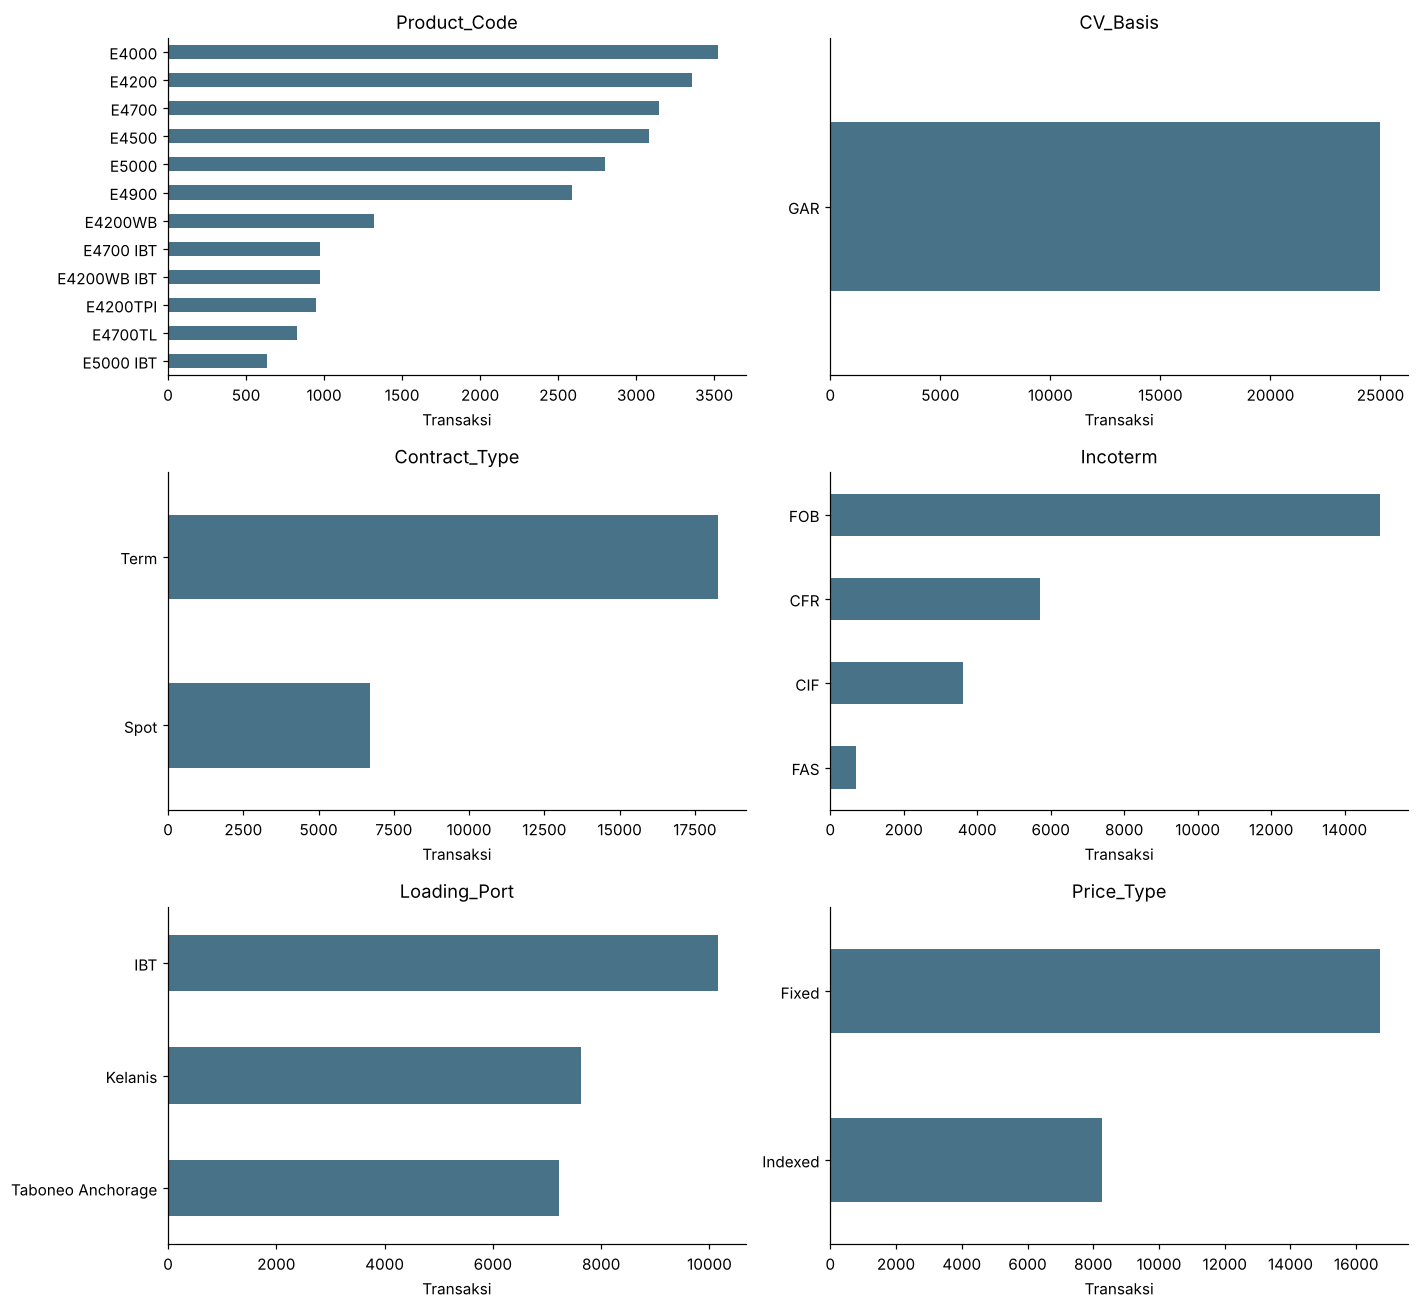

In [10]:
category_cols=['Product_Code','CV_Basis','Contract_Type','Incoterm','Loading_Port','Price_Type']
fig,axes=plt.subplots(3,2,figsize=(13,12))
category_tables=[]
for ax,col in zip(axes.ravel(),category_cols):
    counts=raw[col].value_counts(dropna=False)
    counts.head(12).sort_values().plot.barh(ax=ax,color='#477287')
    ax.set(title=col,xlabel='Transaksi',ylabel='')
    category_tables.append(counts.rename_axis('Value').reset_index(name='Transactions').assign(Column=col))
plt.tight_layout();finish_plot('12_business_categories','data_understanding')
save_table(pd.concat(category_tables,ignore_index=True),'12_business_categories','data_understanding')

### 1.11 Customer dan negara

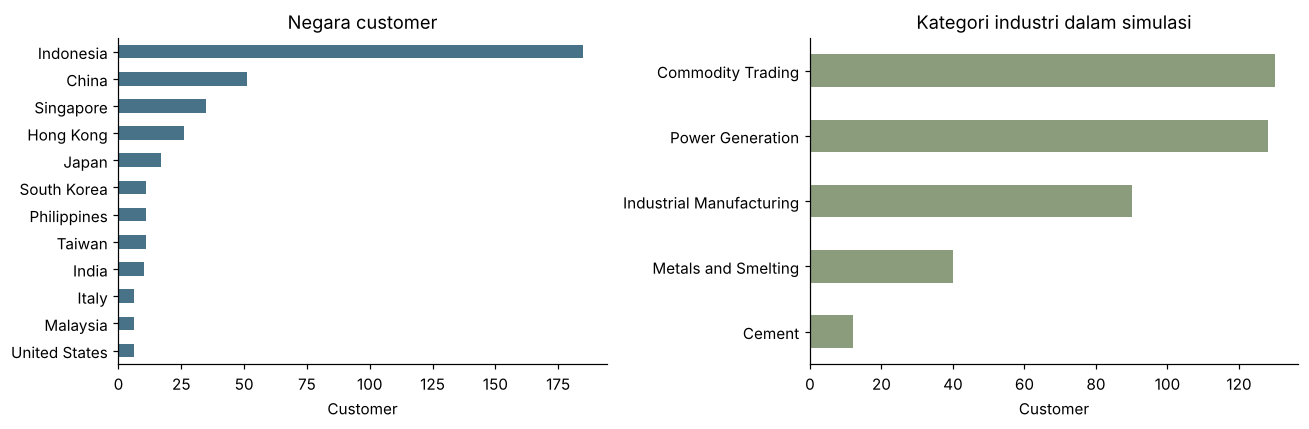

Industry merupakan perkiraan pada data sintetis; Country dan Industry tidak menjadi fitur model utama.


In [11]:
fig,axes=plt.subplots(1,2,figsize=(12,4))
master.Country.value_counts().head(12).sort_values().plot.barh(ax=axes[0],color='#477287')
master.Industry.value_counts().sort_values().plot.barh(ax=axes[1],color='#8b9c7c')
axes[0].set(title='Negara customer',xlabel='Customer',ylabel='')
axes[1].set(title='Kategori industri dalam simulasi',xlabel='Customer',ylabel='')
plt.tight_layout();finish_plot('13_customer_context','data_understanding')
print('Industry merupakan perkiraan pada data sintetis; Country dan Industry tidak menjadi fitur model utama.')

### 1.12 Pola transaksi bulanan

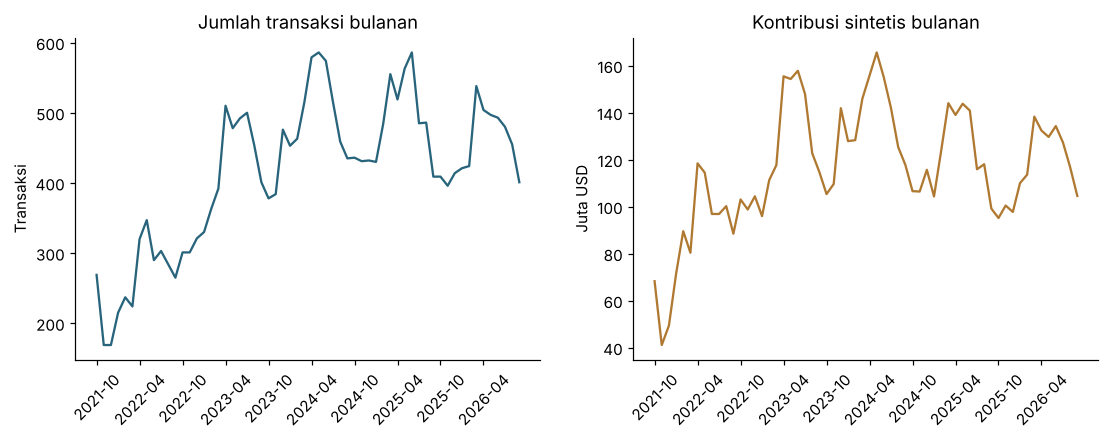

In [12]:
monthly = raw.groupby(raw.Transaction_Date.dt.to_period('M')).agg(
    Transactions=('Transaction_ID','size'), Quantity_Tonnes=('Quantity_Tonnes','sum'),
    Contribution_USD=('Contribution_USD','sum')).reset_index()
monthly['Month'] = monthly.Transaction_Date.astype(str)
fig, ax = plt.subplots(1,2,figsize=(12,3.8))
ax[0].plot(monthly.Month,monthly.Transactions,color='#28647c')
ax[0].set(title='Jumlah transaksi bulanan',ylabel='Transaksi')
ax[1].plot(monthly.Month,monthly.Contribution_USD/1e6,color='#b07932')
ax[1].set(title='Kontribusi sintetis bulanan',ylabel='Juta USD')
for a in ax: a.set_xticks(np.arange(0,len(monthly),6)); a.tick_params(axis='x',rotation=45)
finish_plot('04_monthly_transactions','data_understanding')
save_table(monthly,'04_monthly_transactions','data_understanding')

### 1.13 Ringkasan customer pada seluruh periode

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
Customer_ID,400,400,CUST-0400,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Transactions,400.0000,NaN,NaN,NaN,62.5000,4.0000,24.0000,42.0000,82.2500,209.0000,51.7428
Quantity_Tonnes,400.0000,NaN,NaN,NaN,"2,036,637.5000","72,000.0000","745,500.0000","1,270,500.0000","2,743,000.0000","7,974,000.0000","1,787,314.0701"
Revenue_USD,400.0000,NaN,NaN,NaN,"163,119,295.3000","5,447,630.0000","59,755,792.5000","106,447,155.0000","223,347,477.5000","629,488,820.0000","143,675,122.7805"
Contribution_USD,400.0000,NaN,NaN,NaN,"17,440,663.0250","522,200.0000","6,138,525.0000","10,838,455.0000","22,415,510.0000","91,584,910.0000","16,793,345.9520"
Observed_Contracts,400.0000,NaN,NaN,NaN,21.2375,4.0000,13.0000,19.0000,26.0000,59.0000,10.9895
First_Transaction,400,NaN,NaN,NaN,2022-09-02 19:01:12.000000256,2021-10-01 00:00:00,2021-10-11 18:00:00,2022-04-23 12:00:00,2023-04-07 00:00:00,2025-04-17 00:00:00,NaN
Last_Transaction,400,NaN,NaN,NaN,2026-07-29 07:40:48,2024-02-23 00:00:00,2026-07-30 00:00:00,2026-09-01 00:00:00,2026-09-17 00:00:00,2026-09-24 00:00:00,NaN


,Customer_ID,Transactions,Quantity_Tonnes,Revenue_USD,Contribution_USD,Observed_Contracts,First_Transaction,Last_Transaction
317,CUST-0318,194,7974000,629488820,91584910,46,2021-10-06,2026-08-19
227,CUST-0228,204,7566000,595315410,85955550,46,2021-10-25,2026-09-21
373,CUST-0374,183,6780000,589047470,81223220,35,2021-11-01,2026-09-20
362,CUST-0363,188,6971000,552187360,79307800,50,2021-10-04,2026-09-11
238,CUST-0239,184,7025000,615349560,78651370,45,2021-10-01,2026-09-10
333,CUST-0334,173,6968000,562685540,72733550,44,2021-10-04,2026-09-24
147,CUST-0148,176,6399000,497295550,69801940,51,2021-10-05,2026-09-22
352,CUST-0353,201,7553000,581665460,69463090,59,2021-10-02,2026-09-12
351,CUST-0352,177,6850000,494015800,68761830,50,2021-10-01,2026-08-19
381,CUST-0382,177,5909000,516657630,66019390,41,2021-10-04,2026-08-19


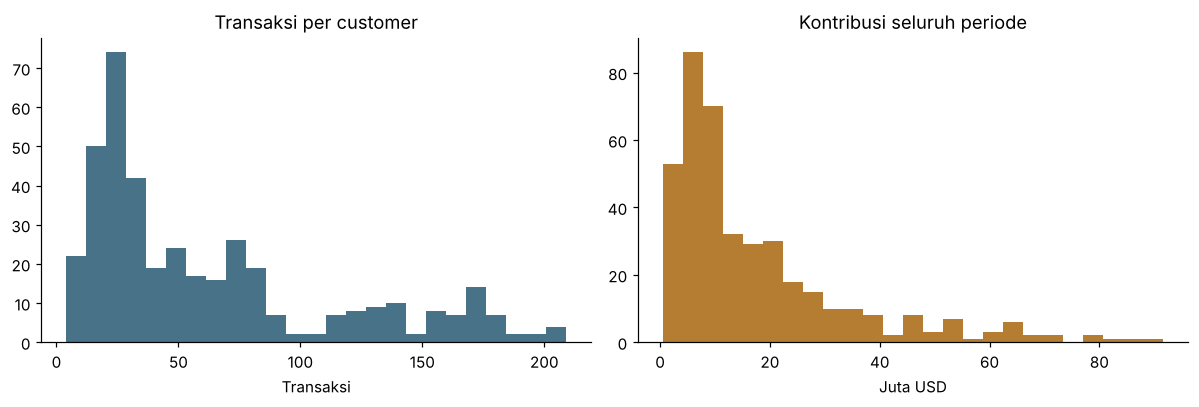

Ringkasan seluruh periode hanya untuk EDA, bukan fitur prediksi.


In [13]:
customer_eda=raw.groupby('Customer_ID').agg(Transactions=('Transaction_ID','size'),
    Quantity_Tonnes=('Quantity_Tonnes','sum'),Revenue_USD=('Revenue_USD','sum'),
    Contribution_USD=('Contribution_USD','sum'),Observed_Contracts=('Contract_ID','nunique'),
    First_Transaction=('Transaction_Date','min'),Last_Transaction=('Transaction_Date','max')).reset_index()
display(customer_eda.describe(include='all').T)
display(customer_eda.sort_values('Contribution_USD',ascending=False).head(10))
save_table(customer_eda,'14_customer_full_period_eda','data_understanding')
fig,axes=plt.subplots(1,2,figsize=(11,3.8))
axes[0].hist(customer_eda.Transactions,bins=25,color='#477287');axes[0].set(title='Transaksi per customer',xlabel='Transaksi')
axes[1].hist(customer_eda.Contribution_USD/1e6,bins=25,color='#b57d32');axes[1].set(title='Kontribusi seluruh periode',xlabel='Juta USD')
plt.tight_layout();finish_plot('15_customer_full_period','data_understanding')
print('Ringkasan seluruh periode hanya untuk EDA, bukan fitur prediksi.')

### 1.14 Durasi kontrak

,Contract_Type,Multiyear,Contracts,Min_Duration,Median_Duration,Max_Duration
0,Spot,False,6724,7,31.0000,31
1,Term,False,1721,92,365.0000,366
2,Term,True,50,730,731.0000,1096


,Contract_ID,Customer_ID,Contract_Type,Contract_Start_Date,Contract_End_Date,Product_Code,CV_Basis,Typical_CV_kcal_kg,Incoterm,Loading_Port,Destination_Region,Price_Type,Fixed_Base_Price_USD_ton,Payment_Term_Days,Duration_Days,Multiyear,Country
0,CTR-00527,CUST-0367,Term,2022-01-01,2023-12-31,E4200WB,GAR,4200,FOB,Taboneo Anchorage,East Asia,Annual_Schedule,NaN,45,730,True,China
1,CTR-00638,CUST-0325,Term,2022-01-01,2023-12-31,E4000,GAR,4000,CFR,IBT,Southeast Asia,Annual_Schedule,NaN,45,730,True,Singapore
2,CTR-00654,CUST-0254,Term,2022-01-01,2024-12-31,E4700,GAR,4700,CFR,Kelanis,East Asia,Annual_Schedule,NaN,30,1096,True,China
3,CTR-00689,CUST-0068,Term,2022-01-01,2023-12-31,E4200,GAR,4200,FOB,Kelanis,South Asia,Annual_Schedule,NaN,45,730,True,India
4,CTR-00732,CUST-0025,Term,2022-01-01,2023-12-31,E5000,GAR,5000,FOB,Taboneo Anchorage,Other International,Annual_Schedule,NaN,60,730,True,United States
5,CTR-00970,CUST-0012,Term,2022-01-01,2023-12-31,E4200,GAR,4200,FOB,Kelanis,East Asia,Annual_Schedule,NaN,30,730,True,Hong Kong
6,CTR-01065,CUST-0365,Term,2022-01-01,2024-12-31,E5000 IBT,GAR,5000,FOB,IBT,East Asia,Annual_Schedule,NaN,30,1096,True,China
7,CTR-02234,CUST-0293,Term,2022-01-01,2023-12-31,E4500,GAR,4500,FOB,Taboneo Anchorage,Southeast Asia,Annual_Schedule,NaN,15,730,True,Singapore
8,CTR-02790,CUST-0287,Term,2023-01-01,2024-12-31,E5000,GAR,5000,FOB,Kelanis,East Asia,Annual_Schedule,NaN,45,731,True,Taiwan
9,CTR-02825,CUST-0145,Term,2023-01-01,2025-12-31,E4500,GAR,4500,FOB,IBT,East Asia,Annual_Schedule,NaN,30,1096,True,South Korea


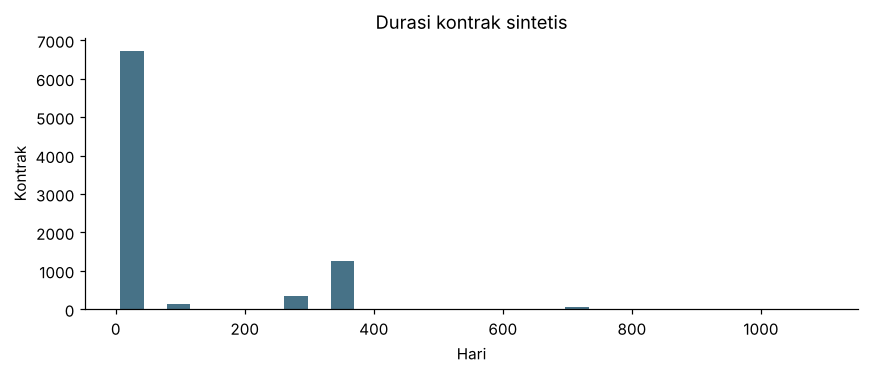

Jadwal akhir kontrak tidak memperpanjang observasi transaksi: 2026-09-30


In [14]:
contract_eda=contracts.assign(Duration_Days=(contracts.Contract_End_Date-contracts.Contract_Start_Date).dt.days+1)
contract_eda['Multiyear']=contract_eda.Duration_Days.gt(366)
display(contract_eda.groupby(['Contract_Type','Multiyear']).agg(Contracts=('Contract_ID','size'),
    Min_Duration=('Duration_Days','min'),Median_Duration=('Duration_Days','median'),Max_Duration=('Duration_Days','max')).reset_index())
display(contract_eda.loc[contract_eda.Multiyear].merge(master[['Customer_ID','Country']],on='Customer_ID').head(10))
save_table(contract_eda,'16_contract_durations','data_understanding')
fig,ax=plt.subplots(figsize=(8,3.5))
ax.hist(contract_eda.Duration_Days,bins=30,color='#477287');ax.set(title='Durasi kontrak sintetis',xlabel='Hari',ylabel='Kontrak')
plt.tight_layout();finish_plot('16_contract_durations','data_understanding')
print('Jadwal akhir kontrak tidak memperpanjang observasi transaksi:',CUTOFF.date())

### 1.15 Contoh ketentuan harga multiyear

In [15]:
example_contract=pricing.Contract_ID.iloc[0]
display(contracts.loc[contracts.Contract_ID.eq(example_contract)])
display(pricing.loc[pricing.Contract_ID.eq(example_contract)])
display(raw.loc[raw.Contract_ID.eq(example_contract),['Transaction_ID','Transaction_Date','Price_Type','Base_Price_USD_ton','Quantity_Tonnes']].head(12))

,Contract_ID,Customer_ID,Contract_Type,Contract_Start_Date,Contract_End_Date,Product_Code,CV_Basis,Typical_CV_kcal_kg,Incoterm,Loading_Port,Destination_Region,Price_Type,Fixed_Base_Price_USD_ton,Payment_Term_Days
410,CTR-00654,CUST-0254,Term,2022-01-01,2024-12-31,E4700,GAR,4700,CFR,Kelanis,East Asia,Annual_Schedule,NaN,30


,Pricing_Term_ID,Contract_ID,Source_Contract_ID,Customer_ID,Effective_From,Effective_To,Price_Type,Fixed_Base_Price_USD_ton,Payment_Term_Days
0,MY-001-Y1,CTR-00654,CTR-00654,CUST-0254,2022-01-01,2022-12-31,Fixed,101.1900,30
1,MY-001-Y2,CTR-00654,CTR-02942,CUST-0254,2023-01-01,2023-12-31,Fixed,87.1300,30
2,MY-001-Y3,CTR-00654,CTR-06172,CUST-0254,2024-01-01,2024-12-31,Indexed,NaN,30


,Transaction_ID,Transaction_Date,Price_Type,Base_Price_USD_ton,Quantity_Tonnes
697,TX-01494,2022-01-13,Fixed,101.1900,5000
955,TX-02018,2022-02-13,Fixed,101.1900,15000
1270,TX-02677,2022-03-24,Fixed,101.1900,36000
1278,TX-02693,2022-03-25,Fixed,101.1900,46000
2003,TX-04159,2022-06-04,Fixed,101.1900,5000
2024,TX-04189,2022-06-05,Fixed,101.1900,40000
2045,TX-04237,2022-06-07,Fixed,101.1900,6000
2073,TX-04310,2022-06-10,Fixed,101.1900,25000
2179,TX-04573,2022-06-20,Fixed,101.1900,8000
2867,TX-05989,2022-09-05,Fixed,101.1900,16000


## 2 Data Preparation
### 2.1 Tipe data dan tanggal

In [16]:
raw_original = raw.copy(deep=True)
for d in sources.values():
    for c in d.select_dtypes(include='object'):
        if c.endswith('_ID') or c in ['Contract_Type','Price_Type','Product_Code','Country','Incoterm','Loading_Port']:
            d[c] = d[c].astype('string').str.strip()
for c in ['Transaction_Date','Shipment_Date','Invoice_Date','Payment_Date']:
    raw[c]=pd.to_datetime(raw[c],errors='raise')
for c in ['Contract_Start_Date','Contract_End_Date']:
    contracts[c]=pd.to_datetime(contracts[c],errors='raise')
for c in ['Effective_From','Effective_To']:
    pricing[c]=pd.to_datetime(pricing[c],errors='raise')
master['First_Observed_Transaction_Date']=pd.to_datetime(master.First_Observed_Transaction_Date,errors='raise')

### 2.2 Identitas dan kelengkapan wajib

In [17]:
audit_checks=[]
def audit(name, failures):
    audit_checks.append({'Check':name,'Failures':int(failures)})
for n,d in sources.items(): audit(f'{n}: duplicated ID',d[key_columns[n]].duplicated().sum())
audit('Transaksi tanpa customer', (~raw.Customer_ID.isin(master.Customer_ID)).sum())
audit('Transaksi tanpa kontrak', (~raw.Contract_ID.isin(contracts.Contract_ID)).sum())

for name,df in sources.items():
    audit(f'{name}: ID kosong',df[key_columns[name]].isna().sum())
for col in ['Customer_ID','Contract_ID','Transaction_Date','Quantity_Tonnes','Revenue_USD','Contribution_USD']:
    audit(f'Transaksi: {col} kosong',raw[col].isna().sum())

### 2.3 Tanggal dan nilai keuangan

In [18]:
audit('Tanggal transaksi di luar observasi', (~raw.Transaction_Date.between(START,CUTOFF)).sum())
audit('Kuantitas tidak positif',raw.Quantity_Tonnes.le(0).sum())
audit('Pengiriman mendahului transaksi',raw.Shipment_Date.lt(raw.Transaction_Date).sum())
audit('Invoice mendahului transaksi',raw.Invoice_Date.lt(raw.Transaction_Date).sum())
audit('Pembayaran mendahului invoice',raw.Payment_Date.lt(raw.Invoice_Date).sum())
audit('Harga akhir tidak cocok',(~np.isclose(raw.Final_Price_USD_ton,
    raw.Base_Price_USD_ton+raw.Quality_Adjustment_USD_ton+raw.Freight_USD_ton,atol=.011,rtol=0)).sum())
audit('Pendapatan tidak cocok',(~np.isclose(raw.Revenue_USD,raw.Quantity_Tonnes*raw.Final_Price_USD_ton,atol=.011,rtol=0)).sum())
audit('Kontribusi tidak cocok',(~np.isclose(raw.Contribution_USD,
    raw.Quantity_Tonnes*(raw.Final_Price_USD_ton-raw.Synthetic_Unit_Cost_USD_ton),atol=.011,rtol=0)).sum())

### 2.4 Hubungan transaksi dan kontrak

In [19]:
joined=raw.merge(contracts,on='Contract_ID',suffixes=('','_contract'),validate='many_to_one')
audit('Transaksi atau pengiriman di luar kontrak',
    (joined.Transaction_Date.lt(joined.Contract_Start_Date)|joined.Transaction_Date.gt(joined.Contract_End_Date)|
     joined.Shipment_Date.lt(joined.Contract_Start_Date)|joined.Shipment_Date.gt(joined.Contract_End_Date)).sum())
for c in ['Customer_ID','Contract_Type','Product_Code','CV_Basis','Typical_CV_kcal_kg',
          'Incoterm','Loading_Port','Destination_Region','Payment_Term_Days']:
    audit(f'Kontrak berbeda: {c}',joined[c].ne(joined[c+'_contract']).sum())

### 2.5 Harga kontrak dan ketentuan tahunan

In [20]:
normal=joined.loc[joined.Price_Type_contract.ne('Annual_Schedule')]
audit('Jenis harga kontrak biasa',normal.Price_Type.ne(normal.Price_Type_contract).sum())
audit('Harga Fixed kontrak biasa',(normal.Price_Type.eq('Fixed') &
    ~np.isclose(normal.Base_Price_USD_ton,normal.Fixed_Base_Price_USD_ton,atol=.011,rtol=0)).sum())
multi=joined.loc[joined.Price_Type_contract.eq('Annual_Schedule')].copy()
price_match=multi[['Transaction_ID','Contract_ID','Transaction_Date','Base_Price_USD_ton','Price_Type','Payment_Term_Days']].merge(
    pricing,on='Contract_ID',suffixes=('','_term'),validate='many_to_many')
price_match=price_match.loc[price_match.Transaction_Date.between(price_match.Effective_From,price_match.Effective_To)]
match_counts=price_match.groupby('Transaction_ID').size().reindex(multi.Transaction_ID,fill_value=0)
audit('Transaksi multiyear tanpa tepat satu ketentuan tahunan',match_counts.ne(1).sum())
audit('Jenis harga multiyear',price_match.Price_Type.ne(price_match.Price_Type_term).sum())
audit('Harga Fixed multiyear',(price_match.Price_Type.eq('Fixed') &
    ~np.isclose(price_match.Base_Price_USD_ton,price_match.Fixed_Base_Price_USD_ton,atol=.011,rtol=0)).sum())
audit('Termin pembayaran multiyear',price_match.Payment_Term_Days.ne(price_match.Payment_Term_Days_term).sum())
ordered_terms=pricing.sort_values(['Contract_ID','Effective_From']).copy()
prior_end=ordered_terms.groupby('Contract_ID').Effective_To.shift()
audit('Ketentuan harga tumpang tindih',ordered_terms.Effective_From.le(prior_end).sum())

term_parent=pricing.merge(contracts,on='Contract_ID',suffixes=('','_parent'),validate='many_to_one')
audit('Customer ketentuan harga berbeda dari kontrak',term_parent.Customer_ID.ne(term_parent.Customer_ID_parent).sum())
audit('Ketentuan tahunan di luar masa kontrak',(term_parent.Effective_From.lt(term_parent.Contract_Start_Date)|term_parent.Effective_To.gt(term_parent.Contract_End_Date)).sum())

### 2.6 Hasil pemeriksaan sumber

In [21]:
checks=pd.DataFrame(audit_checks)
display(checks);save_table(checks,'01_consistency_checks')
if checks.Failures.sum(): raise ValueError('Ada ketidaksesuaian data. Periksa tabel audit sebelum melanjutkan.')
print('Audit sumber lulus. Tidak ada transaksi atau target yang diubah untuk mengejar skor.')

,Check,Failures
0,Raw_Transactions: duplicated ID,0
1,Customer_Master: duplicated ID,0
2,Contracts: duplicated ID,0
3,Contract_Pricing_Terms: duplicated ID,0
4,Transaksi tanpa customer,0
5,Transaksi tanpa kontrak,0
6,Raw_Transactions: ID kosong,0
7,Customer_Master: ID kosong,0
8,Contracts: ID kosong,0
9,Contract_Pricing_Terms: ID kosong,0


Audit sumber lulus. Tidak ada transaksi atau target yang diubah untuk mengejar skor.


### 2.7 Pembentukan panel historis dan target
Satu baris mewakili customer pada satu tanggal acuan. Nilai komersial diasumsikan tercatat pada tanggal transaksi dalam simulasi.

In [22]:
customers=master.set_index('Customer_ID')
tx_groups={k:g.sort_values('Transaction_Date') for k,g in raw.groupby('Customer_ID')}
month_ends=pd.date_range(START,CUTOFF,freq='ME')
eligible_rows, candidate_rows=[],[]
discount_average=np.mean([(1+DISCOUNT)**(-m/12) for m in range(1,HORIZON+1)])
for asof in month_ends:
    lower=asof-pd.Timedelta(days=HISTORY_DAYS)
    target_end=asof+pd.offsets.MonthEnd(HORIZON)
    full_history=lower+pd.Timedelta(days=1)>=START
    full_target=target_end<=CUTOFF
    if not full_history or not full_target:
        reason='INCOMPLETE_HISTORY_COVERAGE' if not full_history else 'INCOMPLETE_TARGET_COVERAGE'
        candidate_rows.extend({'Customer_ID':cid,'As_Of_Date':asof,'Reason':reason} for cid in sorted(customers.index))
        continue
    for customer_id in sorted(customers.index):
        tx=tx_groups.get(customer_id,raw.iloc[:0])
        hist=tx.loc[tx.Transaction_Date.gt(lower)&tx.Transaction_Date.le(asof)]
        reason=('INCOMPLETE_HISTORY_COVERAGE' if not full_history else
                'INCOMPLETE_TARGET_COVERAGE' if not full_target else
                'NO_HISTORICAL_TRANSACTION' if hist.empty else 'ELIGIBLE')
        candidate_rows.append({'Customer_ID':customer_id,'As_Of_Date':asof,'Reason':reason})
        if reason!='ELIGIBLE':continue
        paid=hist.loc[hist.Payment_Date.notna()&hist.Payment_Date.le(asof)]
        quality=hist.loc[hist.Shipment_Date.notna()&hist.Shipment_Date.le(asof)]
        observed=tx.loc[tx.Transaction_Date.le(asof)]
        future=tx.loc[tx.Transaction_Date.gt(asof)&tx.Transaction_Date.le(target_end)]
        m=(future.Transaction_Date.dt.year-asof.year)*12+future.Transaction_Date.dt.month-asof.month
        cm=customers.loc[customer_id]
        r={'Snapshot_ID':f'{customer_id}_{asof:%Y-%m-%d}','Customer_ID':customer_id,'As_Of_Date':asof,
           'History_Start_Date':lower+pd.Timedelta(days=1),'Target_Start_Date':asof+pd.Timedelta(days=1),
           'Target_End_Date':target_end,'Country':cm.Country,'Industry':cm.Industry,
           'Tenure_Days':(asof-observed.Transaction_Date.min()).days,
           'Recency_Days':(asof-hist.Transaction_Date.max()).days,
           'Frequency_12M':len(hist),'Active_Months_12M':hist.Transaction_Date.dt.to_period('M').nunique(),
           'Historical_Revenue_12M_USD':hist.Revenue_USD.sum(),
           'Historical_Contribution_12M_USD':hist.Contribution_USD.sum(),
           'Average_Transaction_Value_USD':hist.Revenue_USD.mean(),
           'Total_Quantity_12M_Tonnes':hist.Quantity_Tonnes.sum(),
           'Average_Quantity_Tonnes':hist.Quantity_Tonnes.mean(),
           'Average_Final_Price_USD_ton':hist.Final_Price_USD_ton.mean(),
           'Product_Variety_12M':hist.Product_Code.nunique(),
           'Contract_Count_12M':hist.Contract_ID.nunique(),
           'Term_Transaction_Share':hist.Contract_Type.eq('Term').mean(),
           'Avg_Payment_Delay_Days':paid.Payment_Delay_Days.mean(),
           'Quality_Compliance_Rate':quality.Quality_Compliant.astype(float).mean(),
           'Known_Payment_Count':len(paid),'Known_Quality_Count':len(quality),
           'Payment_Delay_Unavailable':int(paid.empty),'Quality_Rate_Unavailable':int(quality.empty),
           'Future_6M_Revenue_USD':round(float(future.Revenue_USD.sum()),2),
           'Future_6M_CLV_Proxy_USD':round(float((future.Contribution_USD/(1+DISCOUNT)**(m/12)).sum()),2)}
        # Fitur tambahan hanya memakai transaksi sebelum atau tepat tanggal acuan.
        for months in [3,6]:
            recent=hist.loc[hist.Transaction_Date.gt(asof-pd.DateOffset(months=months))]
            r[f'Frequency_{months}M']=len(recent)
            r[f'Contribution_{months}M_USD']=recent.Contribution_USD.sum()
            r[f'Quantity_{months}M_Tonnes']=recent.Quantity_Tonnes.sum()
            r[f'Active_Months_{months}M']=recent.Transaction_Date.dt.to_period('M').nunique()
            r[f'Average_Price_{months}M']=recent.Final_Price_USD_ton.mean()
        r['Contribution_Per_Tonne']=hist.Contribution_USD.sum()/hist.Quantity_Tonnes.sum()
        r['Recent_Contribution_Share']=r['Contribution_3M_USD']/max(r['Historical_Contribution_12M_USD'],1)
        r['Recent_Frequency_Share']=r['Frequency_3M']/r['Frequency_12M']
        r['Contribution_Momentum']=r['Contribution_3M_USD']-r['Contribution_6M_USD']/2
        monthly_hist=hist.groupby(hist.Transaction_Date.dt.to_period('M')).Contribution_USD.sum().reindex(
            pd.period_range((asof-pd.DateOffset(months=11)).to_period('M'),asof.to_period('M'),freq='M'),fill_value=0)
        r['Monthly_Contribution_CV']=float(monthly_hist.std(ddof=0)/max(monthly_hist.mean(),1))
        gaps=hist.Transaction_Date.drop_duplicates().sort_values().diff().dt.days.dropna()
        r['Median_Interpurchase_Days']=gaps.median() if len(gaps) else np.nan
        r['Average_Market_Index']=hist.Market_Index_USD_ton.mean()
        r['Recent_Price_Change']=r['Average_Price_3M']-r['Average_Price_6M']
        r['Baseline_12M_USD']=r['Historical_Contribution_12M_USD']*.5*discount_average
        r['Baseline_Recent6M_USD']=r['Contribution_6M_USD']*discount_average
        eligible_rows.append(r)
eligible=pd.DataFrame(eligible_rows)
candidate_audit=pd.DataFrame(candidate_rows)
print('Kandidat:',len(candidate_audit),'| Layak sebelum split:',len(eligible))

Kandidat: 24000 | Layak sebelum split: 15181


### 2.8 Fitur kontrak yang diketahui pada tanggal acuan
Kontrak baru digunakan setelah transaksi pertamanya. Kontrak yang sudah berakhir tidak dihitung sebagai kontrak aktif.

In [23]:
# Masa kontrak diasumsikan diketahui sejak kontrak pertama kali teramati dalam transaksi.
contract_first=raw.groupby('Contract_ID').Transaction_Date.min().rename('First_Contract_Observed')
contract_history=contracts.merge(contract_first,on='Contract_ID',validate='one_to_one')
contract_history['Duration_Days']=(contract_history.Contract_End_Date-contract_history.Contract_Start_Date).dt.days+1
contract_history['Multiyear']=contract_history.Duration_Days.gt(366)
contract_feature_rows=[]
for asof in sorted(eligible.As_Of_Date.unique()):
    asof=pd.Timestamp(asof)
    known=contract_history.loc[contract_history.First_Contract_Observed.le(asof)&contract_history.Contract_Start_Date.le(asof)].copy()
    active=known.loc[known.Contract_End_Date.gt(asof)].copy()
    active['Remaining_Days']=(active.Contract_End_Date-asof).dt.days
    for cid in eligible.loc[eligible.As_Of_Date.eq(asof),'Customer_ID']:
        k=known.loc[known.Customer_ID.eq(cid)]
        a=active.loc[active.Customer_ID.eq(cid)]
        term=a.loc[a.Contract_Type.eq('Term')]
        contract_feature_rows.append({'Customer_ID':cid,'As_Of_Date':asof,
            'Active_Contract_Count':len(a),'Active_Term_Contract_Count':len(term),
            'Active_Multiyear_Count':int(a.Multiyear.sum()),
            'Remaining_Term_Days_Mean':float(term.Remaining_Days.mean()) if len(term) else 0.,
            'Remaining_Term_Days_Max':float(term.Remaining_Days.max()) if len(term) else 0.,
            'Expiring_90D_Share':float(a.Remaining_Days.le(90).mean()) if len(a) else 0.,
            'No_Active_Term_Flag':int(term.empty),
            'Observed_Contract_Duration_Mean':float(k.Duration_Days.mean()) if len(k) else 0.,
            'AsOf_Month_Sin':float(np.sin(2*np.pi*asof.month/12)),
            'AsOf_Month_Cos':float(np.cos(2*np.pi*asof.month/12))})
contract_features=pd.DataFrame(contract_feature_rows)
eligible=eligible.merge(contract_features,on=['Customer_ID','As_Of_Date'],validate='one_to_one')
display(contract_features.head())
save_table(contract_features,'13_contract_features_asof')
print('Fitur memakai kontrak yang sudah teramati; ketentuan harga tahunan masa depan tidak menjadi input.')

,Customer_ID,As_Of_Date,Active_Contract_Count,Active_Term_Contract_Count,Active_Multiyear_Count,Remaining_Term_Days_Mean,Remaining_Term_Days_Max,Expiring_90D_Share,No_Active_Term_Flag,Observed_Contract_Duration_Mean,AsOf_Month_Sin,AsOf_Month_Cos
0,CUST-0001,2022-09-30,0,0,0,0.0000,0.0000,0.0000,1,41.1667,-1.0000,-0.0000
1,CUST-0002,2022-09-30,2,1,0,92.0000,92.0000,0.5000,0,198.0000,-1.0000,-0.0000
2,CUST-0004,2022-09-30,1,1,0,92.0000,92.0000,0.0000,0,96.8333,-1.0000,-0.0000
3,CUST-0005,2022-09-30,2,1,0,92.0000,92.0000,0.5000,0,86.6667,-1.0000,-0.0000
4,CUST-0008,2022-09-30,2,1,0,92.0000,92.0000,0.5000,0,129.7500,-1.0000,-0.0000


Fitur memakai kontrak yang sudah teramati; ketentuan harga tahunan masa depan tidak menjadi input.


### 2.9 Split temporal v2 dengan purge
Split ditetapkan dari tanggal acuan: Train 2022-09-30 s.d. 2024-09-30, Validation 2025-03-31 s.d. 2025-06-30, dan Test 2025-12-31 s.d. 2026-03-31. Snapshot yang targetnya belum selesai pada awal bagian berikutnya dikeluarkan (*purge*). Tidak ada snapshot lain yang dibuang demi rasio, sehingga proporsinya 72,0/14,0/14,0. Tanggal split sudah final dan tidak dipilih dari besarnya target.

In [24]:
VALIDATION_START = pd.Timestamp('2025-03-31')
TEST_START = pd.Timestamp('2025-12-31')
def assign_split(df):
    asof, end = df.As_Of_Date, df.Target_End_Date
    return np.select(
        [asof.lt(VALIDATION_START) & end.le(VALIDATION_START),
         asof.ge(VALIDATION_START) & asof.lt(TEST_START) & end.le(TEST_START),
         asof.ge(TEST_START)],
        ['Train','Validation','Test'], default='Purged')
eligible['Split'] = assign_split(eligible)
panel = eligible.loc[eligible.Split.ne('Purged')].sort_values(['As_Of_Date','Customer_ID']).reset_index(drop=True)
candidate_audit['Snapshot_ID'] = candidate_audit.Customer_ID+'_'+candidate_audit.As_Of_Date.dt.strftime('%Y-%m-%d')
ok = candidate_audit.Reason.eq('ELIGIBLE')
split_by_id = eligible.set_index('Snapshot_ID').Split
candidate_audit.loc[ok,'Reason'] = np.where(candidate_audit.loc[ok,'Snapshot_ID'].map(split_by_id).eq('Purged'),
                                            'PURGED_LABEL_NOT_MATURE','INCLUDED')
reason_summary = candidate_audit.Reason.value_counts().rename_axis('Reason').reset_index(name='Rows')
split_summary = panel.groupby('Split').agg(Snapshots=('Snapshot_ID','size'),Customers=('Customer_ID','nunique'),
    First_As_Of=('As_Of_Date','min'),Last_As_Of=('As_Of_Date','max'),Last_Target_End=('Target_End_Date','max')).reindex(SPLITS).reset_index()
split_summary['Ratio_pct'] = 100*split_summary.Snapshots/len(panel)
assert len(candidate_audit)==24000 and len(panel)==11242
assert panel.Split.value_counts().reindex(SPLITS).tolist()==[8097,1573,1572]
assert panel.Snapshot_ID.is_unique and panel.Target_End_Date.le(CUTOFF).all()
assert panel.History_Start_Date.ge(START).all() and panel.Frequency_12M.ge(1).all()
for prev,nxt in zip(SPLITS,SPLITS[1:]):
    assert panel.loc[panel.Split.eq(prev),'Target_End_Date'].max()<=panel.loc[panel.Split.eq(nxt),'As_Of_Date'].min()
display(reason_summary); display(split_summary)
save_table(panel,'02_panel_generated'); save_table(candidate_audit,'03_snapshot_audit')
save_table(reason_summary,'04_snapshot_reasons'); save_table(split_summary,'05_split_summary')
print('Panel:',len(panel),'snapshot dari',panel.Customer_ID.nunique(),'customer')
print('Hanya purge yang mengeluarkan snapshot layak; target nol tetap dipertahankan.')

,Reason,Rows
0,INCLUDED,11242
1,INCOMPLETE_HISTORY_COVERAGE,4400
2,PURGED_LABEL_NOT_MATURE,3939
3,INCOMPLETE_TARGET_COVERAGE,2400
4,NO_HISTORICAL_TRANSACTION,2019


,Split,Snapshots,Customers,First_As_Of,Last_As_Of,Last_Target_End,Ratio_pct
0,Train,8097,375,2022-09-30,2024-09-30,2025-03-31,72.0246
1,Validation,1573,397,2025-03-31,2025-06-30,2025-12-31,13.9922
2,Test,1572,397,2025-12-31,2026-03-31,2026-09-30,13.9833


Panel: 11242 snapshot dari 400 customer
Hanya purge yang mengeluarkan snapshot layak; target nol tetap dipertahankan.


### 2.10 Jejak pembentukan panel

,Reason,Rows
0,INCLUDED,11242
1,INCOMPLETE_HISTORY_COVERAGE,4400
2,PURGED_LABEL_NOT_MATURE,3939
3,INCOMPLETE_TARGET_COVERAGE,2400
4,NO_HISTORICAL_TRANSACTION,2019


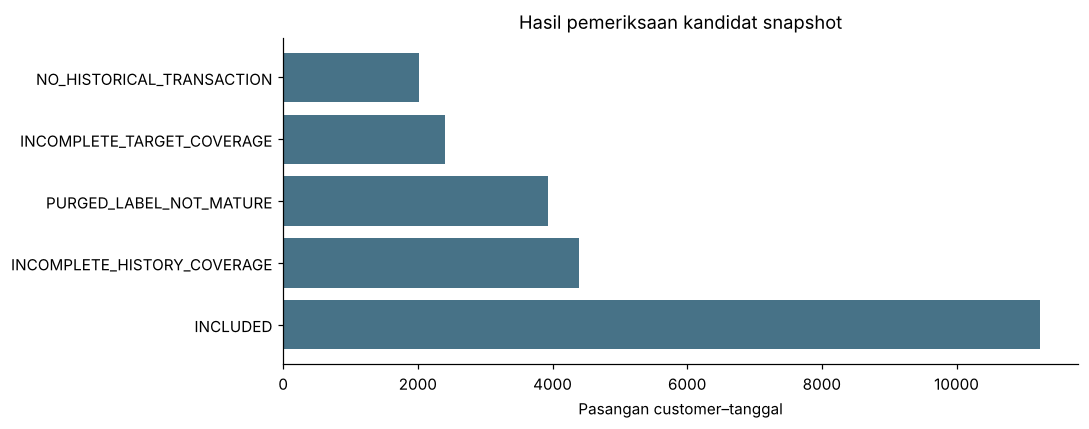

,Split,Customers
0,Train,375
1,Validation,397
2,Test,397


Customer sumber: 400 | Customer unik pada panel: 400
Customer dapat muncul pada lebih dari satu tanggal dan bagian waktu.


In [25]:
display(reason_summary)
fig,ax=plt.subplots(figsize=(10,4))
ax.barh(reason_summary.Reason,reason_summary.Rows,color='#477287')
ax.set(xlabel='Pasangan customer–tanggal',title='Hasil pemeriksaan kandidat snapshot')
plt.tight_layout();finish_plot('14_snapshot_selection','data_preparation')
cohorts=panel.groupby('Split').Customer_ID.nunique().reindex(SPLITS).rename('Customers').reset_index()
display(cohorts)
print('Customer sumber:',len(master),'| Customer unik pada panel:',panel.Customer_ID.nunique())
print('Customer dapat muncul pada lebih dari satu tanggal dan bagian waktu.')

### 2.11 Missing value pada panel dan target Train

,Feature,Train,Validation,Test
13,Avg_Payment_Delay_Days,0.0235,0.0089,0.0070
25,Average_Price_3M,0.0555,0.0960,0.1641
30,Average_Price_6M,0.0041,0.0280,0.0687
36,Median_Interpurchase_Days,0.0264,0.0254,0.0503
38,Recent_Price_Change,0.0555,0.0960,0.1641


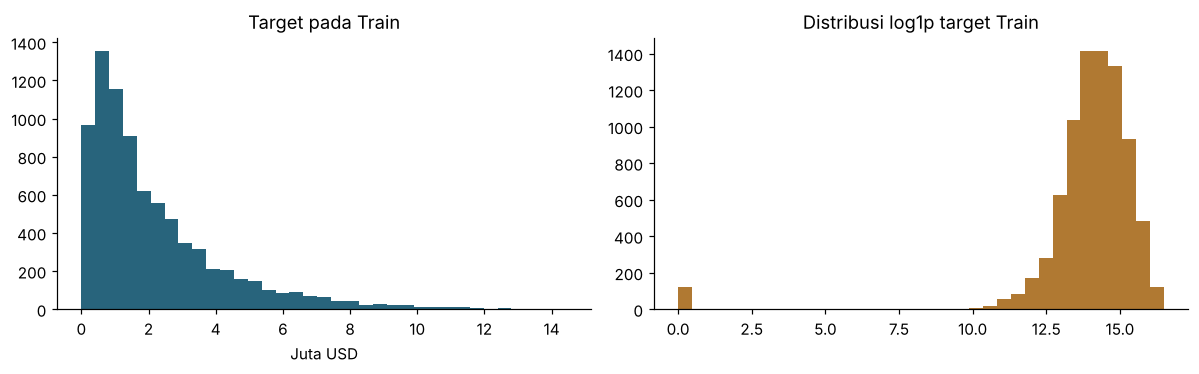

,Customer_ID,As_Of_Date,History_Start_Date,Frequency_12M,Contract_Count_12M,Historical_Contribution_12M_USD,Target_Start_Date,Target_End_Date,Future_6M_CLV_Proxy_USD
0,CUST-0001,2022-09-30,2021-10-01,6,6,1339970,2022-10-01,2023-03-31,"677,196.9500"


In [26]:
parts={s:panel.loc[panel.Split.eq(s)].reset_index(drop=True) for s in SPLITS}
TARGET='Future_6M_CLV_Proxy_USD'
feature_missing=pd.DataFrame({'Feature':panel.select_dtypes(include=np.number).columns})
for s in SPLITS:feature_missing[s]=feature_missing.Feature.map(parts[s].isna().mean()).values
display(feature_missing.loc[feature_missing[SPLITS].max(axis=1).gt(0)])
save_table(feature_missing,'07_feature_missing')
train_target=parts['Train'][TARGET]
fig,ax=plt.subplots(1,2,figsize=(11,3.5))
ax[0].hist(train_target/1e6,bins=35,color='#28647c');ax[0].set(title='Target pada Train',xlabel='Juta USD')
ax[1].hist(np.log1p(train_target),bins=35,color='#b07932');ax[1].set(title='Distribusi log1p target Train')
plt.tight_layout();finish_plot('08_target_train','data_preparation')
example=parts['Train'].iloc[0]
display(pd.DataFrame([example[['Customer_ID','As_Of_Date','History_Start_Date','Frequency_12M',
    'Contract_Count_12M','Historical_Contribution_12M_USD','Target_Start_Date','Target_End_Date',TARGET]]]))
save_table(pd.DataFrame([example]),'09_snapshot_example')

### 2.12 Bukti perhitungan satu snapshot

In [27]:
sample=parts['Train'].iloc[len(parts['Train'])//2]
tx=raw.loc[raw.Customer_ID.eq(sample.Customer_ID)].copy()
hist_sample=tx.loc[tx.Transaction_Date.between(sample.History_Start_Date,sample.As_Of_Date)]
future_sample=tx.loc[tx.Transaction_Date.between(sample.Target_Start_Date,sample.Target_End_Date)]
mm=(future_sample.Transaction_Date.dt.year-sample.As_Of_Date.year)*12+future_sample.Transaction_Date.dt.month-sample.As_Of_Date.month
manual_target=float((future_sample.Contribution_USD/(1+DISCOUNT)**(mm/12)).sum())
snapshot_proof=pd.DataFrame([{'Snapshot_ID':sample.Snapshot_ID,'Historical_Transactions':len(hist_sample),
    'Panel_Frequency':sample.Frequency_12M,'Historical_Contribution_Check':hist_sample.Contribution_USD.sum(),
    'Panel_Historical_Contribution':sample.Historical_Contribution_12M_USD,
    'Calculated_Target':round(manual_target,2),'Panel_Target':sample[TARGET]}])
display(snapshot_proof);display(hist_sample[['Transaction_ID','Transaction_Date','Contract_ID','Quantity_Tonnes','Contribution_USD']].head(12))
assert np.isclose(manual_target,sample[TARGET],atol=.011)
save_table(snapshot_proof,'15_snapshot_calculation_proof')
save_table(hist_sample,'16_example_historical_transactions')
save_table(future_sample,'17_example_target_transactions')

,Snapshot_ID,Historical_Transactions,Panel_Frequency,Historical_Contribution_Check,Panel_Historical_Contribution,Calculated_Target,Panel_Target
0,CUST-0363_2023-10-31,38,38,18341400,18341400,"9,922,359.3900","9,922,359.3900"


,Transaction_ID,Transaction_Date,Contract_ID,Quantity_Tonnes,Contribution_USD
3405,TX-07118,2022-11-01,CTR-00538,58000,749940
3701,TX-07796,2022-12-01,CTR-02605,10000,133700
3910,TX-08239,2022-12-19,CTR-00538,42000,610680
4094,TX-08560,2023-01-07,CTR-02895,41000,465350
4136,TX-08622,2023-01-09,CTR-02928,45000,479700
4205,TX-08764,2023-01-14,CTR-02991,27000,333450
4283,TX-08956,2023-01-21,CTR-02928,13000,121810
4564,TX-09534,2023-02-13,CTR-02928,46000,622380
4845,TX-10126,2023-03-09,CTR-02928,52000,695240
4944,TX-10334,2023-03-16,CTR-03508,9000,74700


### 2.13 Pisahkan fitur, target, dan metadata
Identitas, label Split, dan nilai masa depan tidak menjadi fitur model.

In [28]:
CORE_FEATURES=['Tenure_Days','Recency_Days','Frequency_12M','Active_Months_12M',
    'Historical_Revenue_12M_USD','Historical_Contribution_12M_USD','Average_Transaction_Value_USD',
    'Total_Quantity_12M_Tonnes','Average_Quantity_Tonnes','Average_Final_Price_USD_ton',
    'Product_Variety_12M','Contract_Count_12M','Term_Transaction_Share',
    'Avg_Payment_Delay_Days','Quality_Compliance_Rate',
    'Payment_Delay_Unavailable','Quality_Rate_Unavailable']
RECENT_FEATURES=['Frequency_3M','Frequency_6M','Contribution_3M_USD','Contribution_6M_USD',
    'Quantity_3M_Tonnes','Quantity_6M_Tonnes','Active_Months_3M','Active_Months_6M',
    'Average_Price_3M','Average_Price_6M','Contribution_Per_Tonne','Recent_Contribution_Share',
    'Recent_Frequency_Share','Contribution_Momentum','Monthly_Contribution_CV',
    'Median_Interpurchase_Days','Average_Market_Index','Recent_Price_Change']
FEATURE_SETS={'core':CORE_FEATURES,'recent':CORE_FEATURES+RECENT_FEATURES}

CONTRACT_FEATURES=['Active_Contract_Count','Active_Term_Contract_Count','Active_Multiyear_Count',
    'Remaining_Term_Days_Mean','Remaining_Term_Days_Max','Expiring_90D_Share',
    'No_Active_Term_Flag','Observed_Contract_Duration_Mean','AsOf_Month_Sin','AsOf_Month_Cos']
FEATURE_SETS['contract']=CORE_FEATURES+RECENT_FEATURES+CONTRACT_FEATURES
ALL_FEATURES=list(dict.fromkeys(c for cols in FEATURE_SETS.values() for c in cols))
assert not any(c.startswith('Future_') or c.endswith('_ID') for c in ALL_FEATURES)
roles=pd.DataFrame({'Column':panel.columns})
roles['Role']=roles.Column.map(lambda c:'candidate_feature' if c in ALL_FEATURES else
    'target_or_future_evaluation' if c.startswith('Future_') else 'historical_benchmark' if c.startswith('Baseline_') else 'metadata_or_context')
display(roles);save_table(roles,'18_feature_roles')
print('Fitur per kelompok:',{k:len(v) for k,v in FEATURE_SETS.items()})

,Column,Role
0,Snapshot_ID,metadata_or_context
1,Customer_ID,metadata_or_context
2,As_Of_Date,metadata_or_context
3,History_Start_Date,metadata_or_context
4,Target_Start_Date,metadata_or_context
5,Target_End_Date,metadata_or_context
6,Country,metadata_or_context
7,Industry,metadata_or_context
8,Tenure_Days,candidate_feature
9,Recency_Days,candidate_feature


Fitur per kelompok: {'core': 17, 'recent': 35, 'contract': 45}


### 2.14 Penanganan missing value
Median dipelajari dari Train. Pada pelatihan model, imputer dibuat ulang di setiap fold.

In [29]:
preview_imputer=SimpleImputer(strategy='median',keep_empty_features=True)
preview_imputer.fit(parts['Train'][FEATURE_SETS['recent']])
imputation_audit=pd.DataFrame({'Feature':FEATURE_SETS['recent'],'Train_Missing':parts['Train'][FEATURE_SETS['recent']].isna().sum().values,
    'Train_Median':preview_imputer.statistics_})
display(imputation_audit.loc[imputation_audit.Train_Missing.gt(0)])
save_table(imputation_audit,'10_imputation_audit')

,Feature,Train_Missing,Train_Median
13,Avg_Payment_Delay_Days,190,5.8571
25,Average_Price_3M,449,83.6694
26,Average_Price_6M,33,84.6367
32,Median_Interpurchase_Days,214,19.5000
34,Recent_Price_Change,449,-0.3413


### 2.15 Nilai ekstrem pada Train

In [30]:
extreme_rows=[]
for col in ALL_FEATURES:
    x=parts['Train'][col].dropna()
    q1,q3=x.quantile(.25),x.quantile(.75);iqr=q3-q1
    extreme_rows.append({'Feature':col,'P01':x.quantile(.01),'Median':x.median(),'P99':x.quantile(.99),
        'IQR_Lower':q1-1.5*iqr,'IQR_Upper':q3+1.5*iqr,
        'Outside_IQR':int((x.lt(q1-1.5*iqr)|x.gt(q3+1.5*iqr)).sum())})
extremes=pd.DataFrame(extreme_rows)
display(extremes.sort_values('Outside_IQR',ascending=False).head(15))
save_table(extremes,'19_train_extreme_values')
print('Nilai ekstrem ditinjau, bukan otomatis dihapus; seluruh transaksi tetap dipertahankan.')

,Feature,P01,Median,P99,IQR_Lower,IQR_Upper,Outside_IQR
35,Active_Contract_Count,0.0000,1.0000,3.0000,1.0000,1.0000,3026
36,Active_Term_Contract_Count,0.0000,1.0000,1.0000,1.0000,1.0000,1574
41,No_Active_Term_Flag,0.0000,0.0000,1.0000,0.0000,0.0000,1574
34,Recent_Price_Change,-11.2933,-0.3413,8.4853,-6.2665,4.4005,739
42,Observed_Contract_Duration_Mean,31.0000,114.5000,366.0000,2.2923,228.3846,627
28,Recent_Contribution_Share,0.0000,0.2591,1.0000,-0.2125,0.7593,611
29,Recent_Frequency_Share,0.0000,0.2667,1.0000,-0.1228,0.6959,602
30,Contribution_Momentum,"-1,626,787.0000","15,870.0000","1,691,439.2000","-990,287.5000","1,022,452.5000",594
37,Active_Multiyear_Count,0.0000,0.0000,1.0000,0.0000,0.0000,588
5,Historical_Contribution_12M_USD,"142,665.2000","2,958,820.0000","18,827,130.8000","-4,707,490.0000","12,036,110.0000",545


Nilai ekstrem ditinjau, bukan otomatis dihapus; seluruh transaksi tetap dipertahankan.


### 2.16 Preview transformasi dan scaling

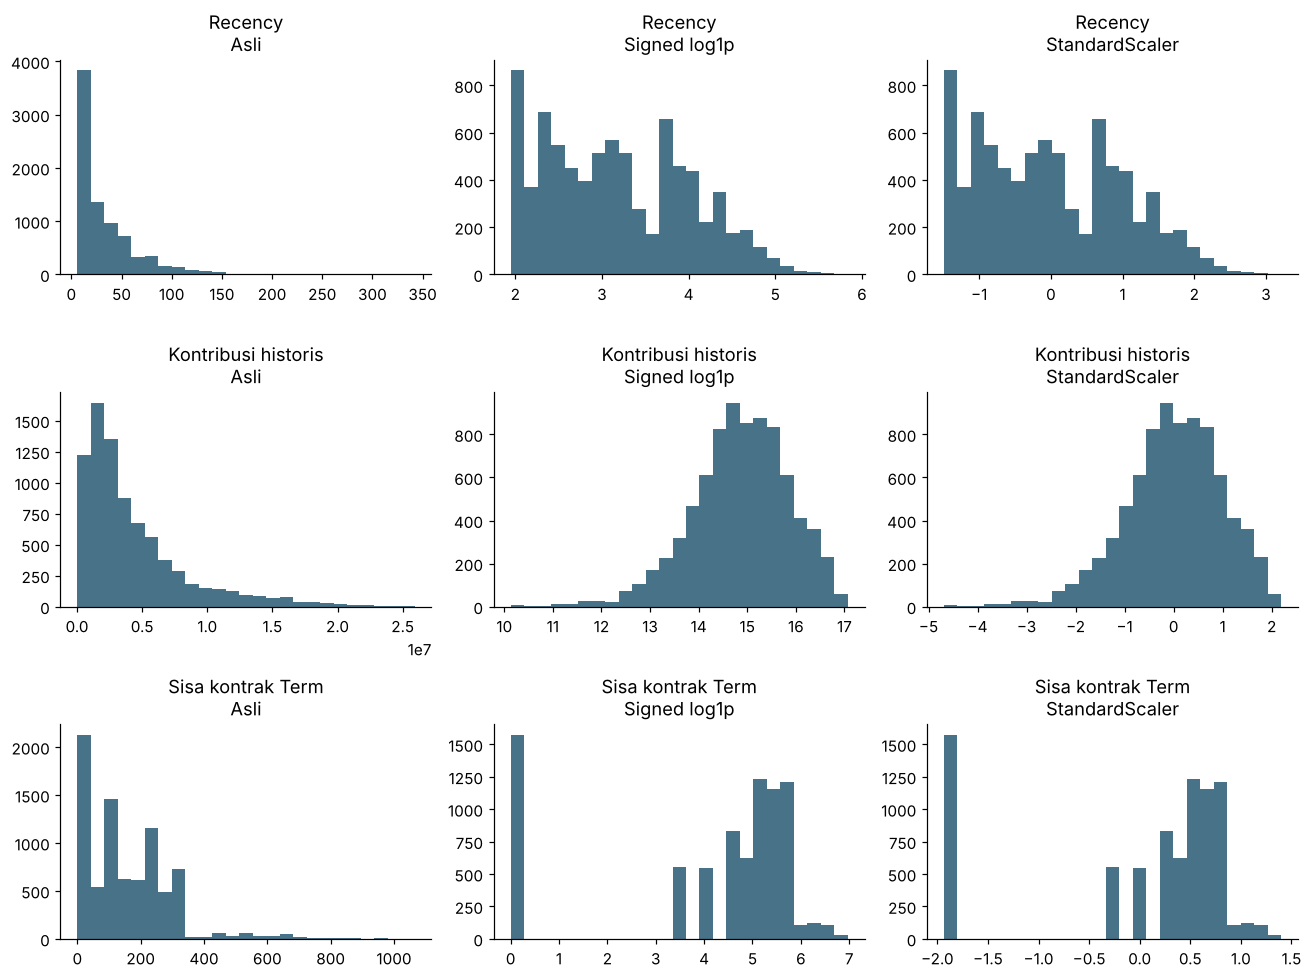

In [31]:
preview_cols=['Recency_Days','Historical_Contribution_12M_USD','Remaining_Term_Days_Max']
preview_data=parts['Train'][preview_cols].fillna(parts['Train'][preview_cols].median())
preview_log=np.sign(preview_data)*np.log1p(np.abs(preview_data))
preview_scaler=StandardScaler().fit(preview_log)
preview_scaled=preview_scaler.transform(preview_log)
display_names={'Recency_Days':'Recency','Historical_Contribution_12M_USD':'Kontribusi historis','Remaining_Term_Days_Max':'Sisa kontrak Term'}
fig,axes=plt.subplots(3,3,figsize=(12,9))
for j,c in enumerate(preview_cols):
    for i,(data,title) in enumerate([(preview_data[c],'Asli'),(preview_log[c],'Signed log1p'),(preview_scaled[:,j],'StandardScaler')]):
        axes[j,i].hist(data,bins=25,color='#477287');axes[j,i].set_title(display_names[c]+'\n'+title)
plt.tight_layout();finish_plot('20_transform_preview','data_preparation')

### 2.17 Hubungan antarfitur

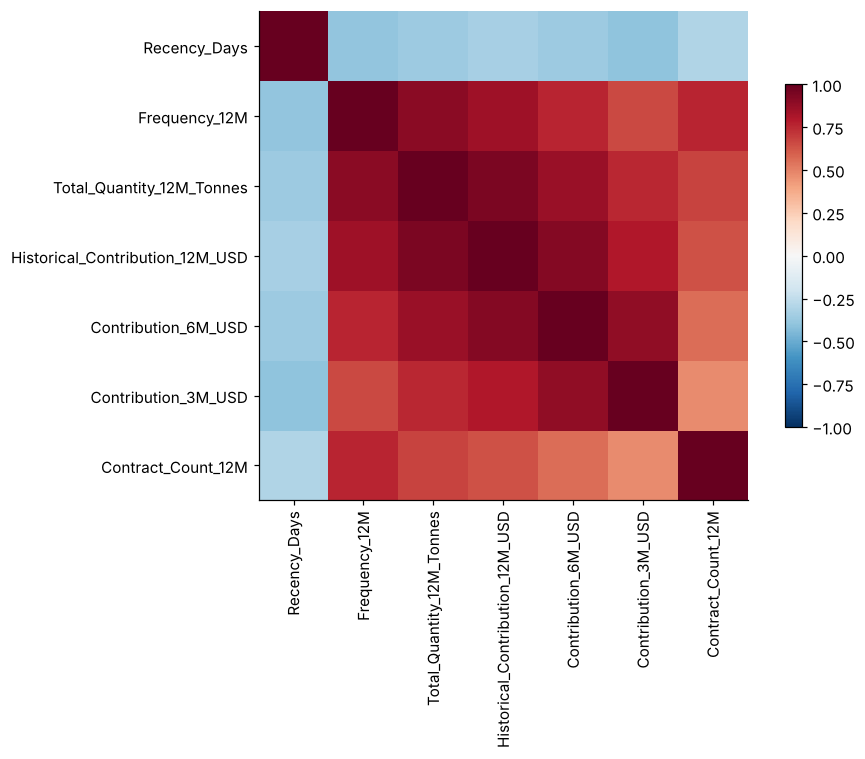

In [32]:
fig,ax=plt.subplots(figsize=(9,7))
cc=parts['Train'][['Recency_Days','Frequency_12M','Total_Quantity_12M_Tonnes',
    'Historical_Contribution_12M_USD','Contribution_6M_USD','Contribution_3M_USD','Contract_Count_12M']].corr()
im=ax.imshow(cc,vmin=-1,vmax=1,cmap='RdBu_r');ax.set_xticks(range(len(cc)),cc.columns,rotation=90)
ax.set_yticks(range(len(cc)),cc.columns);fig.colorbar(im,ax=ax,shrink=.7)
plt.tight_layout();finish_plot('12_feature_correlation_train','data_preparation')

### 2.18 Ekspor panel dan input setiap jalur

In [33]:
META_COLUMNS=['Snapshot_ID','Customer_ID','As_Of_Date','History_Start_Date','Target_Start_Date','Target_End_Date','Split']
matrix_summary=[]
for split,df in parts.items():
    save_table(df,f'panel_{split.lower()}')
    save_table(df[META_COLUMNS],f'metadata_{split.lower()}')
    save_table(df[['Snapshot_ID',TARGET]],f'target_{split.lower()}')
    for group,cols in FEATURE_SETS.items():
        save_table(df[['Snapshot_ID']+cols],f'X_input_{group}_{split.lower()}')
        matrix_summary.append({'Feature_Set':group,'Split':split,'Rows':len(df),'Features':len(cols)})
display(pd.DataFrame(matrix_summary));save_table(pd.DataFrame(matrix_summary),'21_input_matrix_summary')

,Feature_Set,Split,Rows,Features
0,core,Train,8097,17
1,recent,Train,8097,35
2,contract,Train,8097,45
3,core,Validation,1573,17
4,recent,Validation,1573,35
5,contract,Validation,1573,45
6,core,Test,1572,17
7,recent,Test,1572,35
8,contract,Test,1572,45


### 2.19 Rencana validasi temporal di dalam Train
Target training harus selesai paling lambat pada tanggal prediksi fold berikutnya.

In [34]:
def temporal_folds(frame,max_folds=3,min_train=250):
    candidates=[]
    for date in sorted(frame.As_Of_Date.unique(),reverse=True):
        date=pd.Timestamp(date)
        tr=np.flatnonzero((frame.As_Of_Date.lt(date)&frame.Target_End_Date.le(date)).to_numpy())
        va=np.flatnonzero(frame.As_Of_Date.eq(date).to_numpy())
        if len(tr)>=min_train and len(va)>=50:
            if not candidates or (candidates[-1]['origin']-date).days>=50:
                candidates.append({'origin':date,'train':tr,'valid':va})
        if len(candidates)==max_folds:break
    return list(reversed(candidates))
main_cv_plan=[]
for no,f in enumerate(temporal_folds(parts['Train']),1):
    tr,va=parts['Train'].iloc[f['train']],parts['Train'].iloc[f['valid']]
    main_cv_plan.append({'Fold':no,'Validation_Origin':f['origin'],'Train_Rows':len(tr),'Validation_Rows':len(va),
        'Last_Training_Target_End':tr.Target_End_Date.max()})
    assert tr.Target_End_Date.max()<=va.As_Of_Date.min()
    save_table(tr[['Snapshot_ID']],f'cv_{no:02d}_train_ids')
    save_table(va[['Snapshot_ID']],f'cv_{no:02d}_validation_ids')
display(pd.DataFrame(main_cv_plan));save_table(pd.DataFrame(main_cv_plan),'22_main_temporal_cv_plan')

,Fold,Validation_Origin,Train_Rows,Validation_Rows,Last_Training_Target_End
0,1,2024-05-31,4433,374,2024-05-31
1,2,2024-07-31,5142,375,2024-07-31
2,3,2024-09-30,5852,375,2024-09-30


## 3 Modeling Segmentasi K-Means
### 3.1 Unit pelatihan dan kandidat fitur
Gunakan snapshot terakhir tiap customer pada Train. RFM menjadi kontrol; model utama tetap memuat karakter B2B.

In [35]:
cluster_sets={
    'RFM_control':['Recency_Days','Frequency_12M','Historical_Contribution_12M_USD'],
    'B2B_core':['Recency_Days','Frequency_12M','Total_Quantity_12M_Tonnes',
                'Contribution_Per_Tonne','Term_Transaction_Share','Product_Variety_12M'],
    'B2B_value':['Recency_Days','Frequency_12M','Historical_Contribution_12M_USD',
                 'Contribution_Per_Tonne','Term_Transaction_Share'],
    'B2B_extended':['Recency_Days','Frequency_12M','Historical_Contribution_12M_USD',
                    'Contribution_Per_Tonne','Term_Transaction_Share','Product_Variety_12M',
                    'Monthly_Contribution_CV','Recent_Frequency_Share']}
cluster_sets['B2B_contract']=['Recency_Days','Frequency_12M','Historical_Contribution_12M_USD',
    'Term_Transaction_Share','Remaining_Term_Days_Max','Active_Multiyear_Count']
def latest_customer(df):
    return df.sort_values(['As_Of_Date','Customer_ID']).drop_duplicates('Customer_ID',keep='last').reset_index(drop=True)
cluster_train=latest_customer(parts['Train'])
cluster_valid=latest_customer(parts['Validation'])
def cluster_prepare(train, columns, method):
    imp=SimpleImputer(strategy='median',keep_empty_features=True)
    a=imp.fit_transform(train[columns])
    if method=='yeo_johnson':
        variable=np.ptp(a,axis=0)>1e-10
        power=PowerTransformer(standardize=False)
        b=a.copy();b[:,variable]=power.fit_transform(a[:,variable])
        scaler=StandardScaler().fit(b)
        return {'columns':columns,'method':method,'imputer':imp,'power':power,'variable':variable,'scaler':scaler}
    b=np.sign(a)*np.log1p(np.abs(a))
    scaler=(RobustScaler() if method=='log_robust' else StandardScaler()).fit(b)
    return {'columns':columns,'method':method,'imputer':imp,'scaler':scaler}
def cluster_transform(bundle,df):
    a=bundle['imputer'].transform(df[bundle['columns']])
    if bundle['method']=='yeo_johnson':
        a=a.copy();v=bundle['variable'];a[:,v]=bundle['power'].transform(a[:,v])
    else:a=np.sign(a)*np.log1p(np.abs(a))
    return bundle['scaler'].transform(a)
def cluster_metrics(x,labels):
    if len(np.unique(labels))<2 or len(np.unique(labels))>=len(labels):
        return {'Silhouette':np.nan,'DBI':np.nan,'CH':np.nan,'Min_Share':0.}
    return {'Silhouette':float(silhouette_score(x,labels)),
        'DBI':float(davies_bouldin_score(x,labels)),
        'CH':float(calinski_harabasz_score(x,labels)),
        'Min_Share':float(pd.Series(labels).value_counts(normalize=True).min())}

### 3.2 Pencarian fitur, skala, dan jumlah cluster
Pemilihan memakai Train dan Validation; Test belum digunakan.

In [36]:
cluster_results=[];cluster_bundles={}
with threadpool_limits(limits=N_JOBS):
    for group,columns0 in cluster_sets.items():
        corr=cluster_train[columns0].corr().abs()
        columns=[c for i,c in enumerate(columns0) if cluster_train[c].nunique()>1 and not any(corr.iloc[i,:i].gt(.95))]
        for method in ['log_standard','log_robust','yeo_johnson']:
            pre=cluster_prepare(cluster_train,columns,method)
            xt,xv=cluster_transform(pre,cluster_train),cluster_transform(pre,cluster_valid)
            for k in range(2,9):
                km=KMeans(n_clusters=k,n_init=40,max_iter=500,random_state=SEED).fit(xt)
                lt,lv=km.labels_,km.predict(xv)
                mt,mv=cluster_metrics(xt,lt),cluster_metrics(xv,lv)
                ari=[]
                for seed in [17,39,71]:
                    rng=np.random.default_rng(seed)
                    sub=rng.choice(len(xt),int(.8*len(xt)),replace=False)
                    alt=KMeans(n_clusters=k,n_init=10,random_state=seed).fit(xt[sub])
                    ari.append(adjusted_rand_score(lt,alt.predict(xt)))
                key=f'{group}|{method}|k={k}'
                row={'Candidate':key,'Feature_Set':group,'Transform':method,'K':k,'Features':len(columns),
                     'Train_Inertia':km.inertia_,'Stability_ARI':float(np.mean(ari)),
                     **{'Train_'+a:b for a,b in mt.items()},**{'Validation_'+a:b for a,b in mv.items()}}
                row['Admissible']=min(mt['Min_Share'],mv['Min_Share'])>=.05 and len(np.unique(lv))==k
                row['Selection_Score']=.65*mv['Silhouette']+.20*mt['Silhouette']+.15*row['Stability_ARI']
                cluster_results.append(row);cluster_bundles[key]={'preprocessor':pre,'model':km}
cluster_results=pd.DataFrame(cluster_results)
admissible=cluster_results.loc[cluster_results.Admissible & cluster_results.Feature_Set.ne('RFM_control')]
if admissible.empty:raise ValueError('Tidak ada kandidat B2B dengan ukuran cluster minimal 5%; tinjau fitur dan distribusi.')
cluster_choice=admissible.sort_values(['Selection_Score','Validation_DBI'],ascending=[False,True]).iloc[0]
cluster_bundle=cluster_bundles[cluster_choice.Candidate]
display(cluster_results.sort_values('Selection_Score',ascending=False).head(12))
print('Kandidat dipilih:',cluster_choice.Candidate)
print('Silhouette antarhimpunan fitur dibaca pada ruang fitur masing-masing, bukan kenaikan kualitas yang otomatis setara.')
save_table(cluster_results,'01_kmeans_candidates','segmentation')
write_json(cluster_choice.to_dict(),RUN_DIR/'segmentation'/'selection_before_test.json')
joblib.dump(cluster_bundle,RUN_DIR/'models'/'kmeans.joblib')

,Candidate,Feature_Set,Transform,K,Features,Train_Inertia,Stability_ARI,Train_Silhouette,Train_DBI,Train_CH,Train_Min_Share,Validation_Silhouette,Validation_DBI,Validation_CH,Validation_Min_Share,Admissible,Selection_Score
7,RFM_control|log_robust|k=2,RFM_control,log_robust,2,3,245.0713,0.9753,0.4380,0.8490,411.4369,0.4880,0.4346,0.8358,447.0968,0.4786,True,0.5164
14,RFM_control|yeo_johnson|k=2,RFM_control,yeo_johnson,2,3,540.4970,1.0000,0.4327,0.8705,403.3688,0.4747,0.4280,0.8565,441.9933,0.4635,True,0.5148
0,RFM_control|log_standard|k=2,RFM_control,log_standard,2,3,549.7924,0.9789,0.4301,0.8687,390.2427,0.4747,0.4269,0.8549,428.4885,0.4811,True,0.5104
92,B2B_contract|log_robust|k=3,B2B_contract,log_robust,3,6,408.9968,0.9828,0.3920,0.8445,286.6282,0.0320,0.4326,0.8355,751.5612,0.1360,False,0.5070
86,B2B_contract|log_standard|k=4,B2B_contract,log_standard,4,6,827.7125,0.9903,0.3946,0.8552,212.5008,0.0320,0.4284,0.8509,398.8819,0.0605,False,0.5059
87,B2B_contract|log_standard|k=5,B2B_contract,log_standard,5,6,696.6111,0.9462,0.3650,0.9784,206.2678,0.0320,0.3994,1.0542,344.0199,0.0605,False,0.4746
85,B2B_contract|log_standard|k=3,B2B_contract,log_standard,3,6,"1,160.7895",0.9760,0.3509,0.9827,174.5305,0.0320,0.3936,0.9570,438.7983,0.1360,False,0.4724
101,B2B_contract|yeo_johnson|k=5,B2B_contract,yeo_johnson,5,6,814.0176,0.9276,0.3554,0.9869,163.1763,0.0320,0.3928,0.9894,275.7744,0.0630,False,0.4656
93,B2B_contract|log_robust|k=4,B2B_contract,log_robust,4,6,333.8375,0.9331,0.3449,1.0267,261.3186,0.0320,0.3863,1.0722,600.6407,0.1360,False,0.4600
102,B2B_contract|yeo_johnson|k=6,B2B_contract,yeo_johnson,6,6,692.9860,0.8075,0.3712,0.9888,165.8152,0.0320,0.3980,1.0564,239.4916,0.0252,False,0.4541


Kandidat dipilih: B2B_value|log_robust|k=2
Silhouette antarhimpunan fitur dibaca pada ruang fitur masing-masing, bukan kenaikan kualitas yang otomatis setara.


['hasil_skripsi_v3/c54a270360_standard_v3/models/kmeans.joblib']

### 3.3 Elbow, silhouette, dan DBI

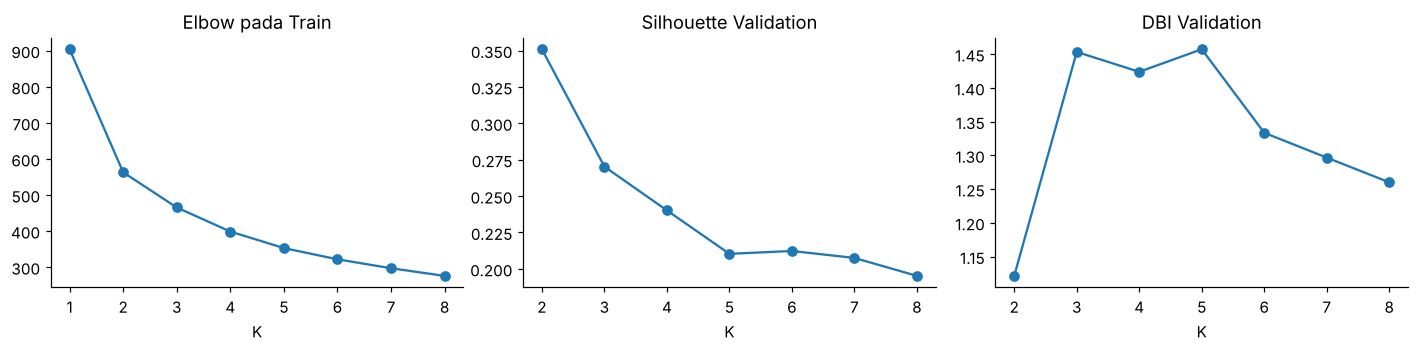

In [37]:
selected_grid=cluster_results.loc[(cluster_results.Feature_Set==cluster_choice.Feature_Set)&
    (cluster_results.Transform==cluster_choice.Transform)].sort_values('K')
fig,ax=plt.subplots(1,3,figsize=(13,3.3))
for a,col,title in zip(ax,['Train_Inertia','Validation_Silhouette','Validation_DBI'],['Elbow pada Train','Silhouette Validation','DBI Validation']):
    if col=='Train_Inertia':
        xx=cluster_transform(cluster_bundle['preprocessor'],cluster_train)
        inertia_one=float(((xx-xx.mean(axis=0))**2).sum())
        a.plot([1]+selected_grid.K.tolist(),[inertia_one]+selected_grid[col].tolist(),marker='o')
    else:a.plot(selected_grid.K,selected_grid[col],marker='o')
    a.set(xlabel='K',title=title)
plt.tight_layout();finish_plot('02_kmeans_metrics','segmentation')

### 3.4 Stabilitas model terpilih

In [38]:
xx=cluster_transform(cluster_bundle['preprocessor'],cluster_train)
stability=[]
with threadpool_limits(limits=N_JOBS):
    reference=cluster_bundle['model'].predict(xx)
    for seed in range(10):
        rng=np.random.default_rng(SEED+seed)
        subset=rng.choice(len(xx),int(.8*len(xx)),replace=False)
        alt=KMeans(n_clusters=int(cluster_choice.K),n_init=20,random_state=SEED+seed).fit(xx[subset])
        stability.append({'Seed':SEED+seed,'ARI':adjusted_rand_score(reference,alt.predict(xx))})
display(pd.DataFrame(stability));save_table(pd.DataFrame(stability),'04_selected_stability','segmentation')

,Seed,ARI
0,20261019,0.9893
1,20261020,0.9577
2,20261021,1.0000
3,20261022,0.9787
4,20261023,1.0000
5,20261024,0.9893
6,20261025,1.0000
7,20261026,0.9893
8,20261027,0.9682
9,20261028,0.9577


### 3.5 Profil segmen dalam satuan asli

In [39]:
labels_train=cluster_bundle['model'].predict(cluster_transform(cluster_bundle['preprocessor'],cluster_train))
train_profile=cluster_train.assign(Cluster=labels_train).groupby('Cluster').agg(
    Customers=('Customer_ID','size'),Recency=('Recency_Days','median'),Frequency=('Frequency_12M','median'),
    Quantity_Tonnes=('Total_Quantity_12M_Tonnes','median'),Contribution_USD=('Historical_Contribution_12M_USD','median'),
    Term_Share=('Term_Transaction_Share','median')).reset_index()
display(train_profile);save_table(train_profile,'03_train_profile','segmentation')

,Cluster,Customers,Recency,Frequency,Quantity_Tonnes,Contribution_USD,Term_Share
0,0,201,15.0000,20.0000,"671,000.0000","5,491,470.0000",0.7955
1,1,174,44.0000,6.0000,"178,000.0000","1,489,345.0000",0.5000


### 3.6 Label Train dan Validation

In [40]:
for split in ['Train','Validation']:
    df=parts[split]
    labels=cluster_bundle['model'].predict(cluster_transform(cluster_bundle['preprocessor'],df))
    labeled=df[['Snapshot_ID','Customer_ID','As_Of_Date']].assign(Cluster=labels)
    save_table(labeled,f'labels_{split.lower()}','segmentation')
display(train_profile)

,Cluster,Customers,Recency,Frequency,Quantity_Tonnes,Contribution_USD,Term_Share
0,0,201,15.0000,20.0000,"671,000.0000","5,491,470.0000",0.7955
1,1,174,44.0000,6.0000,"178,000.0000","1,489,345.0000",0.5000


### 3.7 Visualisasi dua dimensi

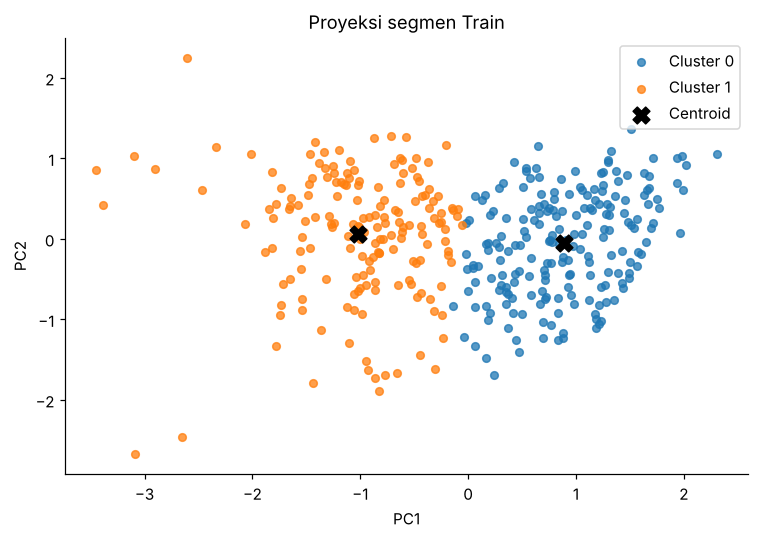

PCA dipakai untuk gambar; K-Means tetap bekerja pada ruang fitur yang dipilih.


In [41]:
from sklearn.decomposition import PCA
pca=PCA(n_components=2).fit(xx)
xy=pca.transform(xx)
centers=pca.transform(cluster_bundle['model'].cluster_centers_)
fig,ax=plt.subplots(figsize=(7,5))
palette=plt.get_cmap('tab10')
for label in sorted(np.unique(labels_train)):
    mask=labels_train==label
    ax.scatter(xy[mask,0],xy[mask,1],color=palette(int(label)),s=25,alpha=.75,label=f'Cluster {label}')
ax.scatter(centers[:,0],centers[:,1],c='black',marker='X',s=120,label='Centroid')
ax.set(title='Proyeksi segmen Train',xlabel='PC1',ylabel='PC2');ax.legend()
plt.tight_layout();finish_plot('05_cluster_projection_train','segmentation')
print('PCA dipakai untuk gambar; K-Means tetap bekerja pada ruang fitur yang dipilih.')

### 3.8 Perbandingan profil segmen

,Recency_Days,Frequency_12M,Total_Quantity_12M_Tonnes,Historical_Contribution_12M_USD,Term_Transaction_Share,Remaining_Term_Days_Max
Cluster,,,,,,
0,15.0000,20.0000,"671,000.0000","5,491,470.0000",0.7955,92.0000
1,44.0000,6.0000,"178,000.0000","1,489,345.0000",0.5000,92.0000


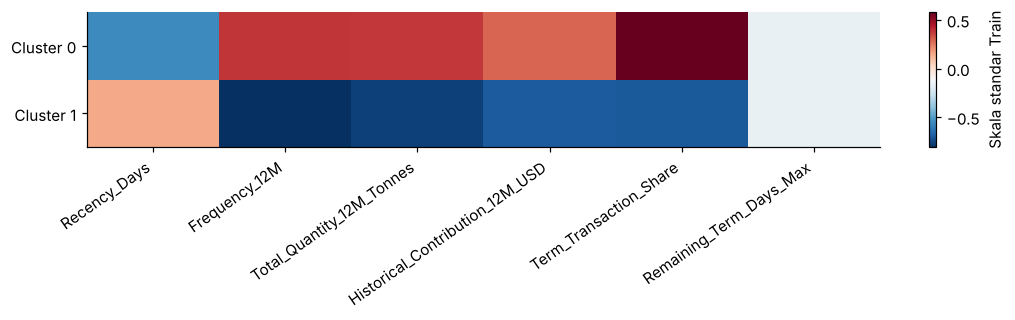

In [42]:
profile_columns=['Recency_Days','Frequency_12M','Total_Quantity_12M_Tonnes',
    'Historical_Contribution_12M_USD','Term_Transaction_Share','Remaining_Term_Days_Max']
profile_detail=cluster_train.assign(Cluster=labels_train).groupby('Cluster')[profile_columns].median()
scaled_profiles=pd.DataFrame(StandardScaler().fit(cluster_train[profile_columns]).transform(profile_detail),
    index=profile_detail.index,columns=profile_columns)
display(profile_detail)
fig,ax=plt.subplots(figsize=(10,3))
im=ax.imshow(scaled_profiles,cmap='RdBu_r',aspect='auto')
ax.set_xticks(range(len(profile_columns)),profile_columns,rotation=35,ha='right')
ax.set_yticks(range(len(profile_detail)),['Cluster '+str(k) for k in profile_detail.index])
fig.colorbar(im,ax=ax,label='Skala standar Train');plt.tight_layout()
finish_plot('06_segment_profile_heatmap','segmentation')
save_table(profile_detail.reset_index(),'06_train_profile_detail','segmentation')

## 4 Modeling Base Learner
### 4.0 Log eksperimen v3 (Validation)
Setiap ide dijalankan sebagai eksperimen terpisah pada notebook pendamping `Eksperimen_v3_Validation.ipynb`, yang tidak pernah membaca Test. Tabel di bawah dibaca dari keluaran notebook tersebut (`log_eksperimen_validation.csv`). Kolom CV adalah RMSE validasi temporal di dalam Train, kolom OOF adalah RMSE prediksi out-of-fold (stacking dinilai maju per blok waktu), dan kolom Validation adalah skor pada Validation. Skor Test tidak dicantumkan di log ini.

Aturan keputusan: perubahan dipertahankan bila memperbaiki RMSE Validation stacking tanpa memperburuk base learner, dan arah perbaikannya konsisten (bootstrap per customer, 1.000 kali). Perbaikan metodologi (misalnya early stopping yang tidak lagi melihat fold yang dinilai) tetap dipakai selama Validation tidak memburuk.

In [43]:
log_path = Path('log_eksperimen_validation.csv')
if log_path.exists():
    experiment_log = pd.read_csv(log_path)
    display(experiment_log)
    shutil.copy(log_path, RUN_DIR/'models'/'00_log_eksperimen_validation.csv')
else:
    print('log_eksperimen_validation.csv belum ada di folder notebook.')
    print('Jalankan Eksperimen_v3_Validation.ipynb untuk menghasilkan log; pipeline final di bawah tetap berjalan.')

,Eksperimen,Perubahan,CV_RMSE_RandomForest,CV_RMSE_XGBoost,CV_RMSE_LightGBM,CV_RMSE_MLP,OOF_RMSE_BaseTerbaik,OOF_RMSE_Stacking,Meta,...,Val_R2_BaseTerbaik,Val_R2_RandomForest,Val_R2_XGBoost,Val_R2_LightGBM,Val_R2_MLP,Keputusan,Pembanding,Delta_Val_RMSE,P_Lebih_Baik
0,E0,Reproduksi v2 (early stopping pada fold yang d...,"1,041,591.2387","1,009,131.7467","1,010,598.7935","1,021,772.5349","1,293,369.3266","1,279,376.6245",Ridge 1000.0 predictions_only,...,0.7120,0.7120,0.7076,0.7091,0.7028,Acuan,NaN,NaN,NaN
1,E1,Early stopping pada set terpisah + refit,"1,041,591.2387","1,031,664.4813","1,044,264.2017","1,022,624.8452","1,280,884.5365","1,257,199.7001",Ridge 1000.0 predictions_only,...,0.7120,0.7120,0.7076,0.7079,0.7022,"Dipakai (perbaikan metodologi, Validation tida...",E0,"-2,336.9378",0.6860
2,E1b,Early stopping terpisah tanpa refit,"1,041,591.2387","1,055,015.0203","1,057,446.5964","1,046,532.7829","1,282,606.9324","1,244,195.0774",ElasticNet 0.1 predictions_and_history,...,0.7120,0.7120,0.7076,0.6953,0.6647,Tidak dipakai,E1,"8,809.6701",0.0850
3,E2,Kandidat Tweedie (XGB/LGB) dan log1p (RF/MLP),"1,037,522.3699","1,000,823.8890","1,016,437.8215","1,022,624.8452","1,282,279.2632","1,250,475.2187",Convex 1.0 predictions_only,...,0.7124,0.6844,0.7080,0.7124,0.7022,Sebagian: log1p RF memperburuk Validation,E1,"1,320.4666",0.4710
4,E2b,Tweedie hanya untuk XGB/LGB,"1,041,591.2387","1,000,823.8890","1,016,437.8215","1,022,624.8452","1,282,279.2632","1,256,502.2734",Ridge 1000.0 predictions_only,...,0.7124,0.7120,0.7080,0.7124,0.7022,Dipakai: CV XGBoost/LightGBM dan Validation st...,E1,"-2,210.3190",0.7960
5,E3,Fitur as-of tambahan (kelompok extended),"1,041,591.2387","1,031,664.4813","1,044,264.2017","1,022,624.8452","1,289,029.9313","1,261,065.0295",Ridge 1000.0 predictions_only,...,0.7120,0.7120,0.7076,0.7079,0.7022,Tidak dipakai: CV temporal tidak memilih kelom...,E1,794.4473,0.2230
6,E5a,Bobot kebaruan half-life 12 bulan,"1,049,198.7253","1,010,815.3516","1,024,458.2298","1,022,624.8452","1,291,858.9656","1,257,988.1103",Ridge 1000.0 predictions_only,...,0.7092,0.7082,0.7080,0.7092,0.7022,Tidak dipakai: CV dan Validation memburuk,E2b,"1,055.8613",0.3590
7,E5b,Bobot kebaruan half-life 24 bulan,"1,040,295.1145","1,006,106.4883","1,018,459.8824","1,022,624.8452","1,287,049.5081","1,258,509.3111",Ridge 1000.0 predictions_only,...,0.7145,0.7095,0.7114,0.7145,0.7022,"Tidak dipakai: CV XGBoost/LightGBM memburuk, s...",E2b,"-1,535.3116",0.7550
8,E6,OOF 8 blok waktu,"1,041,591.2387","1,000,823.8890","1,016,437.8215","1,022,624.8452","1,281,745.5078","1,277,053.2712",Ridge 1000.0 predictions_only,...,0.7124,0.7120,0.7080,0.7124,0.7022,"Tidak dipakai: cakupan OOF sama, Validation ti...",E2b,40.5696,0.4650
9,E4,Optuna (TPE) + konfigurasi E2b,"1,027,251.6991","1,000,823.8890","1,002,114.4982","1,022,624.8452","1,293,523.4217","1,249,257.1195",ElasticNet 0.1 predictions_and_history,...,0.7127,0.7026,0.7080,0.7127,0.7022,Tidak dipakai: perbaikan CV tidak terbawa ke V...,E2b,159.7862,0.4680


### 4.1 Ruang pencarian parameter
Dua belas konfigurasi v2 per algoritma dipertahankan (kelompok fitur core/recent/contract × mode target direct/residual × hyperparameter). Pada v3, XGBoost dan LightGBM mendapat empat kandidat tambahan dengan objective Tweedie (log-link, cocok untuk target nonnegatif yang miring dan memuat nol). Kandidat log1p untuk Random Forest dan MLP diuji di log eksperimen (E2), tetapi tidak dipakai karena Validation memburuk.

In [44]:
ALGORITHMS=['RandomForest','XGBoost','LightGBM','MLP']
MAX_EPOCHS=160 if MODE=='standard' else 300
MAX_TREES=600 if MODE=='standard' else 1000
ES_MODE='inner_refit'      # v3: set early stopping terpisah dari fold yang dinilai, lalu refit
SAMPLE_HALF_LIFE=None   # bobot kebaruan base learner (bulan); None = tanpa bobot
def make_configs(algorithm):
    combos=[('core','direct'),('core','residual'),('recent','direct'),('recent','residual')]*2
    combos += [('contract','direct'),('contract','residual')]*2
    out=[]
    for j,(features,mode) in enumerate(combos):
        if algorithm=='RandomForest':
            params={'n_estimators':160 if j<4 else 240,'min_samples_leaf':[4,8,12,16][j%4],
                    'max_features':.8 if j%2 else 1.,'max_depth':12 if j<4 else None}
        elif algorithm=='XGBoost':
            params={'max_depth':[2,3,4,2][j%4],'learning_rate':.04 if j<4 else .025,
                    'min_child_weight':[15,25,35,15][j%4], 'reg_lambda':10. if j<4 else 30.,
                    'subsample':.85,'colsample_bytree':.85}
        elif algorithm=='LightGBM':
            params={'num_leaves':[7,15,15,7][j%4],'learning_rate':.04 if j<4 else .025,
                    'min_child_samples':[35,55,80,35][j%4],'reg_lambda':10. if j<4 else 25.,
                    'subsample':.85,'colsample_bytree':.85}
        else:
            params={'hidden_layer_sizes':[(32,),(64,),(64,32),(32,)][j%4],
                    'alpha':.1 if j<4 else 1.,'learning_rate_init':.002 if j<4 else .001,'activation':'relu'}
        if j >= 8:
            if algorithm == 'RandomForest':
                params.update(n_estimators=240, min_samples_leaf=[2,4,8,12][j%4], max_features=.65)
            elif algorithm == 'XGBoost':
                params.update(max_depth=[3,4,5,3][j%4], min_child_weight=10, reg_alpha=1.)
            elif algorithm == 'LightGBM':
                params.update(num_leaves=[15,31,31,15][j%4], min_child_samples=50, reg_alpha=1.)
            else:
                params.update(hidden_layer_sizes=(96,48), alpha=[.3,1.,3.,10.][j%4])
        out.append({'id':f'{algorithm}_{j:02d}','feature_set':features,'target_mode':mode,'params':params})
    # v3: kandidat objective Tweedie untuk model boosting
    for fs in ['recent','contract']:
        if algorithm=='XGBoost':
            for pw,md in [(1.3,3),(1.6,4)]:
                out.append({'id':f'{algorithm}_tw_{fs}_{pw}','feature_set':fs,'target_mode':'tweedie',
                    'params':{'max_depth':md,'learning_rate':.03,'min_child_weight':15,'reg_lambda':10.,
                              'subsample':.85,'colsample_bytree':.85,'tweedie_power':pw}})
        elif algorithm=='LightGBM':
            for pw,nl in [(1.3,15),(1.6,31)]:
                out.append({'id':f'{algorithm}_tw_{fs}_{pw}','feature_set':fs,'target_mode':'tweedie',
                    'params':{'num_leaves':nl,'learning_rate':.03,'min_child_samples':50,'reg_lambda':10.,
                              'subsample':.85,'colsample_bytree':.85,'tweedie_power':pw}})
    return out
CONFIGS={a:make_configs(a) for a in ALGORITHMS}
print('Kandidat per algoritma:',{a:len(c) for a,c in CONFIGS.items()})
write_json({'mode':MODE,'base_grids':CONFIGS,'history_days':HISTORY_DAYS,'horizon':HORIZON,
    'early_stopping':ES_MODE,'sample_half_life_months':SAMPLE_HALF_LIFE,
    'selection':'inner temporal CV RMSE, tie MAE','test_used_for_selection':False,
    'dataset_sha256':DATASET_SHA256,'versions':versions},RUN_DIR/'models'/'protocol_before_training.json')

Kandidat per algoritma: {'RandomForest': 12, 'XGBoost': 16, 'LightGBM': 16, 'MLP': 12}


### 4.2 Fungsi pelatihan dan prediksi
Imputer dan scaler dibuat ulang per fold. **Perubahan v3 pada early stopping:** pada notebook lama, XGBoost, LightGBM, dan MLP berhenti pada iterasi terbaik menurut fold yang sama dengan fold yang dinilai, sehingga skor CV terlalu optimistis. Pada v3, set early stopping adalah tanggal acuan terakhir di data latih fold. Data latih internal hanya memuat snapshot yang targetnya selesai sebelum tanggal itu (purge). Jumlah iterasi terbaik lalu dipakai untuk melatih ulang model pada seluruh data latih fold, dan barulah fold validasi dinilai. Pada fold awal yang terlalu pendek untuk purge (kurang dari 250 baris), data latih internal memakai semua tanggal sebelum set early stopping; set itu hanya menentukan jumlah iterasi, dan fold yang dinilai tetap tidak terlihat.

Mode target: `direct` (USD/10⁶), `residual` (selisih terhadap `Baseline_12M_USD`), dan `tweedie` (objective Tweedie pada USD/10⁶, prediksi dikembalikan oleh log-link). Prediksi dibatasi ≥ 0.

In [45]:
def scores(y,p):
    y,p=np.asarray(y,float),np.asarray(p,float)
    if not np.isfinite(p).all():raise ValueError('Prediksi tidak finite.')
    return {'MAE_USD':float(mean_absolute_error(y,p)),
            'RMSE_USD':float(np.sqrt(mean_squared_error(y,p))),'R2':float(r2_score(y,p))}
def numeric_inputs(frame,cols,algorithm):
    a=frame[cols].to_numpy(dtype=float)
    a[~np.isfinite(a)]=np.nan
    if algorithm=='MLP':a=np.sign(a)*np.log1p(np.abs(a))
    return a
def recency_weights(frame,half_life):
    # Bobot kebaruan relatif terhadap tanggal acuan terakhir di data latih yang bersangkutan.
    if not half_life:return None
    last=frame.As_Of_Date.max()
    months=((last.year-frame.As_Of_Date.dt.year)*12+(last.month-frame.As_Of_Date.dt.month)).to_numpy(float)
    w=0.5**(months/half_life)
    return w/w.mean()
def model_target(frame,cfg):
    y=frame[TARGET].to_numpy(float)
    if cfg['target_mode']=='residual':return (y-frame.Baseline_12M_USD.to_numpy())/1e6
    return y/1e6
def inverse_target(pred,frame,cfg):
    if cfg['target_mode']=='residual':return pred*1e6+frame.Baseline_12M_USD.to_numpy()
    return pred*1e6
def fit_bundle(algorithm,cfg,train,valid=None,rounds=None,half_life=None):
    cols=FEATURE_SETS[cfg['feature_set']]
    imp=SimpleImputer(strategy='median',keep_empty_features=True)
    xt=imp.fit_transform(numeric_inputs(train,cols,algorithm))
    xv=None if valid is None else imp.transform(numeric_inputs(valid,cols,algorithm))
    scaler=None
    if algorithm=='MLP':
        scaler=StandardScaler().fit(xt);xt=scaler.transform(xt)
        if xv is not None:xv=scaler.transform(xv)
    y=model_target(train,cfg)
    ym,ys=(float(y.mean()),max(float(y.std()),1e-8)) if algorithm=='MLP' else (0.,1.)
    yt=(y-ym)/ys
    sw=recency_weights(train,half_life) if algorithm!='MLP' else None
    params=cfg['params'].copy();best_round=None;mode=cfg['target_mode']
    power=params.pop('tweedie_power',None)
    with threadpool_limits(limits=N_JOBS):
        if algorithm=='RandomForest':
            model=RandomForestRegressor(**params,n_jobs=N_JOBS,random_state=SEED).fit(xt,yt,sample_weight=sw)
        elif algorithm=='XGBoost':
            extra={'objective':'reg:tweedie','tweedie_variance_power':power} if mode=='tweedie' else {'objective':'reg:squarederror'}
            model=XGBRegressor(**params,**extra,n_estimators=int(rounds or MAX_TREES),tree_method='hist',
                eval_metric='rmse',n_jobs=N_JOBS,random_state=SEED,early_stopping_rounds=35 if valid is not None else None)
            if valid is None:model.fit(xt,yt,sample_weight=sw,verbose=False)
            else:
                model.fit(xt,yt,sample_weight=sw,eval_set=[(xv,model_target(valid,cfg))],verbose=False)
                best_round=int(model.best_iteration+1)
        elif algorithm=='LightGBM':
            extra={'objective':'tweedie','tweedie_variance_power':power} if mode=='tweedie' else {'objective':'regression'}
            model=lgb.LGBMRegressor(**params,**extra,n_estimators=int(rounds or MAX_TREES),subsample_freq=1,metric='rmse',
                n_jobs=N_JOBS,random_state=SEED,verbosity=-1,deterministic=True,force_col_wise=True)
            if valid is None:model.fit(xt,yt,sample_weight=sw)
            else:
                model.fit(xt,yt,sample_weight=sw,eval_set=[(xv,model_target(valid,cfg))],
                          callbacks=[lgb.early_stopping(35,verbose=False)])
                best_round=int(model.best_iteration_)
        else:
            model=MLPRegressor(**params,solver='adam',batch_size=min(128,len(train)),
                early_stopping=False,shuffle=True,random_state=SEED,max_iter=1)
            limit=int(rounds or MAX_EPOCHS);best_loss=np.inf;best_model=None;stale=0
            for epoch in range(1,limit+1):
                model.partial_fit(xt,yt)
                if valid is not None and epoch>=10:
                    pv=inverse_target(model.predict(xv)*ys+ym,valid,cfg)
                    loss=np.sqrt(mean_squared_error(valid[TARGET],pv))
                    if loss<best_loss*(1-1e-5):
                        best_loss=loss;best_model=copy.deepcopy(model);best_round=epoch;stale=0
                    else:stale+=1
                    if stale>=25:break
            if valid is not None:model=best_model
    return {'algorithm':algorithm,'cfg':cfg,'columns':cols,'imputer':imp,'scaler':scaler,
            'target_mean':ym,'target_std':ys,'model':model,'rounds':best_round or rounds,'half_life':half_life}
def predict_bundle(bundle,frame):
    x=bundle['imputer'].transform(numeric_inputs(frame,bundle['columns'],bundle['algorithm']))
    if bundle['scaler'] is not None:x=bundle['scaler'].transform(x)
    with threadpool_limits(limits=N_JOBS):p=bundle['model'].predict(x)
    p=inverse_target(p*bundle['target_std']+bundle['target_mean'],frame,bundle['cfg'])
    # Target kontribusi dalam simulasi ini tidak negatif; aturan ditetapkan sebelum tuning.
    return np.maximum(p,0.)
def es_split(frame):
    # Set early stopping = tanggal acuan terakhir; data latih internal dipurge agar targetnya selesai sebelum set itu.
    es_start=pd.Timestamp(frame.As_Of_Date.max())
    inner=frame.loc[frame.As_Of_Date.lt(es_start)&frame.Target_End_Date.le(es_start)]
    if len(inner)<250:inner=frame.loc[frame.As_Of_Date.lt(es_start)]
    return inner,frame.loc[frame.As_Of_Date.ge(es_start)]
def fit_eval(algorithm,cfg,tr,va,half_life=None):
    # Latih pada tr, prediksi va. Fold va tidak pernah dipakai untuk early stopping.
    if algorithm=='RandomForest':
        return predict_bundle(fit_bundle(algorithm,cfg,tr,half_life=half_life),va),None
    inner,es=es_split(tr)
    rounds=fit_bundle(algorithm,cfg,inner,es,half_life=half_life)['rounds']
    return predict_bundle(fit_bundle(algorithm,cfg,tr,rounds=rounds,half_life=half_life),va),rounds
def tune_algorithm(algorithm,frame,max_folds=3,half_life=None):
    folds=temporal_folds(frame,max_folds=max_folds)
    if not folds:raise ValueError('Belum cukup riwayat untuk tuning temporal.')
    rows=[]
    for cfg in CONFIGS[algorithm]:
        ys,ps,round_list=[],[],[]
        for f in folds:
            tr,va=frame.iloc[f['train']],frame.iloc[f['valid']]
            assert tr.Target_End_Date.max()<=va.As_Of_Date.min()
            p,r=fit_eval(algorithm,cfg,tr,va,half_life)
            ys.extend(va[TARGET]);ps.extend(p)
            if r:round_list.append(r)
        rows.append({'Algorithm':algorithm,'Candidate':cfg['id'],'Feature_Set':cfg['feature_set'],
            'Target_Mode':cfg['target_mode'],**scores(ys,ps),
            'Rounds':int(np.median(round_list)) if round_list else None,'Fold_Count':len(folds)})
    result=pd.DataFrame(rows).sort_values(['RMSE_USD','MAE_USD']).reset_index(drop=True)
    winner=next(c for c in CONFIGS[algorithm] if c['id']==result.iloc[0].Candidate)
    rounds=None if pd.isna(result.iloc[0].Rounds) else int(result.iloc[0].Rounds)
    return winner,rounds,result,folds

### 4.3 Fungsi tuning bersama

In [46]:
base_bundles={};base_choices={};main_tuning=[];validation_predictions={};control_rows=[]
training_start=time.monotonic()
def train_one_base(algorithm):
    t=time.monotonic()
    cfg,rounds,table,folds=tune_algorithm(algorithm,parts['Train'],half_life=SAMPLE_HALF_LIFE)
    fitted=fit_bundle(algorithm,cfg,parts['Train'],rounds=rounds,half_life=SAMPLE_HALF_LIFE)
    base_bundles[algorithm]=fitted
    base_choices[algorithm]={'config':cfg,'rounds':rounds}
    validation_predictions[algorithm]=predict_bundle(fitted,parts['Validation'])
    main_tuning.append(table)
    initial=table.loc[table.Candidate.eq(CONFIGS[algorithm][0]['id'])].iloc[0]
    winner=table.iloc[0]
    control_rows.append({'Algorithm':algorithm,'Initial_CV_RMSE':initial.RMSE_USD,
        'Tuned_CV_RMSE':winner.RMSE_USD,'Improvement_CV_pct':100*(initial.RMSE_USD-winner.RMSE_USD)/initial.RMSE_USD})
    joblib.dump(fitted,RUN_DIR/'models'/f'{algorithm}.joblib')
    save_table(table,f'tuning_{algorithm}','models')
    display(table.head(6))
    print('Dipilih:',cfg,'| Iterasi:',rounds)
    print('Validation:',scores(parts['Validation'][TARGET],validation_predictions[algorithm]))
    print(f'Waktu {algorithm}: {time.monotonic()-t:.1f} detik')

### 4.4 RandomForest

In [47]:
train_one_base('RandomForest')

,Algorithm,Candidate,Feature_Set,Target_Mode,MAE_USD,RMSE_USD,R2,Rounds,Fold_Count
0,RandomForest,RandomForest_11,contract,residual,"746,431.2497","1,041,591.2387",0.6697,None,3
1,RandomForest,RandomForest_07,recent,residual,"749,733.2041","1,044,052.5129",0.6681,None,3
2,RandomForest,RandomForest_03,recent,residual,"752,601.3434","1,046,937.1599",0.6663,None,3
3,RandomForest,RandomForest_09,contract,residual,"763,036.3383","1,055,225.8678",0.6609,None,3
4,RandomForest,RandomForest_01,core,residual,"763,259.1943","1,061,438.4062",0.6569,None,3
5,RandomForest,RandomForest_05,core,residual,"768,449.6581","1,065,778.0539",0.6541,None,3


Dipilih: {'id': 'RandomForest_11', 'feature_set': 'contract', 'target_mode': 'residual', 'params': {'n_estimators': 240, 'min_samples_leaf': 12, 'max_features': 0.65, 'max_depth': None}} | Iterasi: None
Validation: {'MAE_USD': 681248.8302125004, 'RMSE_USD': 968972.976148053, 'R2': 0.7119865717445687}
Waktu RandomForest: 151.4 detik


### 4.5 XGBoost

In [48]:
train_one_base('XGBoost')

,Algorithm,Candidate,Feature_Set,Target_Mode,MAE_USD,RMSE_USD,R2,Rounds,Fold_Count
0,XGBoost,XGBoost_tw_contract_1.3,contract,tweedie,"724,125.1774","1,000,823.8890",0.6950,245,3
1,XGBoost,XGBoost_tw_contract_1.6,contract,tweedie,"717,252.4594","1,008,141.1076",0.6905,236,3
2,XGBoost,XGBoost_tw_recent_1.6,recent,tweedie,"740,069.4303","1,028,005.5364",0.6782,192,3
3,XGBoost,XGBoost_tw_recent_1.3,recent,tweedie,"754,554.5023","1,030,897.2949",0.6764,213,3
4,XGBoost,XGBoost_08,contract,direct,"756,744.9031","1,031,664.4813",0.6759,307,3
5,XGBoost,XGBoost_10,contract,direct,"751,531.0529","1,040,285.7107",0.6705,258,3


Dipilih: {'id': 'XGBoost_tw_contract_1.3', 'feature_set': 'contract', 'target_mode': 'tweedie', 'params': {'max_depth': 3, 'learning_rate': 0.03, 'min_child_weight': 15, 'reg_lambda': 10.0, 'subsample': 0.85, 'colsample_bytree': 0.85, 'tweedie_power': 1.3}} | Iterasi: 245
Validation: {'MAE_USD': 673987.0045581692, 'RMSE_USD': 975585.6202514048, 'R2': 0.7080421296010857}
Waktu XGBoost: 24.7 detik


### 4.6 LightGBM

In [49]:
train_one_base('LightGBM')

/home/user/venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/home/user/venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


/home/user/venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/home/user/venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


/home/user/venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/home/user/venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


/home/user/venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


/home/user/venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


/home/user/venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/home/user/venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


... (31 outputs left out)

/home/user/venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


/home/user/venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


,Algorithm,Candidate,Feature_Set,Target_Mode,MAE_USD,RMSE_USD,R2,Rounds,Fold_Count
0,LightGBM,LightGBM_tw_contract_1.3,contract,tweedie,"730,854.4306","1,016,437.8215",0.6854,185,3
1,LightGBM,LightGBM_tw_contract_1.6,contract,tweedie,"727,961.3259","1,022,394.9869",0.6817,155,3
2,LightGBM,LightGBM_tw_recent_1.6,recent,tweedie,"748,817.5098","1,041,844.0108",0.6695,140,3
3,LightGBM,LightGBM_08,contract,direct,"757,618.8414","1,044,264.2017",0.6680,292,3
4,LightGBM,LightGBM_tw_recent_1.3,recent,tweedie,"755,367.7195","1,044,912.6443",0.6675,179,3
5,LightGBM,LightGBM_10,contract,direct,"757,375.9545","1,052,931.3438",0.6624,248,3


Dipilih: {'id': 'LightGBM_tw_contract_1.3', 'feature_set': 'contract', 'target_mode': 'tweedie', 'params': {'num_leaves': 15, 'learning_rate': 0.03, 'min_child_samples': 50, 'reg_lambda': 10.0, 'subsample': 0.85, 'colsample_bytree': 0.85, 'tweedie_power': 1.3}} | Iterasi: 185
Validation: {'MAE_USD': 671658.7531088283, 'RMSE_USD': 968223.8916742495, 'R2': 0.7124317090168607}
Waktu LightGBM: 20.3 detik


### 4.7 MLP

In [50]:
train_one_base('MLP')

,Algorithm,Candidate,Feature_Set,Target_Mode,MAE_USD,RMSE_USD,R2,Rounds,Fold_Count
0,MLP,MLP_10,contract,direct,"731,254.6058","1,022,624.8452",0.6816,12,3
1,MLP,MLP_11,contract,residual,"740,539.3321","1,061,838.8547",0.6567,19,3
2,MLP,MLP_09,contract,residual,"753,209.7237","1,066,654.7054",0.6536,10,3
3,MLP,MLP_04,core,direct,"761,035.5187","1,074,765.0092",0.6483,160,3
4,MLP,MLP_06,recent,direct,"764,628.7784","1,084,037.3415",0.6422,48,3
5,MLP,MLP_08,contract,direct,"786,348.8097","1,085,606.1765",0.6411,10,3


Dipilih: {'id': 'MLP_10', 'feature_set': 'contract', 'target_mode': 'direct', 'params': {'hidden_layer_sizes': (96, 48), 'alpha': 3.0, 'learning_rate_init': 0.001, 'activation': 'relu'}} | Iterasi: 12
Validation: {'MAE_USD': 697353.6944352381, 'RMSE_USD': 985299.2224393246, 'R2': 0.702199318990185}
Waktu MLP: 67.3 detik


### 4.8 Perbandingan tuning dan Validation

In [51]:
main_tuning=pd.concat(main_tuning,ignore_index=True)
control_rows=pd.DataFrame(control_rows)
base_validation=pd.DataFrame([{'Model':a,**scores(parts['Validation'][TARGET],validation_predictions[a])}
    for a in ALGORITHMS]).sort_values('RMSE_USD')
display(control_rows);display(base_validation)
save_table(main_tuning,'01_base_tuning','models');save_table(control_rows,'02_control_vs_tuned_cv','models')
save_table(base_validation,'03_base_validation','models')
write_json(base_choices,RUN_DIR/'models'/'base_choices_before_test.json')
print('Kelompok fitur terpilih:',{a:b['config']['feature_set'] for a,b in base_choices.items()})

,Algorithm,Initial_CV_RMSE,Tuned_CV_RMSE,Improvement_CV_pct
0,RandomForest,"1,143,052.0436","1,041,591.2387",8.8763
1,XGBoost,"1,075,591.5459","1,000,823.8890",6.9513
2,LightGBM,"1,077,718.1948","1,016,437.8215",5.6861
3,MLP,"1,121,177.2709","1,022,624.8452",8.7901


,Model,MAE_USD,RMSE_USD,R2
2,LightGBM,"671,658.7531","968,223.8917",0.7124
0,RandomForest,"681,248.8302","968,972.9761",0.7120
1,XGBoost,"673,987.0046","975,585.6203",0.7080
3,MLP,"697,353.6944","985,299.2224",0.7022


Kelompok fitur terpilih: {'RandomForest': 'contract', 'XGBoost': 'contract', 'LightGBM': 'contract', 'MLP': 'contract'}


### 4.9 Pemeriksaan model dan fitur

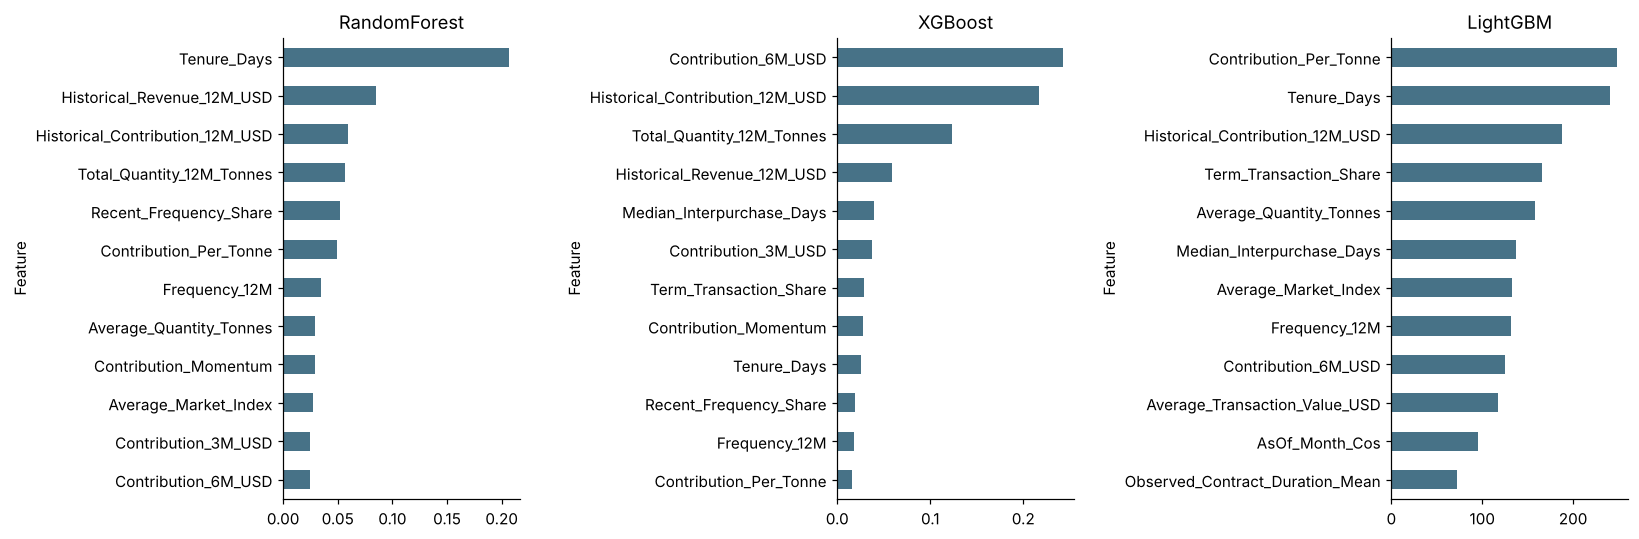

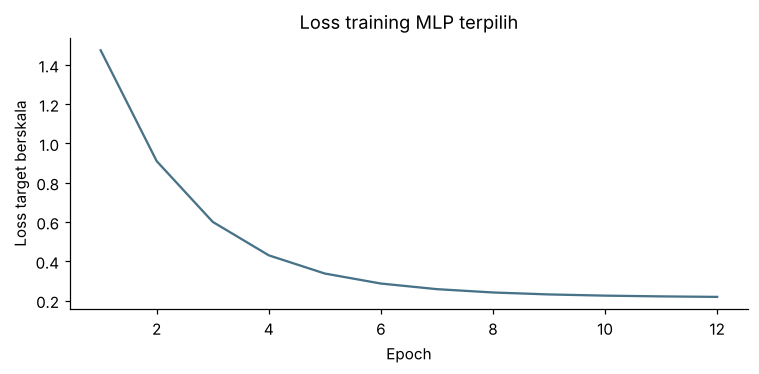

Feature importance bersifat deskriptif; bukan bukti hubungan sebab akibat.


In [52]:
fig,axes=plt.subplots(1,3,figsize=(15,5))
importance_rows=[]
for ax,alg in zip(axes,ALGORITHMS[:3]):
    b=base_bundles[alg]
    imp=pd.DataFrame({'Feature':b['columns'],'Importance':b['model'].feature_importances_}).sort_values('Importance',ascending=False)
    imp.head(12).sort_values('Importance').plot.barh(x='Feature',y='Importance',ax=ax,legend=False,color='#477287')
    ax.set_title(alg);importance_rows.append(imp.assign(Model=alg))
plt.tight_layout();finish_plot('04_tree_feature_importance','models')
save_table(pd.concat(importance_rows,ignore_index=True),'04_tree_feature_importance','models')
fig,ax=plt.subplots(figsize=(7,3.5))
loss=base_bundles['MLP']['model'].loss_curve_
ax.plot(np.arange(1,len(loss)+1),loss,color='#477287')
ax.set(xlabel='Epoch',ylabel='Loss target berskala',title='Loss training MLP terpilih')
plt.tight_layout();finish_plot('05_mlp_training_loss','models')
print('Feature importance bersifat deskriptif; bukan bukti hubungan sebab akibat.')

### 4.10 Simpan matriks dan transformer yang digunakan

In [53]:
model_matrix_summary=[]
for alg,b in base_bundles.items():
    for split,df in parts.items():
        x=b['imputer'].transform(numeric_inputs(df,b['columns'],alg))
        if b['scaler'] is not None:x=b['scaler'].transform(x)
        frame=pd.DataFrame(x,columns=b['columns'])
        frame.insert(0,'Snapshot_ID',df.Snapshot_ID.values)
        save_table(frame,f'X_{alg}_{split.lower()}','export')
        yy=(model_target(df,b['cfg'])-b['target_mean'])/b['target_std']
        save_table(pd.DataFrame({'Snapshot_ID':df.Snapshot_ID,'Transformed_Target':yy}),f'y_{alg}_{split.lower()}','export')
        model_matrix_summary.append({'Model':alg,'Split':split,'Rows':len(frame),'Features':len(b['columns']),
            'Missing_After':int(np.isnan(x).sum()),'Target_Mode':b['cfg']['target_mode']})
display(pd.DataFrame(model_matrix_summary))
save_table(pd.DataFrame(model_matrix_summary),'06_selected_matrix_summary','models')

,Model,Split,Rows,Features,Missing_After,Target_Mode
0,RandomForest,Train,8097,45,0,residual
1,RandomForest,Validation,1573,45,0,residual
2,RandomForest,Test,1572,45,0,residual
3,XGBoost,Train,8097,45,0,tweedie
4,XGBoost,Validation,1573,45,0,tweedie
5,XGBoost,Test,1572,45,0,tweedie
6,LightGBM,Train,8097,45,0,tweedie
7,LightGBM,Validation,1573,45,0,tweedie
8,LightGBM,Test,1572,45,0,tweedie
9,MLP,Train,8097,45,0,direct


### 4.11 Nilai imputasi dan scaling model final
Tabel ini melengkapi bukti penanganan missing value.

In [54]:
imputer_rows=[]
for algorithm,bundle in base_bundles.items():
    train_array=numeric_inputs(parts['Train'],bundle['columns'],algorithm)
    for j,column in enumerate(bundle['columns']):
        value=float(bundle['imputer'].statistics_[j])
        imputer_rows.append({'Model':algorithm,'Feature':column,
            'Missing_Train':int(np.isnan(train_array[:,j]).sum()),
            'Imputation_Space':'signed_log1p' if algorithm=='MLP' else 'original',
            'Fill_In_Model_Space':value,
            'Fill_Original_Units':float(np.sign(value)*np.expm1(abs(value))) if algorithm=='MLP' else value,
            'Scaler_Mean':float(bundle['scaler'].mean_[j]) if bundle['scaler'] is not None else np.nan,
            'Scaler_Scale':float(bundle['scaler'].scale_[j]) if bundle['scaler'] is not None else np.nan})
actual_imputation=pd.DataFrame(imputer_rows)
display(actual_imputation.loc[actual_imputation.Missing_Train.gt(0)])
save_table(actual_imputation,'07_actual_imputer_scaler','models')
print('Statistik di atas berasal dari transformer model final yang dipelajari pada Train.')

,Model,Feature,Missing_Train,Imputation_Space,Fill_In_Model_Space,Fill_Original_Units,Scaler_Mean,Scaler_Scale
13,RandomForest,Avg_Payment_Delay_Days,190,original,5.8571,5.8571,NaN,NaN
25,RandomForest,Average_Price_3M,449,original,83.6694,83.6694,NaN,NaN
26,RandomForest,Average_Price_6M,33,original,84.6367,84.6367,NaN,NaN
32,RandomForest,Median_Interpurchase_Days,214,original,19.5000,19.5000,NaN,NaN
34,RandomForest,Recent_Price_Change,449,original,-0.3413,-0.3413,NaN,NaN
58,XGBoost,Avg_Payment_Delay_Days,190,original,5.8571,5.8571,NaN,NaN
70,XGBoost,Average_Price_3M,449,original,83.6694,83.6694,NaN,NaN
71,XGBoost,Average_Price_6M,33,original,84.6367,84.6367,NaN,NaN
77,XGBoost,Median_Interpurchase_Days,214,original,19.5000,19.5000,NaN,NaN
79,XGBoost,Recent_Price_Change,449,original,-0.3413,-0.3413,NaN,NaN


Statistik di atas berasal dari transformer model final yang dipelajari pada Train.


## 5 Stacking Ensemble
### 5.1 Kandidat meta-learner dan fitur tambahan
Bandingkan empat prediksi saja dengan empat prediksi ditambah fitur historis. Semuanya dipilih melalui Validation.

In [55]:
META_FEATURES=['Historical_Contribution_12M_USD','Contribution_3M_USD','Recent_Frequency_Share',
    'Monthly_Contribution_CV','Remaining_Term_Days_Max','Active_Term_Contract_Count',
    'No_Active_Term_Flag','AsOf_Month_Sin','AsOf_Month_Cos']
meta_specs=([{'kind':'Ridge','alpha':a,'inputs':'predictions_only'} for a in [.1,1.,10.,100.,1000.]]+
    [{'kind':'ElasticNet','alpha':a,'l1_ratio':r,'inputs':'predictions_only'} for a in [.001,.01,.1] for r in [.1,.5]]+
    [{'kind':'Convex','penalty':a,'inputs':'predictions_only'} for a in [0.,.01,.1,1.]])
meta_specs += [{**s,'inputs':'predictions_and_history'} for s in list(meta_specs) if s['kind']!='Convex']
write_json({'meta_candidates':meta_specs,'meta_history_features':META_FEATURES,
    'selection_metric':'Validation RMSE in USD','base_order':ALGORITHMS,
    'outer_folds':'lihat 5.2','inner_folds':2,'test_used_for_tuning':False,
    'prior_test_exposure':True},RUN_DIR/'stacking'/'protocol_before_oof.json')
print('Kandidat meta-learner:',len(meta_specs))
print('Input tambahan kandidat:',META_FEATURES)

Kandidat meta-learner: 26
Input tambahan kandidat: ['Historical_Contribution_12M_USD', 'Contribution_3M_USD', 'Recent_Frequency_Share', 'Monthly_Contribution_CV', 'Remaining_Term_Days_Max', 'Active_Term_Contract_Count', 'No_Active_Term_Flag', 'AsOf_Month_Sin', 'AsOf_Month_Cos']


### 5.2 Rencana fold OOF dan warm-up
Tanggal awal menjadi warm-up bila riwayat pelatihan internal belum cukup. Baris itu tetap tersedia bagi pelatihan base learner. Jumlah blok OOF: 4.

In [56]:
train=parts['Train']
N_OOF_BLOCKS=4
# Periode awal menjadi warm-up karena label dan validasi internal belum cukup.
available_dates=[]
for d in sorted(train.As_Of_Date.unique()):
    d=pd.Timestamp(d)
    idx=np.flatnonzero((train.As_Of_Date.lt(d)&train.Target_End_Date.le(d)).to_numpy())
    if len(idx)>=250 and temporal_folds(train.iloc[idx].reset_index(drop=True),max_folds=1):
        available_dates.append(d)
if len(available_dates)<N_OOF_BLOCKS:raise ValueError('Tanggal untuk OOF bersarang belum cukup.')
blocks=[list(b) for b in np.array_split(np.array(available_dates,dtype=object),N_OOF_BLOCKS) if len(b)]
oof=np.full((len(train),len(ALGORITHMS)),np.nan)
fold_plan=[];nested_logs=[];nested_selected=[]
print('Blok OOF:',len(blocks),'| tanggal tersedia:',len(available_dates))

Blok OOF: 4 | tanggal tersedia: 12


### 5.3 Pelatihan OOF dengan tuning bersarang
Tuning hanya melihat data di dalam training fold. Holdout OOF tidak dipakai untuk early stopping.

In [57]:
for no,dates in enumerate(blocks,1):
    origin=pd.Timestamp(dates[0])
    tr_idx=np.flatnonzero((train.As_Of_Date.lt(origin)&train.Target_End_Date.le(origin)).to_numpy())
    ho_idx=np.flatnonzero(train.As_Of_Date.isin(dates).to_numpy())
    outer_train=train.iloc[tr_idx].reset_index(drop=True)
    assert outer_train.Target_End_Date.max()<=origin
    assert not set(tr_idx).intersection(ho_idx)
    fold_plan.append({'Fold':no,'Holdout_Start':origin,'Holdout_End':pd.Timestamp(dates[-1]),
        'Training_Rows':len(tr_idx),'Holdout_Rows':len(ho_idx),
        'Last_Training_Target_End':outer_train.Target_End_Date.max()})
    save_table(train.iloc[tr_idx][['Snapshot_ID']],f'fold_{no:02d}_train_ids','stacking')
    save_table(train.iloc[ho_idx][['Snapshot_ID']],f'fold_{no:02d}_holdout_ids','stacking')
    for j,algorithm in enumerate(ALGORITHMS):
        cfg,rounds,table,inner=tune_algorithm(algorithm,outer_train,max_folds=2,half_life=SAMPLE_HALF_LIFE)
        b=fit_bundle(algorithm,cfg,outer_train,rounds=rounds,half_life=SAMPLE_HALF_LIFE)
        oof[ho_idx,j]=predict_bundle(b,train.iloc[ho_idx])
        table['Outer_Fold']=no;nested_logs.append(table)
        nested_selected.append({'Outer_Fold':no,'Model':algorithm,'Candidate':cfg['id'],
            'Feature_Set':cfg['feature_set'],'Target_Mode':cfg['target_mode'],'Rounds':rounds,
            'Inner_Folds':len(inner),'Last_Outer_Training_Target':outer_train.Target_End_Date.max(),
            'Holdout_Start':origin})
    print(f'Fold {no}/{len(blocks)}: holdout {len(ho_idx)} baris')
    np.save(RUN_DIR/'stacking'/'oof_checkpoint.npy',oof)
    save_table(pd.DataFrame(fold_plan),'oof_plan_checkpoint','stacking')
    save_table(pd.DataFrame(nested_selected),'nested_choices_checkpoint','stacking')

/home/user/venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/home/user/venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


/home/user/venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/home/user/venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


/home/user/venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/home/user/venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


/home/user/venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


/home/user/venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


/home/user/venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


... (89 outputs left out)

/home/user/venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


/home/user/venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/home/user/venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


/home/user/venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


Fold 4/4: holdout 1125 baris


### 5.4 Audit dan cakupan OOF

In [58]:
fold_plan=pd.DataFrame(fold_plan)
covered=np.isfinite(oof).all(axis=1)
oof_table=train[['Snapshot_ID','Customer_ID','As_Of_Date','Target_End_Date',TARGET]].copy()
for j,a in enumerate(ALGORITHMS):oof_table['Pred_'+a]=oof[:,j]
oof_table['Used_for_Meta']=covered
save_table(fold_plan,'01_temporal_oof_folds','stacking')
save_table(oof_table,'02_oof_predictions','stacking')
save_table(pd.concat(nested_logs,ignore_index=True),'03_nested_tuning','stacking')
display(fold_plan)
print('OOF lengkap:',covered.sum(),'| Warm-up:',(~covered).sum())
print('Warm-up tetap ada pada Train utama; tidak dipakai melatih meta-learner.')
save_table(pd.DataFrame(nested_selected),'09_nested_selected_configs','stacking')
warmup=train.loc[~covered,['Snapshot_ID','Customer_ID','As_Of_Date','Target_End_Date']]
save_table(warmup,'10_warmup_not_used_by_meta','stacking')
assert pd.to_datetime(fold_plan.Last_Training_Target_End).le(pd.to_datetime(fold_plan.Holdout_Start)).all()

,Fold,Holdout_Start,Holdout_End,Training_Rows,Holdout_Rows,Last_Training_Target_End
0,1,2023-10-31,2023-12-31,2119,1054,2023-10-31
1,2,2024-01-31,2024-03-31,3087,1065,2024-01-31
2,3,2024-04-30,2024-06-30,4081,1120,2024-04-30
3,4,2024-07-31,2024-09-30,5142,1125,2024-07-31


OOF lengkap: 4364 | Warm-up: 3733
Warm-up tetap ada pada Train utama; tidak dipakai melatih meta-learner.


### 5.5 Keragaman kesalahan base learner
Korelasi kesalahan yang tinggi dapat membatasi manfaat penggabungan model.

,RandomForest,XGBoost,LightGBM,MLP
RandomForest,1.0000,0.9771,0.9761,0.9454
XGBoost,0.9771,1.0000,0.9853,0.9434
LightGBM,0.9761,0.9853,1.0000,0.9467
MLP,0.9454,0.9434,0.9467,1.0000


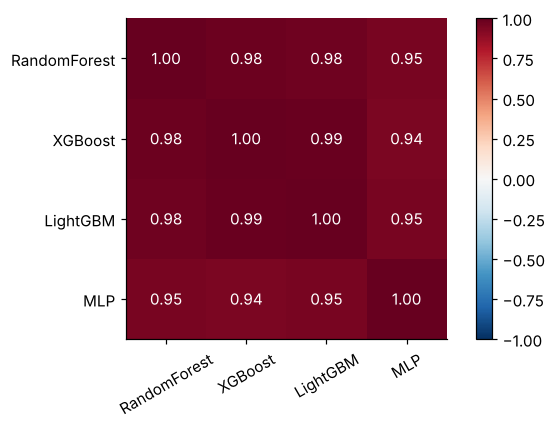

In [59]:
oof_y=train.loc[covered,TARGET].to_numpy()
oof_predictions=oof[covered]
residual_corr=pd.DataFrame(oof_predictions-oof_y[:,None],columns=ALGORITHMS).corr()
display(residual_corr);save_table(residual_corr.reset_index(names='Algorithm'),'04_oof_error_correlation','stacking')
fig,ax=plt.subplots(figsize=(6,4))
im=ax.imshow(residual_corr,vmin=-1,vmax=1,cmap='RdBu_r')
ax.set_xticks(range(4),ALGORITHMS,rotation=30);ax.set_yticks(range(4),ALGORITHMS)
for i in range(4):
    for j in range(4):ax.text(j,i,f'{residual_corr.iloc[i,j]:.2f}',ha='center',va='center',color='white' if abs(residual_corr.iloc[i,j])>.5 else 'black')
fig.colorbar(im,ax=ax);plt.tight_layout();finish_plot('05_oof_error_correlation','stacking')

### 5.6 Fungsi meta-learner
Imputer dan scaler meta dipelajari hanya dari baris OOF yang lengkap.

In [60]:
def meta_design(predictions,frame=None,extra_columns=None):
    x=np.asarray(predictions,dtype=float)/1e6
    cols=list(extra_columns or [])
    if cols:
        if frame is None or len(frame)!=len(x):raise ValueError('Fitur historis meta tidak sesuai baris prediksi.')
        extra=frame[cols].to_numpy(dtype=float)
        extra=np.sign(extra)*np.log1p(np.abs(extra))
        x=np.column_stack([x,extra])
    x[~np.isfinite(x)]=np.nan
    return x
def fit_meta(spec,predictions,y,frame=None):
    cols=META_FEATURES if spec['inputs']=='predictions_and_history' else []
    x=meta_design(predictions,frame,cols);yt=np.asarray(y,dtype=float)/1e6
    names=['Pred_'+a for a in ALGORITHMS]+list(cols)
    if spec['kind']=='Convex':
        def loss(v):return np.mean((x@v[:4]+v[4]-yt)**2)+spec['penalty']*np.sum((v[:4]-.25)**2)
        result=minimize(loss,np.r_[np.repeat(.25,4),0.],method='SLSQP',bounds=[(0.,1.)]*4+[(None,None)],
            constraints=[{'type':'eq','fun':lambda v:v[:4].sum()-1}],options={'maxiter':1000,'ftol':1e-10})
        if not result.success:raise RuntimeError(result.message)
        return {'spec':spec,'weights':result.x[:4],'intercept':result.x[4],
            'extra_columns':[],'feature_names':names}
    imp=SimpleImputer(strategy='median',keep_empty_features=True).fit(x)
    xx=imp.transform(x);scaler=StandardScaler().fit(xx)
    model=(Ridge(alpha=spec['alpha']) if spec['kind']=='Ridge' else
        ElasticNet(alpha=spec['alpha'],l1_ratio=spec['l1_ratio'],max_iter=30000,random_state=SEED))
    model.fit(scaler.transform(xx),yt)
    return {'spec':spec,'imputer':imp,'scaler':scaler,'model':model,
            'extra_columns':list(cols),'feature_names':names}
def predict_meta(bundle,predictions,frame=None):
    x=meta_design(predictions,frame,bundle['extra_columns'])
    if bundle['spec']['kind']=='Convex':p=x@bundle['weights']+bundle['intercept']
    else:p=bundle['model'].predict(bundle['scaler'].transform(bundle['imputer'].transform(x)))
    return np.maximum(p*1e6,0.)

### 5.7 Latih dan pilih stacking
Meta-learner dipilih dengan RMSE Validation dari 26 kandidat. Pada tahap ini konfigurasi belum dikunci, karena keputusan pelatihan ulang (5.10) masih memakai Validation.

In [61]:
valid_matrix=np.column_stack([validation_predictions[a] for a in ALGORITHMS])
meta_results=[];meta_bundles=[]
for no,spec in enumerate(meta_specs):
    b=fit_meta(spec,oof_predictions,oof_y,train.loc[covered])
    meta_bundles.append(b)
    meta_results.append({'Candidate':no,**spec,**scores(parts['Validation'][TARGET],predict_meta(b,valid_matrix,parts['Validation']))})
meta_results=pd.DataFrame(meta_results).sort_values(['RMSE_USD','MAE_USD']).reset_index(drop=True)
meta_choice=int(meta_results.iloc[0].Candidate)
meta_bundle=meta_bundles[meta_choice]
stack_valid=predict_meta(meta_bundle,valid_matrix,parts['Validation'])
display(meta_results.head(10))
print('Meta-learner dipilih:',meta_bundle['spec'])
save_table(meta_results,'06_meta_validation','stacking')
# Selisih RMSE antarkandidat meta jauh lebih kecil dari ketidakpastian Validation; dilaporkan sebagai konteks.
yv=parts['Validation'][TARGET].to_numpy()
g=pd.DataFrame({'c':parts['Validation'].Customer_ID,'se':(yv-stack_valid)**2,'n':1}).groupby('c').sum()
rng=np.random.default_rng(SEED);boot_rmse=[]
for _ in range(1000):
    i=rng.integers(0,len(g),len(g));boot_rmse.append(np.sqrt(g.se.to_numpy()[i].sum()/g.n.to_numpy()[i].sum()))
meta_se=float(np.std(boot_rmse))
print(f'SE bootstrap RMSE stacking Validation: USD {meta_se:,.0f}; kandidat meta dalam 1-SE: '
      f'{int(meta_results.RMSE_USD.le(meta_results.RMSE_USD.iloc[0]+meta_se).sum())} dari {len(meta_results)}')
joblib.dump({'base_models':base_bundles,'meta':meta_bundle,'base_order':ALGORITHMS,'target':TARGET,
    'horizon_months':HORIZON,'history_days':HISTORY_DAYS,'dataset_sha256':DATASET_SHA256,
    'meta_history_features':META_FEATURES,'feature_sets':FEATURE_SETS,'trained_on':'Train'},
    RUN_DIR/'models'/'stacking_bundle_train_only.joblib')

,Candidate,kind,alpha,inputs,MAE_USD,RMSE_USD,R2,l1_ratio,penalty
0,4,Ridge,"1,000.0000",predictions_only,"659,699.2902","957,377.9138",0.7188,NaN,NaN
1,25,ElasticNet,0.1000,predictions_and_history,"651,489.9618","958,845.7243",0.7180,0.5000,NaN
2,10,ElasticNet,0.1000,predictions_only,"657,485.4222","958,914.4811",0.7179,0.5000,NaN
3,9,ElasticNet,0.1000,predictions_only,"657,008.5580","959,348.1683",0.7177,0.1000,NaN
4,19,Ridge,"1,000.0000",predictions_and_history,"655,290.7865","959,959.9571",0.7173,NaN,NaN
5,24,ElasticNet,0.1000,predictions_and_history,"653,744.9123","961,668.5780",0.7163,0.1000,NaN
6,14,Convex,NaN,predictions_only,"675,417.8671","962,029.1654",0.7161,NaN,1.0000
7,13,Convex,NaN,predictions_only,"673,182.5586","962,418.0951",0.7159,NaN,0.1000
8,12,Convex,NaN,predictions_only,"672,754.1852","964,164.2214",0.7148,NaN,0.0100
9,3,Ridge,100.0000,predictions_only,"656,546.3798","964,219.2206",0.7148,NaN,NaN


Meta-learner dipilih: {'kind': 'Ridge', 'alpha': 1000.0, 'inputs': 'predictions_only'}
SE bootstrap RMSE stacking Validation: USD 55,645; kandidat meta dalam 1-SE: 26 dari 26


['hasil_skripsi_v3/c54a270360_standard_v3/models/stacking_bundle_train_only.joblib']

### 5.8 Perbandingan OOF dan koefisien meta-learner

,Model,MAE_USD,RMSE_USD,R2
1,XGBoost,"872,229.7762","1,282,279.2632",0.6253
2,LightGBM,"881,235.2523","1,292,192.0350",0.6194
0,RandomForest,"883,484.6264","1,293,369.3266",0.6187
3,MLP,"890,833.6332","1,337,235.0484",0.5925


,Input,Coefficient,Unit
0,Pred_RandomForest,0.2880,USD per USD prediksi
1,Pred_XGBoost,0.2958,USD per USD prediksi
2,Pred_LightGBM,0.2588,USD per USD prediksi
3,Pred_MLP,0.2237,USD per USD prediksi


Intercept: USD -120,944.67
Koefisien linear bukan persentase kontribusi dan dapat bernilai negatif.


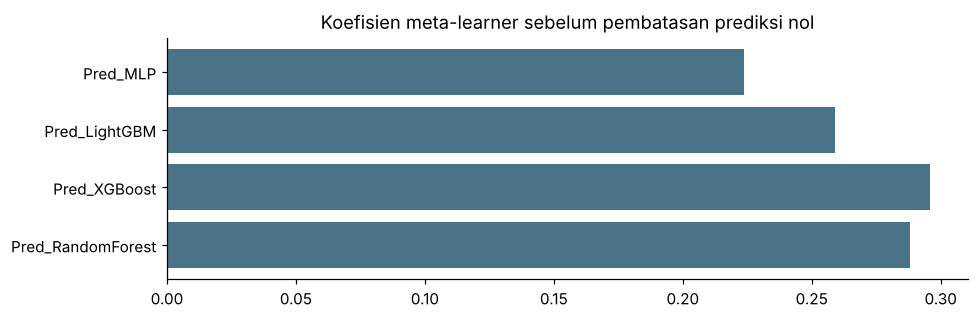

In [62]:
oof_scores=pd.DataFrame([{'Model':a,**scores(oof_y,oof_predictions[:,j])}
    for j,a in enumerate(ALGORITHMS)]).sort_values('RMSE_USD')
display(oof_scores);save_table(oof_scores,'07_oof_base_metrics','stacking')
if meta_bundle['spec']['kind']=='Convex':
    coefficients=meta_bundle['weights'];intercept_usd=meta_bundle['intercept']*1e6
else:
    coefficients=meta_bundle['model'].coef_/meta_bundle['scaler'].scale_
    intercept_usd=(meta_bundle['model'].intercept_-np.dot(coefficients,meta_bundle['scaler'].mean_))*1e6
coef_table=pd.DataFrame({'Input':meta_bundle['feature_names'],'Coefficient':coefficients})
coef_table['Unit']=['USD per USD prediksi']*4+['Juta USD per unit signed-log1p fitur']*(len(coef_table)-4)
display(coef_table);print(f'Intercept: USD {intercept_usd:,.2f}')
print('Koefisien linear bukan persentase kontribusi dan dapat bernilai negatif.')
save_table(coef_table,'08_meta_coefficients','stacking')
fig,ax=plt.subplots(figsize=(9,max(3,.35*len(coef_table))))
ax.barh(coef_table.Input,coef_table.Coefficient,color='#477287');ax.axvline(0,color='gray')
ax.set_title('Koefisien meta-learner sebelum pembatasan prediksi nol')
plt.tight_layout();finish_plot('11_meta_coefficients','stacking')

### 5.9 Kontribusi fitur historis pada stacking

In [63]:
meta_input_comparison=meta_results.sort_values('RMSE_USD').groupby('inputs',as_index=False).first()
display(meta_input_comparison[['inputs','kind','RMSE_USD','MAE_USD','R2']])
save_table(meta_input_comparison,'12_meta_input_comparison_validation','stacking')
print('Jenis input terpilih:',meta_bundle['spec']['inputs'])

,inputs,kind,RMSE_USD,MAE_USD,R2
0,predictions_and_history,ElasticNet,"958,845.7243","651,489.9618",0.7180
1,predictions_only,Ridge,"957,377.9138","659,699.2902",0.7188


Jenis input terpilih: predictions_only


### 5.10 Uji mundur kebaruan data di Validation
Model untuk Test dapat dilatih hanya dari Train (tanggal acuan terakhir 2024-09-30, berjarak 15 bulan dari Test) atau dari Train+Validation (tanggal acuan terakhir 2025-06-30, berjarak 6 bulan, jarak minimum yang diizinkan purge). Keputusan diambil tanpa Test dengan meniru kedua kondisi itu pada Validation:
- **basi**: konfigurasi terpilih dilatih pada Train dengan tanggal acuan ≤ 2023-12-31, yaitu 15 bulan sebelum Validation;
- **segar**: konfigurasi yang sama dilatih pada seluruh Train (6 bulan sebelum Validation).

Meta-learner terpilih dipakai tanpa diubah. Pelatihan ulang dipakai bila stacking segar lebih baik daripada stacking basi, dengan bootstrap per customer yang mendukung arah tersebut (P(selisih<0) ≥ 0,8).

In [64]:
STALE_LAST=pd.Timestamp('2023-12-31')
stale_train=train.loc[train.As_Of_Date.le(STALE_LAST)].reset_index(drop=True)
backtest_pred={'Basi':{},'Segar':{}}
for a in ALGORITHMS:
    cfg,r=base_choices[a]['config'],base_choices[a]['rounds']
    backtest_pred['Basi'][a]=predict_bundle(fit_bundle(a,cfg,stale_train,rounds=r,half_life=SAMPLE_HALF_LIFE),parts['Validation'])
    backtest_pred['Segar'][a]=validation_predictions[a]   # model Train penuh dari bagian 4
for k in backtest_pred:
    m=np.column_stack([backtest_pred[k][a] for a in ALGORITHMS])
    backtest_pred[k]['Stacking']=predict_meta(meta_bundle,m,parts['Validation'])
backtest=pd.DataFrame([{'Model':a,'Kondisi':k,**scores(yv,backtest_pred[k][a])}
    for a in ALGORITHMS+['Stacking'] for k in ['Basi','Segar']])
display(backtest.pivot(index='Model',columns='Kondisi',values=['RMSE_USD','R2']))
def customer_bootstrap(y,p_a,p_b,customers,n=1000,seed=SEED):
    # Selisih RMSE (a - b) dengan resampling per customer.
    g=pd.DataFrame({'c':np.asarray(customers),'a':(np.asarray(y)-p_a)**2,'b':(np.asarray(y)-p_b)**2,'n':1}).groupby('c').sum()
    A,B,N=g.a.to_numpy(),g.b.to_numpy(),g.n.to_numpy();rng=np.random.default_rng(seed);out=[]
    for _ in range(n):
        i=rng.integers(0,len(g),len(g));out.append(np.sqrt(A[i].sum()/N[i].sum())-np.sqrt(B[i].sum()/N[i].sum()))
    out=np.array(out)
    return {'delta':float(np.sqrt(A.sum()/N.sum())-np.sqrt(B.sum()/N.sum())),'ci_low':float(np.percentile(out,2.5)),
            'ci_high':float(np.percentile(out,97.5)),'p_neg':float((out<0).mean())}
recency_test=customer_bootstrap(yv,backtest_pred['Segar']['Stacking'],backtest_pred['Basi']['Stacking'],parts['Validation'].Customer_ID)
RETRAIN_ON_TRAIN_VALIDATION=bool(recency_test['delta']<0 and recency_test['p_neg']>=.8)
print('Stacking segar - basi (RMSE USD):',{k:round(v,3) for k,v in recency_test.items()})
print('Latih ulang pada Train+Validation:',RETRAIN_ON_TRAIN_VALIDATION,f'(baris basi: {len(stale_train)})')
save_table(backtest,'13_recency_backtest_validation','stacking')
write_json({'stale_last_asof':STALE_LAST,'bootstrap':recency_test,'retrain':RETRAIN_ON_TRAIN_VALIDATION},
    RUN_DIR/'stacking'/'recency_backtest_decision.json')

/home/user/venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


RMSE_USD                  R2       
Kondisi                Basi        Segar   Basi  Segar
Model                                                 
LightGBM       990,224.8505 968,223.8917 0.6992 0.7124
MLP          1,006,972.2212 985,299.2224 0.6890 0.7022
RandomForest 1,005,796.9472 968,972.9761 0.6897 0.7120
Stacking       978,236.5153 957,377.9138 0.7065 0.7188
XGBoost      1,005,191.4784 975,585.6203 0.6901 0.7080

Stacking segar - basi (RMSE USD): {'delta': -20858.602, 'ci_low': -47834.623, 'ci_high': 5077.609, 'p_neg': 0.945}
Latih ulang pada Train+Validation: True (baris basi: 4787)


### 5.11 Pelatihan ulang model final
Bila 5.10 mendukung, setiap base learner dilatih ulang pada Train+Validation dengan konfigurasi dan jumlah iterasi yang sama. Purge tetap terpenuhi: target Validation terakhir selesai 2025-12-31, tepat pada tanggal acuan Test pertama. Meta-learner (spesifikasi sama) dilatih ulang pada gabungan OOF Train dan prediksi Validation dari model Train, yang keduanya merupakan prediksi di luar data latih model dasarnya. Bila 5.10 tidak mendukung, model final adalah model Train dari bagian 4 dan 5.7.

In [65]:
if RETRAIN_ON_TRAIN_VALIDATION:
    train_valid=pd.concat([parts['Train'],parts['Validation']],ignore_index=True)
    assert train_valid.Target_End_Date.max()<=TEST_START
    final_base={a:fit_bundle(a,base_choices[a]['config'],train_valid,rounds=base_choices[a]['rounds'],
                             half_life=SAMPLE_HALF_LIFE) for a in ALGORITHMS}
    meta_x=np.vstack([oof_predictions,valid_matrix])
    meta_y=np.concatenate([oof_y,yv])
    meta_frame=pd.concat([train.loc[covered],parts['Validation']],ignore_index=True)
    final_meta=fit_meta(meta_bundle['spec'],meta_x,meta_y,meta_frame)
    final_trained_on='Train+Validation'
else:
    final_base,final_meta,final_trained_on=base_bundles,meta_bundle,'Train'
for a,b in final_base.items():joblib.dump(b,RUN_DIR/'models'/f'{a}_final.joblib')
if final_meta['spec']['kind']=='Convex':
    final_coef=final_meta['weights']
else:
    final_coef=final_meta['model'].coef_[:len(ALGORITHMS)]/final_meta['scaler'].scale_[:len(ALGORITHMS)]
print('Model final dilatih pada:',final_trained_on)
print('Koefisien meta final (USD per USD prediksi):',dict(zip(ALGORITHMS,np.round(final_coef,4))))

Model final dilatih pada: Train+Validation
Koefisien meta final (USD per USD prediksi): {'RandomForest': np.float64(0.2814), 'XGBoost': np.float64(0.2918), 'LightGBM': np.float64(0.2579), 'MLP': np.float64(0.2345)}


### 5.12 Kunci konfigurasi sebelum Test
Seluruh pilihan (konfigurasi base learner, meta-learner, keputusan pelatihan ulang, model K-Means) disimpan, lalu hash SHA-256-nya dicatat. Bagian 6.1 memeriksa hash ini sebelum membaca Test. Holdout Test pernah dilihat pada percobaan sebelumnya, sehingga bukan sampel eksternal baru; v3 tidak membuka Test sebelum langkah ini.

In [66]:
final_bundle={'base_models':final_base,'meta':final_meta,'base_order':ALGORITHMS,'target':TARGET,
    'horizon_months':HORIZON,'history_days':HISTORY_DAYS,'dataset_sha256':DATASET_SHA256,
    'meta_history_features':META_FEATURES,'feature_sets':FEATURE_SETS,'trained_on':final_trained_on,
    'kmeans':cluster_bundle,'seed':SEED,'versions':versions}
joblib.dump(final_bundle,RUN_DIR/'models'/'stacking_bundle.joblib')
selection={'base_models':base_choices,'meta':meta_bundle['spec'],'kmeans':cluster_choice.to_dict(),
    'early_stopping':ES_MODE,'sample_half_life_months':SAMPLE_HALF_LIFE,'oof_blocks':len(blocks),
    'retrain_on_train_validation':RETRAIN_ON_TRAIN_VALIDATION,'recency_backtest':recency_test,
    'validation_stacking_train_models':scores(yv,stack_valid),
    'test_used_for_tuning':False,'prior_test_exposure':'Holdout penelitian yang sama telah dipakai pada percobaan sebelumnya; bukan sampel eksternal baru.'}
write_json(selection,RUN_DIR/'stacking'/'selection_locked_before_test.json')
SELECTION_HASH=hashlib.sha256((RUN_DIR/'stacking'/'selection_locked_before_test.json').read_bytes()).hexdigest()
(RUN_DIR/'stacking'/'selection_hash.txt').write_text(SELECTION_HASH)
print('Konfigurasi dikunci sebelum evaluasi Test:',SELECTION_HASH)

Konfigurasi dikunci sebelum evaluasi Test: 1f28426d1f1faecb65614409f4438349a02c9773ca55a0fbb43be83747454eca


## 6 Evaluation
### 6.1 Evaluasi regresi pada Test (satu kali)
Hash konfigurasi diperiksa terlebih dahulu. Baris Validation memakai model yang dilatih pada Train (dasar seleksi). Baris Test memakai model final dari 5.11. Semua model dan pembanding dinilai pada baris Test yang sama dalam satu sel ini, dan tidak ada keputusan yang diambil dari skor Test.

In [67]:
assert hashlib.sha256((RUN_DIR/'stacking'/'selection_locked_before_test.json').read_bytes()).hexdigest()==SELECTION_HASH
test=parts['Test']
test_predictions={a:predict_bundle(final_base[a],test) for a in ALGORITHMS}
test_matrix=np.column_stack([test_predictions[a] for a in ALGORITHMS])
test_predictions['Stacking']=predict_meta(final_meta,test_matrix,test)
test_predictions['Mean_Ensemble']=test_matrix.mean(axis=1)
test_predictions['Historical_12M']=test.Baseline_12M_USD.to_numpy()
test_predictions['Recent_6M']=test.Baseline_Recent6M_USD.to_numpy()
mean_source=pd.concat([parts['Train'],parts['Validation']]) if RETRAIN_ON_TRAIN_VALIDATION else parts['Train']
test_predictions['Train_Mean']=np.repeat(mean_source[TARGET].mean(),len(test))
validation_all={**validation_predictions,'Stacking':stack_valid,'Mean_Ensemble':valid_matrix.mean(axis=1),
    'Historical_12M':parts['Validation'].Baseline_12M_USD.to_numpy(),
    'Recent_6M':parts['Validation'].Baseline_Recent6M_USD.to_numpy(),
    'Train_Mean':np.repeat(parts['Train'][TARGET].mean(),len(parts['Validation']))}
evaluation=pd.DataFrame([{'Split':s,'Model':a,**scores(frame[TARGET],p)}
    for s,frame,preds in [('Validation',parts['Validation'],validation_all),('Test',test,test_predictions)] for a,p in preds.items()])
evaluation['Trained_On']=np.where(evaluation.Split.eq('Validation'),'Train',final_trained_on)
final_table=evaluation.pivot(index='Model',columns='Split',values=['MAE_USD','RMSE_USD','R2'])
final_table=final_table.reindex(ALGORITHMS+['Stacking','Mean_Ensemble','Historical_12M','Recent_6M','Train_Mean'])
display(final_table)
test_metrics=evaluation.loc[evaluation.Split.eq('Test')].sort_values('RMSE_USD')
save_table(evaluation,'01_regression_metrics','evaluation')
predictions=test[['Snapshot_ID','Customer_ID','As_Of_Date',TARGET]].copy()
for a,p in test_predictions.items():predictions['Pred_'+a]=p
save_table(predictions,'02_test_predictions','evaluation')
train_metrics=[{'Model':a,**scores(parts['Train'][TARGET],predict_bundle(b,parts['Train']))} for a,b in base_bundles.items()]
display(pd.DataFrame(train_metrics))
save_table(pd.DataFrame(train_metrics),'03_train_fit_metrics','evaluation')
print('Train adalah skor in-sample model Train; bandingkan dengan Validation dan Test untuk menilai overfit.')

/home/user/venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


MAE_USD                      RMSE_USD                 \
Split                    Test     Validation           Test     Validation   
Model                                                                        
RandomForest     703,616.0151   681,248.8302 1,025,676.6135   968,972.9761   
XGBoost          720,890.1889   673,987.0046 1,055,733.2617   975,585.6203   
LightGBM         717,501.0404   671,658.7531 1,052,756.0749   968,223.8917   
MLP              765,084.3927   697,353.6944 1,102,613.7427   985,299.2224   
Stacking         705,805.7967   659,699.2902 1,032,838.0157   957,377.9138   
Mean_Ensemble    716,854.5128   672,183.2279 1,045,704.6506   961,529.1723   
Historical_12M   731,485.0932   760,547.0466 1,089,331.9435 1,103,306.7171   
Recent_6M        812,967.2439   815,595.0938 1,229,416.0377 1,209,461.7814   
Train_Mean     1,609,691.8010 1,522,138.5028 2,026,844.4392 1,866,578.1773   

                    R2             
Split             Test Validation  
Model                              
RandomForest    0.7410     0.7120  
XGBoost         0.7256     0.7080  
LightGBM        0.7272     0.7124  
MLP             0.7007     0.7022  
Stacking        0.7374     0.7188  
Mean_Ensemble   0.7308     0.7164  
Historical_12M  0.7079     0.6266  
Recent_6M       0.6279     0.5513  
Train_Mean     -0.0112    -0.0688

/home/user/venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


,Model,MAE_USD,RMSE_USD,R2
0,RandomForest,"569,544.3308","858,556.2134",0.8296
1,XGBoost,"774,780.2137","1,114,721.9439",0.7128
2,LightGBM,"719,488.1850","1,033,888.8745",0.7529
3,MLP,"858,324.3783","1,225,917.1102",0.6526


Train adalah skor in-sample model Train; bandingkan dengan Validation dan Test untuk menilai overfit.


### 6.2 Evaluasi segmentasi pada Test
Silhouette, DBI, dan CH dinilai pada ruang fitur K-Means yang sudah dipilih.

In [68]:
cluster_test=latest_customer(test)
cluster_test_x=cluster_transform(cluster_bundle['preprocessor'],cluster_test)
cluster_test_labels=cluster_bundle['model'].predict(cluster_test_x)
clustering_eval=pd.DataFrame([
    {'Split':'Train','Rows':len(cluster_train),**cluster_metrics(cluster_transform(cluster_bundle['preprocessor'],cluster_train),labels_train)},
    {'Split':'Validation','Rows':len(cluster_valid),**cluster_metrics(cluster_transform(cluster_bundle['preprocessor'],cluster_valid),
        cluster_bundle['model'].predict(cluster_transform(cluster_bundle['preprocessor'],cluster_valid)))},
    {'Split':'Test','Rows':len(cluster_test),**cluster_metrics(cluster_test_x,cluster_test_labels)}])
display(clustering_eval);save_table(clustering_eval,'04_clustering_metrics','evaluation')

,Split,Rows,Silhouette,DBI,CH,Min_Share
0,Train,375,0.3376,1.1898,225.9918,0.4640
1,Validation,397,0.3509,1.1213,270.5677,0.4786
2,Test,397,0.3572,1.0742,279.5075,0.4861


### 6.3 Grafik perbandingan model

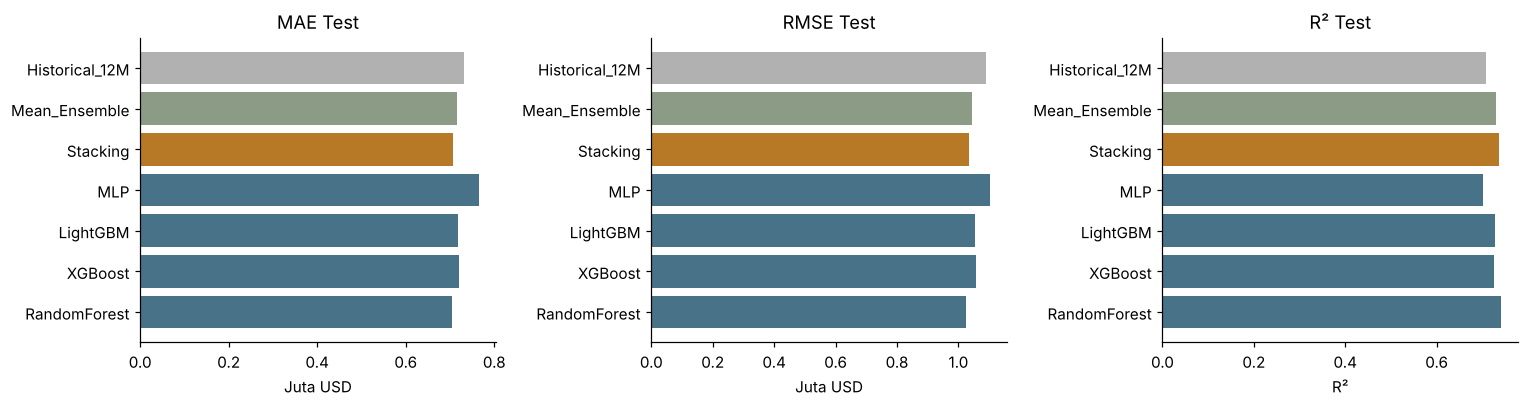

In [69]:
fig,ax=plt.subplots(1,3,figsize=(14,3.8))
plot_metrics=test_metrics.set_index('Model').loc[ALGORITHMS+['Stacking','Mean_Ensemble','Historical_12M']]
for a,col,title in zip(ax,['MAE_USD','RMSE_USD','R2'],['MAE Test','RMSE Test','R² Test']):
    vals=plot_metrics[col]/1e6 if col.endswith('USD') else plot_metrics[col]
    a.barh(plot_metrics.index,vals,color=['#477287']*4+['#b87927','#8c9b86','#b1b1b1'])
    a.set_title(title);a.set_xlabel('Juta USD' if col.endswith('USD') else 'R²')
plt.tight_layout();finish_plot('08_model_comparison','evaluation')

### 6.4 Aktual, prediksi, dan residual stacking

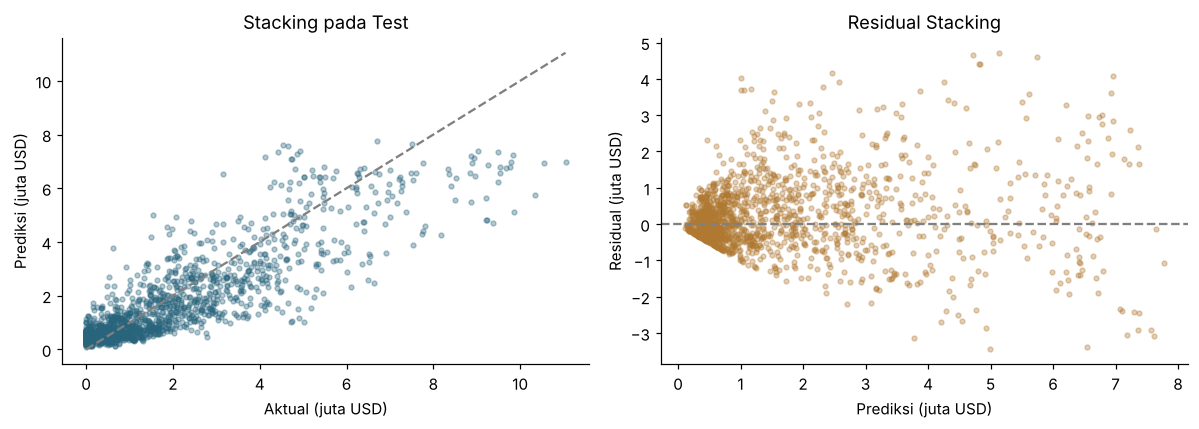

In [70]:
fig,ax=plt.subplots(1,2,figsize=(11,4))
y=test[TARGET].to_numpy();p=test_predictions['Stacking']
ax[0].scatter(y/1e6,p/1e6,s=10,alpha=.35,color='#28647c')
lim=max(y.max(),p.max())/1e6;ax[0].plot([0,lim],[0,lim],'--',color='gray')
ax[0].set(xlabel='Aktual (juta USD)',ylabel='Prediksi (juta USD)',title='Stacking pada Test')
ax[1].scatter(p/1e6,(y-p)/1e6,s=10,alpha=.35,color='#b07932');ax[1].axhline(0,color='gray',ls='--')
ax[1].set(xlabel='Prediksi (juta USD)',ylabel='Residual (juta USD)',title='Residual Stacking')
plt.tight_layout();finish_plot('09_stacking_actual_residual','evaluation')

### 6.5 Kinerja menurut tanggal acuan

In [71]:
by_date=pd.DataFrame([{'As_Of_Date':d,**scores(g[TARGET],g.Pred_Stacking)} for d,g in predictions.groupby('As_Of_Date')])
display(by_date);save_table(by_date,'10_stacking_by_date','evaluation')

,As_Of_Date,MAE_USD,RMSE_USD,R2
0,2025-12-31,"663,471.3245","963,298.5650",0.7667
1,2026-01-31,"739,102.9014","1,082,991.1103",0.7151
2,2026-02-28,"761,214.2654","1,124,412.7620",0.7084
3,2026-03-31,"659,231.4604","949,319.9073",0.7639


### 6.6 Perbandingan berpasangan dan bootstrap
Resampling dilakukan per customer karena satu customer dapat muncul pada beberapa snapshot.

In [72]:
best_base=base_validation.iloc[0].Model
y=test[TARGET].to_numpy()
delta_rows=[]
for a in ALGORITHMS:
    sb=scores(y,test_predictions[a]);ss=scores(y,test_predictions['Stacking'])
    delta_rows.append({'Base_Model':a,'RMSE_Reduction_pct':100*(sb['RMSE_USD']-ss['RMSE_USD'])/sb['RMSE_USD'],
        'MAE_Reduction_pct':100*(sb['MAE_USD']-ss['MAE_USD'])/sb['MAE_USD']})
display(pd.DataFrame(delta_rows));save_table(pd.DataFrame(delta_rows),'11_stacking_differences','evaluation')
boot_rows=[]
for split,yy,pred,frame in [('Validation',yv,validation_all,parts['Validation']),('Test',y,test_predictions,test)]:
    for comp in ALGORITHMS+['Mean_Ensemble','Historical_12M']:
        bs=customer_bootstrap(yy,pred['Stacking'],pred[comp],frame.Customer_ID)
        boot_rows.append({'Split':split,'Pembanding':comp,'Delta_RMSE_USD':bs['delta'],'CI95_Low':bs['ci_low'],
                          'CI95_High':bs['ci_high'],'P_Stacking_Lebih_Baik':bs['p_neg']})
bootstrap_table=pd.DataFrame(boot_rows)
display(bootstrap_table)
save_table(bootstrap_table,'14_bootstrap_delta_rmse','evaluation')
main_ci=bootstrap_table.loc[bootstrap_table.Split.eq('Test')&bootstrap_table.Pembanding.eq(best_base)].iloc[0]
print('Base terbaik menurut Validation:',best_base)
print(f'Delta RMSE stacking - {best_base} pada Test (USD), 95% bootstrap CI: [{main_ci.CI95_Low:,.2f}, {main_ci.CI95_High:,.2f}]')
print('Nilai negatif mendukung stacking; CI mencakup nol berarti selisih belum meyakinkan pada bootstrap ini.')
print('Interval ini bersyarat pada periode Test yang tersedia; belum membuktikan kinerja pada periode pasar lain.')
write_json({'comparator_selected_on_validation':best_base,'delta_rmse_bootstrap_95ci':[main_ci.CI95_Low,main_ci.CI95_High],
    'customer_block_resamples':1000},RUN_DIR/'evaluation'/'bootstrap_comparison.json')

,Base_Model,RMSE_Reduction_pct,MAE_Reduction_pct
0,RandomForest,-0.6982,-0.3112
1,XGBoost,2.1687,2.0925
2,LightGBM,1.8920,1.6300
3,MLP,6.3282,7.7480


,Split,Pembanding,Delta_RMSE_USD,CI95_Low,CI95_High,P_Stacking_Lebih_Baik
0,Validation,RandomForest,"-11,595.0624","-25,559.4838","1,127.9312",0.9570
1,Validation,XGBoost,"-18,207.7065","-34,901.0681","1,270.4361",0.9670
2,Validation,LightGBM,"-10,845.9779","-24,932.5721","7,734.8459",0.8820
3,Validation,MLP,"-27,921.3087","-69,033.1656","7,157.3412",0.9420
4,Validation,Mean_Ensemble,"-4,151.2586","-17,082.6718","9,555.4409",0.7170
5,Validation,Historical_12M,"-145,928.8034","-213,030.4271","-78,950.8105",1.0000
6,Test,RandomForest,"7,161.4021","-9,479.8695","21,510.6458",0.2020
7,Test,XGBoost,"-22,895.2460","-36,112.4139","-8,585.3489",0.9990
8,Test,LightGBM,"-19,918.0592","-34,357.5366","-4,713.8693",0.9970
9,Test,MLP,"-69,775.7270","-108,728.0667","-31,256.1693",1.0000


Base terbaik menurut Validation: LightGBM
Delta RMSE stacking - LightGBM pada Test (USD), 95% bootstrap CI: [-34,357.54, -4,713.87]
Nilai negatif mendukung stacking; CI mencakup nol berarti selisih belum meyakinkan pada bootstrap ini.
Interval ini bersyarat pada periode Test yang tersedia; belum membuktikan kinerja pada periode pasar lain.


### 6.7 Pemeriksaan kesalahan prediksi

In [73]:
error_detail=predictions.copy()
error_detail['Absolute_Error']=np.abs(error_detail[TARGET]-error_detail.Pred_Stacking)
error_detail['Residual']=error_detail[TARGET]-error_detail.Pred_Stacking
display(error_detail.sort_values('Absolute_Error',ascending=False).head(15))
save_table(error_detail,'12_error_detail','evaluation')
zero_rows=[]
for label,mask in [('Target_zero',test[TARGET].eq(0)),('Target_positive',test[TARGET].gt(0))]:
    if mask.sum():
        zero_rows.append({'Group':label,'Rows':int(mask.sum()),
            'MAE_USD':mean_absolute_error(test.loc[mask,TARGET],test_predictions['Stacking'][mask]),
            'RMSE_USD':np.sqrt(mean_squared_error(test.loc[mask,TARGET],test_predictions['Stacking'][mask]))})
display(pd.DataFrame(zero_rows));save_table(pd.DataFrame(zero_rows),'13_zero_target_review','evaluation')

,Snapshot_ID,Customer_ID,As_Of_Date,Future_6M_CLV_Proxy_USD,Pred_RandomForest,Pred_XGBoost,Pred_LightGBM,Pred_MLP,Pred_Stacking,Pred_Mean_Ensemble,Pred_Historical_12M,Pred_Recent_6M,Pred_Train_Mean,Absolute_Error,Residual
1412,CUST-0239_2026-03-31,CUST-0239,2026-03-31,"9,850,314.4300","4,987,399.1572","5,205,963.5000","5,221,226.7675","4,197,904.0982","5,132,608.0070","4,903,123.3807","4,848,456.4435","3,004,053.4886","2,101,479.4404","4,717,706.4230","4,717,706.4230"
1272,CUST-0096_2026-03-31,CUST-0096,2026-03-31,"9,365,608.8700","4,680,806.5251","4,586,745.0000","4,539,060.6192","4,306,353.7725","4,715,105.2763","4,528,241.4792","4,820,287.8188","5,113,655.8749","2,101,479.4404","4,650,503.5937","4,650,503.5937"
1022,CUST-0239_2026-02-28,CUST-0239,2026-02-28,"10,347,957.8900","5,564,581.9442","5,670,449.0000","5,845,469.5959","4,843,608.5562","5,743,038.2424","5,481,027.2741","5,524,012.2368","4,276,038.0854","2,101,479.4404","4,604,919.6476","4,604,919.6476"
881,CUST-0096_2026-02-28,CUST-0096,2026-02-28,"9,242,495.5900","4,803,690.0458","4,601,170.0000","4,545,312.3752","4,599,659.9103","4,824,298.5417","4,637,458.0828","4,874,353.8756","4,885,758.4725","2,101,479.4404","4,418,197.0483","4,418,197.0483"
487,CUST-0096_2026-01-31,CUST-0096,2026-01-31,"9,218,965.1100","4,772,190.5743","4,566,832.0000","4,554,865.6027","4,648,865.3620","4,819,418.1166","4,635,688.3848","4,926,810.1578","4,633,446.9651","2,101,479.4404","4,399,546.9934","4,399,546.9934"
1046,CUST-0264_2026-02-28,CUST-0264,2026-02-28,"6,625,966.7400","2,499,318.8718","2,434,606.2500","2,496,366.1794","2,236,481.1044","2,460,820.3236","2,416,693.1014","2,230,277.1247","2,586,455.5724","2,101,479.4404","4,165,146.4164","4,165,146.4164"
617,CUST-0228_2026-01-31,CUST-0228,2026-01-31,"11,044,796.4800","6,984,389.6968","6,512,100.0000","6,496,088.2492","6,585,554.4367","6,964,567.7046","6,644,533.0957","9,421,772.7325","8,393,608.2034","2,101,479.4404","4,080,228.7754","4,080,228.7754"
1080,CUST-0299_2026-02-28,CUST-0299,2026-02-28,"5,014,863.1800","1,105,210.5759","897,343.7500","983,233.8501","1,279,271.2166","1,005,099.6719","1,066,264.8481","1,218,915.5304","573,974.6357","2,101,479.4404","4,009,763.5081","4,009,763.5081"
997,CUST-0214_2026-02-28,CUST-0214,2026-02-28,"6,491,488.8100","2,597,814.8212","2,395,527.5000","2,415,293.7236","2,719,625.3390","2,569,535.8626","2,532,065.3459","2,701,114.3253","2,605,422.7058","2,101,479.4404","3,921,952.9474","3,921,952.9474"
1449,CUST-0276_2026-03-31,CUST-0276,2026-03-31,"8,169,120.9900","4,892,190.6129","3,771,186.5000","4,091,494.4685","3,574,980.1991","4,249,621.6025","4,082,462.9451","4,409,080.3676","2,387,164.4978","2,101,479.4404","3,919,499.3875","3,919,499.3875"


,Group,Rows,MAE_USD,RMSE_USD
0,Target_zero,102,"451,886.9788","494,940.9453"
1,Target_positive,1470,"723,424.6535","1,060,083.1945"


## 7 Customer Value Profile
### 7.1 Gabungkan label segmen dan prediksi
Profil menghubungkan karakter historis, segmen, dan prediksi enam bulan pada tanggal acuan yang sama.

In [74]:
profile=test[['Snapshot_ID','Customer_ID','As_Of_Date','Frequency_12M','Total_Quantity_12M_Tonnes',
    'Historical_Contribution_12M_USD','Contract_Count_12M','Term_Transaction_Share']].copy()
profile['Cluster']=cluster_bundle['model'].predict(cluster_transform(cluster_bundle['preprocessor'],test))
profile['Predicted_6M_CLV_Proxy_USD']=test_predictions['Stacking']
profile[TARGET]=test[TARGET]
save_table(profile,'05_customer_value_profile','evaluation')
latest_profile=latest_customer(profile)
save_table(latest_profile,'06_latest_customer_value_profile','evaluation')
display(latest_profile.head(10))
cluster_error=pd.DataFrame([{'Cluster':k,'Snapshots':len(g),**scores(g[TARGET],g.Predicted_6M_CLV_Proxy_USD)}
    for k,g in profile.groupby('Cluster')])
display(cluster_error);save_table(cluster_error,'07_regression_by_cluster','evaluation')

,Snapshot_ID,Customer_ID,As_Of_Date,Frequency_12M,Total_Quantity_12M_Tonnes,Historical_Contribution_12M_USD,Contract_Count_12M,Term_Transaction_Share,Cluster,Predicted_6M_CLV_Proxy_USD,Future_6M_CLV_Proxy_USD
0,CUST-0172_2025-12-31,CUST-0172,2025-12-31,1,58000,497640,1,1.0000,1,"229,511.4914","136,519.3700"
1,CUST-0377_2026-01-31,CUST-0377,2026-01-31,1,46000,382260,1,0.0000,1,"179,437.4480",0.0000
2,CUST-0002_2026-02-28,CUST-0002,2026-02-28,1,56000,238000,1,1.0000,1,"150,953.6497",0.0000
3,CUST-0065_2026-02-28,CUST-0065,2026-02-28,1,58000,457620,1,0.0000,1,"202,010.3457","425,624.9500"
4,CUST-0135_2026-02-28,CUST-0135,2026-02-28,1,41000,262400,1,0.0000,1,"234,257.9198","488,782.0600"
5,CUST-0001_2026-03-31,CUST-0001,2026-03-31,7,239000,2140510,6,0.2857,1,"739,467.0607","1,236,737.4100"
6,CUST-0003_2026-03-31,CUST-0003,2026-03-31,9,178000,934450,5,0.6667,1,"557,403.1421","1,599,674.7300"
7,CUST-0004_2026-03-31,CUST-0004,2026-03-31,6,151000,871570,3,0.8333,1,"536,173.9795","318,907.3100"
8,CUST-0005_2026-03-31,CUST-0005,2026-03-31,13,525000,2873210,8,0.5385,1,"849,429.2245","1,413,149.5000"
9,CUST-0006_2026-03-31,CUST-0006,2026-03-31,8,244000,2547010,6,0.5000,1,"1,083,544.9129","784,344.2100"


,Cluster,Snapshots,MAE_USD,RMSE_USD,R2
0,0,768,"1,059,599.2593","1,392,936.3829",0.5669
1,1,804,"367,853.8325","482,026.6445",0.2178


### 7.2 Profil customer terbaru dan ringkasan segmen

In [75]:
profile_with_context=latest_profile.merge(master[['Customer_ID','Customer_Name','Country']],on='Customer_ID',validate='one_to_one')
display(profile_with_context[['Customer_ID','Customer_Name','Country','As_Of_Date','Cluster','Predicted_6M_CLV_Proxy_USD']].head(15))
save_table(profile_with_context,'01_latest_profile_with_context','customer_profile')
demo_profile=profile_with_context.drop(columns=[TARGET])
save_table(demo_profile,'02_profile_without_future_actual','customer_profile')
segment_value=profile_with_context.groupby('Cluster').agg(Customers=('Customer_ID','size'),
    Median_Predicted_6M_CLV=('Predicted_6M_CLV_Proxy_USD','median'),
    Total_Predicted_6M_CLV=('Predicted_6M_CLV_Proxy_USD','sum'),
    Median_Frequency=('Frequency_12M','median'),Median_Quantity=('Total_Quantity_12M_Tonnes','median')).reset_index()
display(segment_value);save_table(segment_value,'03_segment_value_profile','customer_profile')

,Customer_ID,Customer_Name,Country,As_Of_Date,Cluster,Predicted_6M_CLV_Proxy_USD
0,CUST-0172,Customer 0172,Indonesia,2025-12-31,1,"229,511.4914"
1,CUST-0377,Customer 0377,Indonesia,2026-01-31,1,"179,437.4480"
2,CUST-0002,Customer 0002,Indonesia,2026-02-28,1,"150,953.6497"
3,CUST-0065,Customer 0065,Hong Kong,2026-02-28,1,"202,010.3457"
4,CUST-0135,Customer 0135,Indonesia,2026-02-28,1,"234,257.9198"
5,CUST-0001,Customer 0001,Indonesia,2026-03-31,1,"739,467.0607"
6,CUST-0003,Customer 0003,China,2026-03-31,1,"557,403.1421"
7,CUST-0004,Customer 0004,China,2026-03-31,1,"536,173.9795"
8,CUST-0005,Customer 0005,China,2026-03-31,1,"849,429.2245"
9,CUST-0006,Customer 0006,China,2026-03-31,1,"1,083,544.9129"


,Cluster,Customers,Median_Predicted_6M_CLV,Total_Predicted_6M_CLV,Median_Frequency,Median_Quantity
0,0,193,"2,340,505.9219","548,466,992.5097",21.0000,"652,000.0000"
1,1,204,"484,665.9316","107,265,235.5961",5.0000,"138,500.0000"


### 7.3 Contoh pengamatan berulang satu customer

,Snapshot_ID,Customer_ID,As_Of_Date,Frequency_12M,Total_Quantity_12M_Tonnes,Historical_Contribution_12M_USD,Contract_Count_12M,Term_Transaction_Share,Cluster,Predicted_6M_CLV_Proxy_USD,Future_6M_CLV_Proxy_USD
392,CUST-0400_2025-12-31,CUST-0400,2025-12-31,1,36000,338760,1,1.0000,1,"681,136.4528",0.0000
786,CUST-0400_2026-01-31,CUST-0400,2026-01-31,1,36000,338760,1,1.0000,1,"659,871.3309",0.0000
1179,CUST-0400_2026-02-28,CUST-0400,2026-02-28,1,36000,338760,1,1.0000,1,"649,314.7523",0.0000
1571,CUST-0400_2026-03-31,CUST-0400,2026-03-31,1,36000,338760,1,1.0000,1,"486,817.4094",0.0000


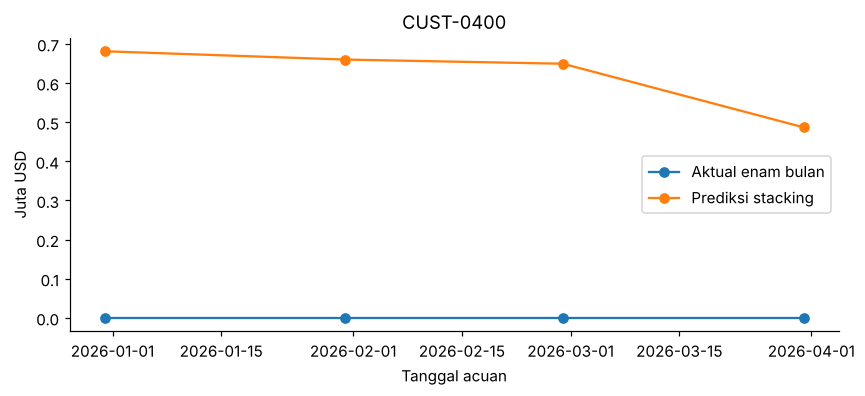

In [76]:
selected_customer=profile.Customer_ID.value_counts().index[0]
customer_view=profile.loc[profile.Customer_ID.eq(selected_customer)].sort_values('As_Of_Date')
display(customer_view)
fig,ax=plt.subplots(figsize=(8,3.7))
ax.plot(customer_view.As_Of_Date,customer_view[TARGET]/1e6,marker='o',label='Aktual enam bulan')
ax.plot(customer_view.As_Of_Date,customer_view.Predicted_6M_CLV_Proxy_USD/1e6,marker='o',label='Prediksi stacking')
ax.set(title=selected_customer,xlabel='Tanggal acuan',ylabel='Juta USD');ax.legend()
plt.tight_layout();finish_plot('04_one_customer_snapshots','customer_profile')

### 7.4 Pemeriksaan artefak untuk Streamlit
`stacking_bundle.joblib` dimuat ulang dari disk, lalu prediksinya dibandingkan dengan prediksi di memori pada baris yang sama. Bila `inference_v3.py` tersedia di folder notebook, modul itu juga diuji, agar aplikasi Streamlit memakai urutan fitur, transformasi, dan meta-learner yang sama.

In [77]:
loaded=joblib.load(RUN_DIR/'models'/'stacking_bundle.joblib')
check_frame=parts['Validation'].head(50)
memory_pred=predict_meta(final_meta,np.column_stack([predict_bundle(final_base[a],check_frame) for a in ALGORITHMS]),check_frame)
disk_pred=predict_meta(loaded['meta'],np.column_stack([predict_bundle(loaded['base_models'][a],check_frame) for a in loaded['base_order']]),check_frame)
assert np.allclose(memory_pred,disk_pred)
if Path('inference_v3.py').exists():
    from inference_v3 import predict_profile
    streamlit_pred=predict_profile(loaded,check_frame)
    assert np.allclose(streamlit_pred.Predicted_6M_CLV_Proxy_USD,memory_pred)
    assert (streamlit_pred.Cluster.to_numpy()==cluster_bundle['model'].predict(cluster_transform(cluster_bundle['preprocessor'],check_frame))).all()
    print('inference_v3.py konsisten dengan notebook untuk',len(check_frame),'snapshot.')
print('Artefak joblib konsisten. Model final dilatih pada:',loaded['trained_on'])

/home/user/venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/home/user/venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


inference_v3.py konsisten dengan notebook untuk 50 snapshot.
Artefak joblib konsisten. Model final dilatih pada: Train+Validation


/home/user/venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


## 8 Ringkasan hasil v3
Sel ini merangkum angka dari sel-sel sebelumnya tanpa angka yang diketik manual: posisi stacking terhadap base learner terbaik, keputusan pelatihan ulang, dan korelasi kesalahan OOF yang membatasi manfaat stacking.

In [78]:
summary_rows=[]
for split in ['Validation','Test']:
    e=evaluation.loc[evaluation.Split.eq(split)].set_index('Model')
    best=e.loc[ALGORITHMS,'RMSE_USD'].idxmin()
    summary_rows.append({'Split':split,'Stacking_R2':e.loc['Stacking','R2'],'Stacking_RMSE':e.loc['Stacking','RMSE_USD'],
        'Base_Terbaik_di_Split':best,'Base_Terbaik_R2':e.loc[best,'R2'],'Base_Terbaik_RMSE':e.loc[best,'RMSE_USD'],
        'Stacking_Unggul':bool(e.loc['Stacking','RMSE_USD']<e.loc[best,'RMSE_USD'])})
summary=pd.DataFrame(summary_rows);display(summary)
save_table(summary,'15_v3_summary','evaluation')
print('Model final dilatih pada:',final_trained_on,'| meta:',meta_bundle['spec'])
print('Rentang korelasi kesalahan OOF antar base learner:',
      round(residual_corr.where(~np.eye(4,dtype=bool)).min().min(),3),'-',round(residual_corr.where(~np.eye(4,dtype=bool)).max().max(),3))
print('Base learner pembanding bootstrap dipilih dari Validation:',best_base)

,Split,Stacking_R2,Stacking_RMSE,Base_Terbaik_di_Split,Base_Terbaik_R2,Base_Terbaik_RMSE,Stacking_Unggul
0,Validation,0.7188,"957,377.9138",LightGBM,0.7124,"968,223.8917",True
1,Test,0.7374,"1,032,838.0157",RandomForest,0.7410,"1,025,676.6135",False


Model final dilatih pada: Train+Validation | meta: {'kind': 'Ridge', 'alpha': 1000.0, 'inputs': 'predictions_only'}
Rentang korelasi kesalahan OOF antar base learner: 0.943 - 0.985
Base learner pembanding bootstrap dipilih dari Validation: LightGBM
